<a id="sec-0"></a>
# Risk Parity + Trend — backtest notebook for the investor prospectus

**Financial Modeling (Nova SBE) · Group project · Moodle group: Group Z**

| Member | Student number |
|---|---|
| Gabriel Depraz | 56900 |
| Marwan El-shazly | 78218 |
| Bruno Francisco Barth | 79727 |
| Tim Jonas Trompa | 64287 |
| Paul Kuehl | 64253 |
| Felix Schoenstein | 80555 |

**Interactive app (Streamlit):** https://groupz-risk-parity-trend.streamlit.app
**Source code (GitHub):** https://github.com/paul2108/04_Financial-Modelin-Group-projects  
**Executed copy as PDF** (all outputs, readable on a phone without running anything): `notebook/GroupZ_RiskParity_Trend.pdf` in the repository

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/paul2108/04_Financial-Modelin-Group-projects/blob/main/notebook/GroupZ_RiskParity_Trend.ipynb)

This notebook reproduces **every number, table and figure** in the prospectus
*“Risk Parity + Trend: a lower-drawdown alternative to the 60/40 portfolio”*.
It follows a standard **ETL** structure:

| Step | Section | What happens |
|---|---|---|
| Extract | [1](#sec-1) | daily prices are fetched from Yahoo Finance through the `yfinance` API (no data files) |
| Transform | [2](#sec-2) | cleaning, month-end sampling, returns, risk-free rate |
| Load | [3](#sec-3) | one aligned `MarketData` object that every later step reads |
| Analysis | [4](#sec-4)–[8](#sec-8) | strategy engine, benchmarks, performance, verification, robustness |
| Machine learning | [9](#sec-9) | walk-forward hidden Markov model (regime filter) against simple rules |
| Extended tests | [9.6](#sec-9-6)–[9.13](#sec-9-13) | HRP, FinBERT on FOMC statements, classifiers with HMM features, leverage, bootstrap and other robustness checks |
| Improvement tests | [9.14](#sec-9-14)–[9.21](#sec-9-21) | hysteresis and no-trade bands, tranche rebalancing, out-of-sample test on 1992–2007 proxies, TIP, leverage financing, EUR investor, deflated Sharpe ratio |
| Export | [10](#sec-10) | figures, tables and the number register used by the LaTeX prospectus |
| Runtime | [11](#sec-11) | how long each section took |

### How to run
* **Google Colab:** open the notebook (badge above) and choose *Runtime → Run all*.
  The first cell installs `quantstats` (not pre-installed on Colab) and a current `yfinance`.
  A full run takes about 2–3 minutes (Sections 9.6–9.13 also download FOMC statements from federalreserve.gov and the FinBERT model from Hugging Face). The HMM fits use all CPU cores, and a local run keeps the FOMC pages and FinBERT scores in `notebook/cache/`, so a rerun takes about 1 minute (`GROUPZ_NO_CACHE=1` switches the cache off). Progress bars show the remaining time.
* **Locally:** `make venv` and then `make notebook` in the repository (see `README.md`).
  Only a local run writes the export files for the prospectus.

Yahoo Finance revises adjusted prices from time to time (e.g. when dividends are re-booked).
A re-run may therefore differ from the prospectus in the last decimal. The data fingerprint in
[Section 2](#sec-2) and the retrieval time stamp in the number register document the exact data vintage.

**Version of 23 Nov 2026.** Changes against the version used for the prospectus draft: (1) Section 9 reports the stress-period gate in Table 3, the base rate of stress months, and alarm shares on the same 236 months as recall and precision; (2) new Sections 9.6–9.13 with further ML models (HRP, FinBERT, classifiers using the HMM as a feature) and robustness checks. Sections 1–8 and the strategy itself are unchanged. (3) Review fix (P. Kuehl, 23 Nov 2026): in Section 9.8 the borrowing cost is now charged only on the exposure above own capital (L × risky share − 1); before, (L − 1) was charged even in months the strategy held mostly T-bills. The FinBERT model revision is printed for reproducibility. (4) Runtime (P. Kuehl, 23 Nov 2026): yearly HMM fits run in parallel on all CPU cores (`N_JOBS`), FOMC pages are downloaded four at a time, and pages and FinBERT labels are cached locally. Results are unchanged. (5) Improvement tests (P. Kuehl, 23 Nov 2026): new Sections 9.14–9.21 test the follow-up proposals (hysteresis and no-trade bands, tranche rebalancing with a daily engine, an out-of-sample test of variant H on 1992–2007 proxy data, TIP, leverage financing, a EUR investor, the deflated Sharpe ratio). FinBERT uses the Apple-silicon GPU (MPS) or a CUDA GPU when available. Sections 1–9.13, the strategy and the prospectus numbers are unchanged.

<a id="sec-0-1"></a>
## 0.1 Setup

In [1]:
# Install packages that Google Colab does not ship (quantstats, hmmlearn) and make sure yfinance is current.
# Locally the project's .venv already contains everything (see requirements.txt).
IN_COLAB = "google.colab" in str(get_ipython())   # IPython built-in: no import needed before the import cell
if IN_COLAB:
    !pip -q install "quantstats==0.0.86" "yfinance>=1.8" "hmmlearn==0.3.3"

In [2]:
# Import packages: every package used in this notebook is imported here, once.
# Mandatory packages of the assignment
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import fsolve
import yfinance as yf
import pandas as pd
import quantstats as qs

# Additional packages: statsmodels (Newey-West t-statistics) and the standard library
import statsmodels.api as sm
from scipy.stats import multivariate_normal
from scipy.stats import norm as std_normal  # standard normal distribution (deflated Sharpe ratio)

# Machine-learning extension (Section 9): hidden Markov model, scaling, progress bars
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # threads of scikit-learn models; more is slower on this small data
import hmmlearn
import sklearn
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
from joblib import Parallel, delayed   # runs the yearly HMM fits on all CPU cores

import json
import logging
import platform
import time
import warnings
from dataclasses import dataclass, replace
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="quantstats")
N_JOBS = os.cpu_count() or 1       # worker processes for the yearly HMM fits (all cores); results do not depend on it
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

# Versions used for this run (table)
for name, mod in [("python", platform), ("numpy", np), ("pandas", pd), ("yfinance", yf),
                  ("quantstats", qs), ("statsmodels", sm), ("hmmlearn", hmmlearn), ("scikit-learn", sklearn)]:
    version = platform.python_version() if name == "python" else mod.__version__
    print(f"{name:<12}{version}")

python      3.12.16
numpy       2.5.5
pandas      3.1.1
yfinance    1.8.0
quantstats  0.0.86
statsmodels 0.15.0
hmmlearn    0.3.3
scikit-learn1.9.1


/Users/paulkuehl/Documents/GitHub/04_Financial-Modeling/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="sec-0-2"></a>
## 0.2 Parameters

All assumptions of the backtest sit in this one cell. The **sample period is set explicitly**:
daily data from `START` up to (but excluding) `END`. yfinance treats `end` as exclusive, so the last
month in the sample is October 2026. The strategy parameters are fixed **in advance** from the
literature: Faber's (2007) 10-month moving average and a standard one-year (252 trading days) risk estimate.
They are not tuned on this sample. [Section 8](#sec-8) shows how sensitive the results are to them.

In [3]:
# ---------------------------------------------------------------- parameters
START = "2006-01-01"              # first day of daily data (inclusive)
END = "2026-11-01"                # last day of daily data (exclusive) -> last month = Oct 2026

RISKY_ASSETS = ["SPY", "EFA", "IEF", "VNQ", "DBC", "GLD"]   # the six asset classes held
BENCHMARK_6040 = {"SPY": 0.60, "AGG": 0.40}                  # balanced benchmark (investable)
MARKET = "^SP500TR"               # S&P 500 total return index: market proxy for CAPM alpha/beta
RF_TICKER = "^IRX"                # 13-week US T-bill yield (% p.a.): risk-free rate and cash return
OTHER_TICKERS = ["AGG", MARKET]   # benchmark building blocks that the strategy does not hold
ALL_TICKERS = RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER]

COV_WINDOW = 252                  # trading days used to estimate the covariance matrix
SMA_WINDOW = 10                   # months in the trend filter's moving average (Faber, 2007)
COST_BPS = 10.0                   # transaction cost in basis points per unit of turnover
WEIGHTING = "erc"                 # "erc" (equal risk contribution), "inverse_vol" or "equal"
NW_LAGS = 4                       # Newey-West lags for the t-statistic of alpha
PERIODS = 12                      # monthly data -> 12 periods per year

ASSET_NAMES = {
    "SPY": "US equities (S&P 500)",
    "EFA": "Developed ex-US equities",
    "IEF": "US Treasuries 7-10y",
    "VNQ": "US real estate (REITs)",
    "DBC": "Broad commodities",
    "GLD": "Gold",
    "CASH": "T-bills (cash)",
    "AGG": "US aggregate bonds",
    "^SP500TR": "S&P 500 total return",
}

REPO_URL = "https://github.com/paul2108/04_Financial-Modelin-Group-projects"
APP_URL = "https://groupz-risk-parity-trend.streamlit.app"
NOTEBOOK_VIEW_URL = ("https://nbviewer.org/github/paul2108/04_Financial-Modelin-Group-projects/"
                     "blob/main/notebook/GroupZ_RiskParity_Trend.ipynb")

<a id="sec-0-3"></a>
## 0.3 Helpers: number register and chart style

The prospectus does not contain a single hand-typed result. Every number, table and figure it
shows is **registered** here when it is computed. Each entry records:
* the value,
* a description,
* the notebook section that produced it,
* the data source (API and tickers),
* the time the data was retrieved.

[Section 9](#sec-9) prints the full register and exports it as `results_macros.tex`. In LaTeX the
command `\res{key}` prints the value and links it to the *Sources of figures* table in the appendix.

In [4]:
REGISTER = []   # filled while the notebook runs, exported in Section 10

# --- runtime tracking: every section calls checkpoint(); Section 11 prints the durations ----------
RUN_START = time.perf_counter()
CHECKPOINTS = [("0 Setup", RUN_START)]


def checkpoint(label):
    """Mark the start of a notebook section (used for the runtime table at the end)."""
    CHECKPOINTS.append((label, time.perf_counter()))


def fmt_value(value, kind):
    """Return (plain text, LaTeX) representations of a result."""
    if kind == "pct0":      # 0.05 -> 5%
        txt = f"{100 * value:.0f}%"
    elif kind == "pct1":    # 0.0734 -> 7.3%
        txt = f"{100 * value:.1f}%"
    elif kind == "pct2":
        txt = f"{100 * value:.2f}%"
    elif kind == "pp1":     # percentage points
        txt = f"{100 * value:.1f} pp"
    elif kind == "num2":
        txt = f"{value:.2f}"
    elif kind == "num1":
        txt = f"{value:.1f}"
    elif kind == "x2":      # growth multiple
        txt = f"{value:.2f}x"
    elif kind == "bps0":
        txt = f"{value:.0f} bps"
    elif kind == "int":
        txt = f"{int(value):,}"
    elif kind == "date":
        txt = pd.Timestamp(value).strftime("%b %Y")
    elif kind == "day":
        txt = pd.Timestamp(value).strftime("%d %b %Y")
    else:                   # free text
        txt = str(value)
    tex = (txt.replace("%", r"\%").replace("x", r"$\times$") if kind == "x2" else txt.replace("%", r"\%"))
    if txt.startswith("-"):
        tex = "$-$" + tex[1:]
    return txt, tex


def register(key, value, kind, description, section, sources):
    """Store a result for the prospectus. `section` is e.g. '6.1'; `sources` lists the tickers used."""
    txt, tex = fmt_value(value, kind)
    entry = dict(key=key, value=txt, tex=tex, raw=value if np.isscalar(value) else str(value),
                 description=description, section=section, sources=list(sources))
    REGISTER[:] = [e for e in REGISTER if e["key"] != key] + [entry]
    return txt


def register_item(key, label_tex, description, section, sources):
    """Register a figure or table (its 'value' is the LaTeX cross-reference, e.g. Fig.~\\ref{fig:cum})."""
    entry = dict(key=key, value=description, tex=label_tex, raw=None,
                 description=description, section=section, sources=list(sources))
    REGISTER[:] = [e for e in REGISTER if e["key"] != key] + [entry]


# --- chart style (validated categorical palette, legends below the plot, recessive grid) ----------
COLORS = {"Strategy": "#2a78d6", "60/40": "#eb6834", "S&P 500 TR": "#1baf7a",
          "ERC (no trend)": "#eda100", "1/N (no trend)": "#6250d6"}
ASSET_COLORS = {"SPY": "#2a78d6", "EFA": "#eb6834", "IEF": "#1baf7a", "VNQ": "#eda100",
                "DBC": "#e87ba4", "GLD": "#008300", "CASH": "#c3c2b7"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2,
    "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 1.6, "font.family": "DejaVu Sans", "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "figure.constrained_layout.use": False,
})
FIG_W = 6.77  # inches = text width of the prospectus (A4, 1.9 cm margins)


def legend_below(fig, ax, ncol=4):
    """Legend centred below the plot (figures use layout="constrained")."""
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=ncol, frameon=False)


# --- export targets: only a local run inside the repository writes files for the prospectus -------
NB_DIR = Path.cwd()
REPO_ROOT = next((p for p in [NB_DIR, *NB_DIR.parents]
                  if (p / "prospectus").is_dir() and (p / "app").is_dir()), None)
EXPORT = (not IN_COLAB) and REPO_ROOT is not None
if EXPORT:
    FIG_DIR, TAB_DIR = REPO_ROOT / "prospectus" / "figures", REPO_ROOT / "prospectus" / "tables"
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TAB_DIR.mkdir(parents=True, exist_ok=True)
print("Export to prospectus:", f"yes -> {REPO_ROOT}" if EXPORT else "no (Colab or outside the repository)")


def save_figure(fig, name):
    if EXPORT:
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")


def save_table(tex, name):
    if EXPORT:
        (TAB_DIR / f"{name}.tex").write_text(tex, encoding="utf-8")

Export to prospectus: yes -> /Users/paulkuehl/Documents/GitHub/04_Financial-Modeling


<a id="sec-1"></a>
## 1 Extract — daily prices from the Yahoo Finance API

**Source:** Yahoo Finance, accessed through the open-source `yfinance` package (one batched request).

**Instruments:**
* the six ETFs the strategy holds,
* `AGG` for the bond leg of the 60/40 benchmark,
* the S&P 500 total-return index `^SP500TR` (CAPM market proxy),
* the 13-week T-bill yield `^IRX` (risk-free rate).

**Adjustment:** `auto_adjust=True` returns close prices adjusted for splits **and** distributions.
Returns computed from them are therefore total returns, net of each ETF's expense ratio, which is
already deducted from the fund's NAV.

**Frequency:** daily. Month-end values are derived in [Section 2](#sec-2).

In [5]:
# ---------------------------------------------------------------- extract
def download_prices(tickers, start, end, retries=3, pause=5.0):
    """EXTRACT: daily split- and dividend-adjusted close prices from Yahoo Finance.

    One batched yfinance call (fewer requests -> fewer rate-limit problems); `end` is exclusive.
    The columns come back in the order of `tickers` (yfinance itself sorts them alphabetically).
    """
    tickers = list(tickers)
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(tickers, start=start, end=end, interval="1d",
                              auto_adjust=True, progress=False, threads=True)
            if raw is not None and not raw.empty:
                close = raw["Close"]
                if isinstance(close, pd.Series):          # single ticker -> Series
                    close = close.to_frame(tickers[0])
                close = close.reindex(columns=tickers)
                missing = [t for t in tickers if close[t].notna().sum() == 0]
                if not missing:
                    return close
                last_error = RuntimeError(f"no data returned for {missing}")
        except Exception as exc:                          # network / rate-limit errors
            last_error = exc
        if attempt < retries:
            time.sleep(pause * attempt)
    raise RuntimeError(f"Download from Yahoo Finance failed after {retries} attempts: {last_error}")

In [6]:
checkpoint("1 Extract")
DATA_RETRIEVED_UTC = pd.Timestamp.now(tz="UTC").floor("min")
prices_raw = download_prices(ALL_TICKERS, START, END)
RETRIEVED_TXT = DATA_RETRIEVED_UTC.strftime("%Y-%m-%d %H:%M UTC")
register("data_retrieved", RETRIEVED_TXT, "text", "Time stamp of the Yahoo Finance download", "1", ALL_TICKERS)

print(f"Retrieved {RETRIEVED_TXT}")
print("Raw shape (rows, columns):", prices_raw.shape)
print("Raw date range:", prices_raw.index.min().date(), "to", prices_raw.index.max().date())
prices_raw.tail(3)

Retrieved 2026-11-23 22:49 UTC
Raw shape (rows, columns): (5240, 9)
Raw date range: 2006-01-03 to 2026-10-30


Ticker,SPY,EFA,IEF,VNQ,DBC,GLD,AGG,^SP500TR,^IRX
Date,,,,,,,,,
2026-10-28,772.309998,103.680000,90.542084,91.790001,33.790001,373.510010,95.549667,17377.560547,3.995
2026-10-29,769.359985,104.349998,90.940727,93.870003,33.720001,368.570007,95.808746,17324.679688,3.998
2026-10-30,755.719971,103.370003,91.448997,93.940002,33.610001,355.779999,96.017998,17011.140625,3.973


In [7]:
# Raw-data checks: first available date and missing values per ticker
raw_check = pd.DataFrame({
    "first valid date": prices_raw.apply(lambda s: s.first_valid_index().date()),
    "last valid date": prices_raw.apply(lambda s: s.last_valid_index().date()),
    "non-missing days": prices_raw.notna().sum(),
    "missing days": prices_raw.isna().sum(),
})
raw_check

,first valid date,last valid date,non-missing days,missing days
Ticker,,,,
SPY,2006-01-03,2026-10-30,5240,0
EFA,2006-01-03,2026-10-30,5240,0
IEF,2006-01-03,2026-10-30,5240,0
VNQ,2006-01-03,2026-10-30,5240,0
DBC,2006-02-06,2026-10-30,5217,23
GLD,2006-01-03,2026-10-30,5240,0
AGG,2006-01-03,2026-10-30,5240,0
^SP500TR,2006-01-03,2026-10-30,5240,0
^IRX,2006-01-03,2026-10-30,5237,3


The late inception of **DBC (February 2006)** produces the missing days at the start of the sample.
All other tickers have only isolated gaps. These are mostly days on which an index (`^IRX`,
`^SP500TR`) and the ETFs do not quote at the same time. Nothing is filled at this stage.

<a id="sec-2"></a>
## 2 Transform — clean, sample at month-end, compute returns

| Step | Rule |
|---|---|
| Time zone | removed (`tz_localize(None)`) so that all series align on calendar dates |
| Duplicates | duplicate dates dropped, index sorted |
| Month-end sampling | last available daily close of each calendar month (`resample("ME").last()`). We do not use yfinance's `interval="1mo"`, whose bars are labelled at the start of the month and may include a partial month. |
| Returns | **simple** returns $R_t = P_t/P_{t-1}-1$. A portfolio's return is then exactly the weighted sum of its assets' returns, $R_{p,t}=\sum_i w_{i}R_{i,t}$. Log returns add up over time, but not across assets. |
| Daily returns for risk estimates | computed only on days on which all held ETFs trade. No price is filled forward. |
| Risk-free rate | `^IRX` is an annualised yield in percent. Monthly cash return in month $t$: $r_{f,t} = \text{IRX}_{t-1}/1200$, the yield observed at the end of the previous month. It is therefore known when the cash is invested. Isolated missing quotes are filled forward for at most 5 days. |

In [8]:
# ---------------------------------------------------------------- transform & load
@dataclass
class MarketData:
    """LOAD: the clean, aligned data that every later step reads."""
    prices_d: pd.DataFrame   # daily adjusted close prices (all tickers incl. ^IRX yield)
    rets_d: pd.DataFrame     # daily simple returns of the tradable tickers
    prices_m: pd.DataFrame   # month-end prices of the tradable tickers
    rets_m: pd.DataFrame     # monthly simple returns, labelled with the month they are earned in
    rf_m: pd.Series          # risk-free return earned in month t (known at the end of month t-1)


def clean_prices(raw):
    """TRANSFORM: tz-naive sorted daily index without duplicates or empty rows."""
    p = raw.copy()
    p.index = pd.to_datetime(p.index)
    if p.index.tz is not None:
        p.index = p.index.tz_localize(None)
    p = p[~p.index.duplicated(keep="last")].sort_index()
    return p.dropna(how="all")


def to_month_end(prices):
    """Last available daily observation of every calendar month (labelled with the month-end date)."""
    return prices.resample("ME").last()


def rf_from_irx(irx):
    """^IRX (13-week T-bill yield, % p.a.) -> monthly cash return earned in the FOLLOWING month."""
    irx_m = to_month_end(irx.ffill(limit=5))
    return (irx_m / 1200).shift(1).rename("rf")


def build_market_data(prices_raw, risky, others, rf_ticker="^IRX"):
    """TRANSFORM + LOAD: everything the strategy, benchmarks and metrics need."""
    p = clean_prices(prices_raw)
    tradables = list(risky) + list(others)
    prices_d = p[tradables + [rf_ticker]]
    rets_d = prices_d[tradables].pct_change(fill_method=None)
    prices_m = to_month_end(prices_d[tradables])
    rets_m = prices_m.pct_change(fill_method=None)
    rf_m = rf_from_irx(prices_d[rf_ticker]).reindex(prices_m.index)
    return MarketData(prices_d=prices_d, rets_d=rets_d, prices_m=prices_m, rets_m=rets_m, rf_m=rf_m)

In [9]:
checkpoint("2 Transform")
data = build_market_data(prices_raw, RISKY_ASSETS, OTHER_TICKERS, RF_TICKER)

# The "four checks" of Lecture 3 on the transformed data: shape, date range, missing values, plot
print("Daily prices   :", data.prices_d.shape, data.prices_d.index.min().date(), "to", data.prices_d.index.max().date())
print("Month-end data :", data.prices_m.shape, data.prices_m.index.min().date(), "to", data.prices_m.index.max().date())
assert data.prices_m.index[-1] == pd.Timestamp("2026-10-31"), "last month must be October 2026"
assert data.prices_d.index[-1] <= pd.Timestamp("2026-10-31"), "no partial November data"
assert data.prices_m.index.is_month_end.all()
print("\nMissing month-end values per ticker (only before inception):")
print(data.prices_m.isna().sum().to_string())

Daily prices   : (5240, 9) 2006-01-03 to 2026-10-30
Month-end data : (250, 8) 2006-01-31 to 2026-10-31

Missing month-end values per ticker (only before inception):
Ticker
SPY         0
EFA         0
IEF         0
VNQ         0
DBC         1
GLD         0
AGG         0
^SP500TR    0


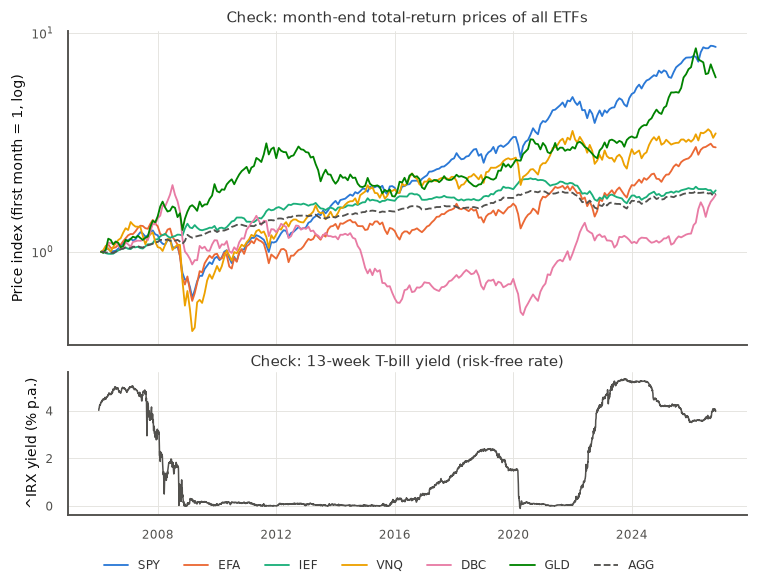

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 5.2), sharex=True, height_ratios=[2.2, 1], layout="constrained")
norm = data.prices_m[RISKY_ASSETS + ["AGG"]].apply(lambda s: s / s.dropna().iloc[0])
for col in RISKY_ASSETS + ["AGG"]:
    axes[0].plot(norm.index, norm[col], color=ASSET_COLORS.get(col, INK_2),
                 lw=1.2, label=col, ls="-" if col != "AGG" else "--")
axes[0].set_yscale("log")
axes[0].set_ylabel("Price index (first month = 1, log)")
axes[0].set_title("Check: month-end total-return prices of all ETFs")
legend_below(fig, axes[0], ncol=7)
axes[1].plot(data.prices_d.index, data.prices_d[RF_TICKER], color=INK_2, lw=1)
axes[1].set_ylabel("^IRX yield (% p.a.)")
axes[1].set_title("Check: 13-week T-bill yield (risk-free rate)", pad=4)
plt.show()

**Data fingerprint.** First and last observations of every series document the data vintage.
If Yahoo revises its history, this table changes and so would the results.

In [11]:
fingerprint = pd.DataFrame({
    "first date": data.prices_d.apply(lambda s: s.first_valid_index().date()),
    "first value": data.prices_d.apply(lambda s: s.dropna().iloc[0]).round(4),
    "last date": data.prices_d.apply(lambda s: s.last_valid_index().date()),
    "last value": data.prices_d.apply(lambda s: s.dropna().iloc[-1]).round(4),
    "daily obs": data.prices_d.notna().sum(),
})
fingerprint

,first date,first value,last date,last value,daily obs
Ticker,,,,,
SPY,2006-01-03,86.7854,2026-10-30,755.7200,5240
EFA,2006-01-03,33.6204,2026-10-30,103.3700,5240
IEF,2006-01-03,48.2562,2026-10-30,91.4490,5240
VNQ,2006-01-03,25.6024,2026-10-30,93.9400,5240
DBC,2006-02-06,19.1851,2026-10-30,33.6100,5217
GLD,2006-01-03,53.1200,2026-10-30,355.7800,5240
AGG,2006-01-03,52.0341,2026-10-30,96.0180,5240
^SP500TR,2006-01-03,1918.9600,2026-10-30,17011.1406,5240
^IRX,2006-01-03,4.0200,2026-10-30,3.9730,5237


<a id="sec-3"></a>
## 3 Load — the sample the analysis uses

The strategy can decide only once every input exists:
* 252 complete daily returns for the covariance matrix,
* 10 month-end prices for each moving average.

DBC, the youngest ETF, sets the start. **The first decision is taken at the close of
28 February 2007, and the first return is earned in March 2007.** Every strategy variant,
benchmark and robustness check uses exactly this window, so that all of them are evaluated
on the same months.

<a id="sec-4"></a>
## 4 Strategy engine

Every month-end $t$, at the closing price, the strategy takes three steps:

1. **Risk estimate.** Estimate the covariance matrix $\Sigma_t$ of the six ETFs from the last
   252 daily returns up to and including $t$.
2. **Risk parity.** Choose weights so that every asset class contributes the same share of
   portfolio risk (equal risk contribution, ERC; Maillard, Roncalli & Teïletche, 2010):
   $$RC_i = \frac{w_i(\Sigma w)_i}{w^\top\Sigma w} = \frac{1}{N}\qquad i=1,\dots,N .$$
   The weights have no closed form, so we solve the nonlinear system with **`scipy.optimize.fsolve`**.
   Following Spinu (2013), ERC holds exactly when $(\Sigma x)_i - \tfrac{1}{N x_i}=0$ for all $i$. These
   are the first-order conditions of a strictly convex problem, so the positive solution is unique.
   We solve them in log-coordinates $x=e^{y}$, which keeps every weight positive, and set
   $w=x/\sum_i x_i$. A test on 2,000 random covariance matrices converged every time.
   The starting value is the inverse-volatility portfolio. Every solution is checked: if the risk
   contributions are not equal to within $10^{-8}$, the month falls back to inverse-volatility
   weights and the fallback is counted.
3. **Trend filter.** An asset class is held only if its month-end price is above its 10-month
   simple moving average (Faber, 2007). Otherwise its risk-parity weight is moved into T-bills (cash).

The new weights earn the returns of month $t+1$: **decide at $t$, earn $t+1$** (the `shift(1)` rule
of Lecture 4). Between two rebalancing dates the holdings drift with prices. At each rebalancing,
the traded amount (turnover) is the distance between the target weights and the drifted weights:
$$TO_t=\sum_{i\in\text{ETFs}}\left|w_{i,t}-\tilde w_{i,t}\right|,\qquad
\tilde w_{i,t}=\frac{w_{i,t-1}(1+R_{i,t})}{1+R_{p,t}} .$$
Trading costs $c$ per unit of turnover reduce the portfolio value before the next month's return:
$V_{t+1}=V_t\,(1-c\cdot TO_t)\,(1+R_{p,t+1})$. Switching into and out of T-bills is assumed to be free,
as it is in a money-market sweep account.

In [12]:
# ---------------------------------------------------------------- strategy: risk parity weights
def inverse_vol_weights(cov):
    """Weights proportional to 1/volatility (the ERC solution when correlations are zero)."""
    iv = 1.0 / np.sqrt(np.diag(np.asarray(cov, dtype=float)))
    return iv / iv.sum()


def risk_contributions(w, cov):
    """Share of portfolio variance contributed by each asset (sums to 1)."""
    w = np.asarray(w, dtype=float)
    cov = np.asarray(cov, dtype=float)
    return w * (cov @ w) / (w @ cov @ w)


def erc_weights(cov, tol=1e-8):
    """Equal-risk-contribution weights, solved with scipy's fsolve (Spinu, 2013).

    ERC holds when x_i (S x)_i = 1/N for all i, i.e. when (S x)_i - 1/(N x_i) = 0: the first-order
    condition of the convex problem min 0.5 x'Sx - (1/N) sum(log x_i). We solve these N equations in
    log-coordinates x = exp(y) > 0, so the weights stay positive, and return w = x / sum(x).
    Returns (weights, ok). If the solution fails the check, inverse-vol weights are returned and ok=False.
    """
    cov = np.atleast_2d(np.asarray(cov, dtype=float))
    n = cov.shape[0]
    S = cov / np.mean(np.diag(cov))                 # rescale: the solution does not depend on the scale
    iv = 1.0 / np.sqrt(np.diag(S))
    x0 = iv / np.sqrt(iv @ S @ iv)                  # inverse-vol start, scaled so that x0' S x0 = 1

    def equations(y):
        x = np.exp(y)
        return S @ x - 1.0 / (n * x)

    def jacobian(y):                                # d equations_i / d y_j
        x = np.exp(y)
        return S * x[None, :] + np.diag(1.0 / (n * x))

    y, _info, ier, _msg = fsolve(equations, np.log(x0), fprime=jacobian, full_output=True, xtol=1e-12)
    w = np.exp(y)
    w = w / w.sum()
    ok = bool(ier == 1 and np.all(np.isfinite(w))
              and np.max(np.abs(risk_contributions(w, cov) - 1.0 / n)) < tol)
    if not ok:
        return inverse_vol_weights(cov), False
    return w, True

In [13]:
# ---------------------------------------------------------------- strategy: trend filter and target weights
def trend_signal(prices_m, window=10):
    """1.0 if the month-end price is above its `window`-month SMA (incl. the current month), 0.0 if not,
    NaN while the moving average is not yet available."""
    sma = prices_m.rolling(window, min_periods=window).mean()
    return (prices_m > sma).astype(float).where(sma.notna())


def first_decision_date(data, assets, cov_window=252, sma_window=10):
    """First month-end at which the covariance window and every moving average are complete."""
    assets = list(assets)
    px = data.prices_d[assets].dropna()
    first_cov = px.index[cov_window]                 # cov_window returns need cov_window + 1 prices
    first_sig = trend_signal(data.prices_m[assets], sma_window).dropna().index[0]
    months = data.prices_m.index
    return months[(months >= first_cov) & (months >= first_sig)][0]


def target_weights(data, assets, decision_dates, cov_window=252, sma_window=10,
                   use_trend=True, weighting="erc"):
    """Target weights decided at each month-end (rows) for the assets plus CASH (columns).

    Only information up to and including the decision date is used.
    """
    assets = list(assets)
    px = data.prices_d[assets].dropna()              # days on which all held ETFs trade
    rd = px.pct_change(fill_method=None).iloc[1:]
    sig = trend_signal(data.prices_m[assets], sma_window)
    rows, fallbacks = [], 0
    for t in decision_dates:
        window = rd.loc[:t].iloc[-cov_window:]
        if len(window) < cov_window:
            raise ValueError(f"{t.date()}: only {len(window)} daily returns available, need {cov_window}")
        cov = np.atleast_2d(np.cov(window.to_numpy(), rowvar=False))
        if weighting == "erc":
            w, ok = erc_weights(cov)
            fallbacks += int(not ok)
        elif weighting == "inverse_vol":
            w = inverse_vol_weights(cov)
        elif weighting == "equal":
            w = np.full(len(assets), 1.0 / len(assets))
        else:
            raise ValueError(f"unknown weighting '{weighting}'")
        w = pd.Series(w, index=assets, dtype=float)
        if use_trend:
            on = sig.loc[t, assets]
            if on.isna().any():
                raise ValueError(f"{t.date()}: trend signal not yet available")
            w = w.where(on == 1.0, 0.0)
        w["CASH"] = 1.0 - w.sum()
        rows.append(w.rename(t))
    W = pd.DataFrame(rows)
    W.index.name = "decision_date"
    W.attrs["fsolve_fallbacks"] = fallbacks
    return W


def constant_weights(weights, decision_dates):
    """Fixed-mix target weights (e.g. 60/40), rebalanced back to target at every decision date."""
    w = pd.Series(weights, dtype=float)
    if "CASH" not in w.index:
        w["CASH"] = 1.0 - w.sum()
    cols = [c for c in w.index if c != "CASH"] + ["CASH"]
    W = pd.DataFrame([w[cols].to_numpy()] * len(decision_dates),
                     index=pd.DatetimeIndex(decision_dates, name="decision_date"), columns=cols)
    W.attrs["fsolve_fallbacks"] = 0
    return W

In [14]:
# ---------------------------------------------------------------- backtest engine
def backtest(weights, data, cost_bps=10.0):
    """Monthly backtest: weights decided at month-end t earn the simple returns of month t+1.

    Holdings drift between rebalancing dates. Turnover = sum over ETFs of |target - drifted|.
    Costs = cost_bps/10,000 x turnover, deducted from portfolio value before the month's return.
    CASH earns the risk-free rate. Returns a DataFrame indexed by the month the return is earned in.
    """
    cols = list(weights.columns)
    assets = [c for c in cols if c != "CASH"]
    R = data.rets_m.reindex(columns=assets).copy()
    R["CASH"] = data.rf_m
    R = R[cols]
    months = data.rets_m.index
    drifted = pd.Series(0.0, index=cols)
    drifted["CASH"] = 1.0                            # the investor starts fully in cash
    rows = []
    for t, w in weights.iterrows():
        pos = months.get_loc(t)
        if pos + 1 >= len(months):                   # last decision: no next-month return yet
            break
        t_next = months[pos + 1]
        r = R.loc[t_next]
        if r[w > 0].isna().any():
            raise ValueError(f"missing return in {t_next.date()} for a held asset")
        r = r.fillna(0.0)
        turnover = float((w[assets] - drifted[assets]).abs().sum()) if assets else 0.0
        cost = cost_bps / 1e4 * turnover
        gross = float((w * r).sum())
        net = (1.0 - cost) * (1.0 + gross) - 1.0
        rows.append({"date": t_next, "gross": gross, "net": net, "turnover": turnover,
                     "cost": cost, "cash_weight": float(w["CASH"]), "rf": float(r["CASH"])})
        drifted = w * (1.0 + r) / (1.0 + gross)
    return pd.DataFrame(rows).set_index("date")

<a id="sec-4-4"></a>
### 4.4 Performance measures

All measures use **monthly simple returns** with `ddof=1`. $R$ is the strategy's net return, $R_f$ the
T-bill return, $R_b$ the 60/40 benchmark and $R_M$ the S&P 500 total return. The definitions are
those of Lecture 3 and the course formula sheet:

| Measure | Definition | Annualisation |
|---|---|---|
| Average return | $\bar R$ | $\times 12$ (arithmetic) |
| CAGR | $\left[\prod_t(1+R_t)\right]^{12/T}-1$ | geometric; it is lower than the arithmetic mean by roughly $\sigma^2/2$ |
| Volatility | $\sigma(R)$ | $\times\sqrt{12}$ |
| Sharpe ratio | $E(R-R_f)/\sigma(R-R_f)$ | $12/\sqrt{12}=\sqrt{12}$ |
| Beta | $\beta=\operatorname{cov}(R-R_f,R_M-R_f)/\operatorname{var}(R_M-R_f)$ | **not annualised** |
| Alpha (Jensen) | $\alpha=E[R-R_f]-\beta\,E[R_M-R_f]$, with a Newey-West (4 lags) $t$-statistic | $\times 12$ |
| Tracking error | $\sigma(R-R_b)$ | $\times\sqrt{12}$ |
| Information ratio | $E(R-R_b)/\sigma(R-R_b)$, the benchmark-mandate version of Lecture 3 | $12/\sqrt{12}$ |
| Maximum drawdown | $\min_t(V_t/\max_{s\le t}V_s-1)$, including the start value $V_0=1$ | – |
| Turnover | $\overline{TO}$, share of portfolio value traded | $\times 12$ (per year) |

Beta and alpha are computed against the market, the S&P 500 (CAPM), and against the 60/40 benchmark.

In [15]:
# ---------------------------------------------------------------- performance measures
def nav_from_returns(r, start=None):
    """Value of 1 invested at the decision date before the first return (the series starts at 1)."""
    r = r.dropna()
    if start is None:
        start = r.index[0] - pd.offsets.MonthEnd(1)
    nav = (1.0 + r).cumprod()
    return pd.concat([pd.Series([1.0], index=pd.DatetimeIndex([start])), nav]).rename(r.name)


def drawdown_series(r):
    nav = nav_from_returns(r)
    return nav / nav.cummax() - 1.0


def max_drawdown(r):
    return float(drawdown_series(r).min())


def capm_regression(excess, factor_excess, maxlags=4):
    """OLS of excess returns on factor excess returns -> (beta, monthly alpha, Newey-West t(alpha))."""
    df = pd.concat([excess, factor_excess], axis=1).dropna()
    X = sm.add_constant(df.iloc[:, 1].to_numpy())
    fit = sm.OLS(df.iloc[:, 0].to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    alpha, beta = fit.params
    return float(beta), float(alpha), float(fit.tvalues[0])


def performance_summary(r, rf, benchmark=None, market=None, turnover=None, periods=12, nw_lags=4):
    """All performance measures of the prospectus for one monthly return series."""
    r = r.dropna()
    rf = rf.reindex(r.index)
    ex = r - rf
    out = {
        "months": int(len(r)),
        "ann_mean": periods * r.mean(),
        "cagr": float(np.prod(1.0 + r) ** (periods / len(r)) - 1.0),
        "ann_vol": np.sqrt(periods) * r.std(ddof=1),
        "sharpe": periods * ex.mean() / (np.sqrt(periods) * ex.std(ddof=1)),
        "max_dd": max_drawdown(r),
        "worst_12m": float(((1.0 + r).rolling(12).apply(np.prod, raw=True) - 1.0).min()),
        "final_value": float(np.prod(1.0 + r)),
    }
    if market is not None:
        b, a, t = capm_regression(ex, market.reindex(r.index) - rf, nw_lags)
        out.update(beta_mkt=b, alpha_mkt=periods * a, alpha_mkt_t=t)
    if benchmark is not None:
        bench = benchmark.reindex(r.index)
        active = r - bench
        out["tracking_error"] = np.sqrt(periods) * active.std(ddof=1)
        out["info_ratio"] = (periods * active.mean() / out["tracking_error"]
                             if out["tracking_error"] > 0 else np.nan)
        b, a, t = capm_regression(ex, bench - rf, nw_lags)
        out.update(beta_bench=b, alpha_bench=periods * a, alpha_bench_t=t)
    if turnover is not None:
        out["turnover"] = periods * turnover.reindex(r.index).mean()
    return out


def breakeven_cost(diff, x0=10.0, max_bps=1000.0):
    """Cost level c (bps per unit turnover) with diff(c) = 0, solved with fsolve.

    `diff(c)` is e.g. Sharpe(strategy, c) - Sharpe(benchmark, c). Returns (c, ok); (nan, False) if the
    strategy is not ahead even at zero cost, so that no break-even exists.
    """
    if not diff(0.0) > 0:
        return np.nan, False
    sol, _info, ier, _msg = fsolve(lambda c: [diff(float(c[0]))], [x0], full_output=True)
    c = float(sol[0])
    ok = bool(ier == 1 and 0.0 <= c <= max_bps and abs(diff(c)) < 1e-8)
    return (c if ok else np.nan), ok

In [16]:
# ---------------------------------------------------------------- one call for notebook and app
def run_strategy(data, assets=None, cov_window=252, sma_window=10, use_trend=True, weighting="erc",
                 cost_bps=10.0, start_decision=None, end_decision=None, benchmark_weights=None):
    """Run the full strategy (and optionally a fixed-mix benchmark) over a common decision window."""
    assets = list(RISKY_ASSETS if assets is None else assets)
    if start_decision is None:
        start_decision = first_decision_date(data, assets, cov_window, sma_window)
    months = data.prices_m.index
    dates = months[months >= pd.Timestamp(start_decision)]
    if end_decision is not None:
        dates = dates[dates <= pd.Timestamp(end_decision)]
    W = target_weights(data, assets, dates, cov_window, sma_window, use_trend, weighting)
    res = backtest(W, data, cost_bps)
    out = {"weights": W, "result": res, "returns": res["net"].rename("Strategy"),
           "gross": res["gross"].rename("Strategy (gross)"), "start_decision": pd.Timestamp(dates[0]),
           "fsolve_fallbacks": W.attrs["fsolve_fallbacks"]}
    if benchmark_weights is not None:
        Wb = constant_weights(benchmark_weights, dates)
        resb = backtest(Wb, data, cost_bps)
        out["benchmark"] = resb["net"].rename("Benchmark")
        out["benchmark_result"] = resb
    return out

In [17]:
checkpoint("3-4 Load and strategy engine")
T0 = first_decision_date(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW)
assert T0 == pd.Timestamp("2007-02-28"), T0
months_all = data.prices_m.index
DECISION_DATES = months_all[months_all >= T0]
RETURN_MONTHS = DECISION_DATES[1:]
N_MONTHS = len(RETURN_MONTHS)
print(f"First decision (rebalancing) date: {T0.date()}")
print(f"Return months: {RETURN_MONTHS[0]:%b %Y} - {RETURN_MONTHS[-1]:%b %Y} "
      f"= {N_MONTHS} months ({N_MONTHS / 12:.1f} years)")

YF_ALL = ALL_TICKERS
register("data_start", pd.Timestamp(START), "day", "First day of daily data requested", "0.2", YF_ALL)
register("data_end", data.prices_d.index[-1], "day", "Last trading day in the sample", "2", YF_ALL)
register("first_decision", T0, "day", "First rebalancing date (decision at the close)", "3", RISKY_ASSETS)
register("sample_start", RETURN_MONTHS[0], "date", "First month with a strategy return", "3", RISKY_ASSETS)
register("sample_end", RETURN_MONTHS[-1], "date", "Last month with a strategy return", "3", RISKY_ASSETS)
register("sample_months", N_MONTHS, "int", "Number of monthly returns in the backtest", "3", RISKY_ASSETS)
register("sample_years", N_MONTHS / 12, "num1", "Length of the backtest in years", "3", RISKY_ASSETS)
register("rf_mean", 12 * data.rf_m.loc[RETURN_MONTHS].mean(), "pct1",
         "Average T-bill rate p.a. over the backtest", "3", [RF_TICKER])

First decision (rebalancing) date: 2007-02-28
Return months: Mar 2007 - Oct 2026 = 236 months (19.7 years)


'1.5%'

<a id="sec-4-6"></a>
### 4.6 The portfolio today

The last decision date in the sample is 31 October 2026. Its weights form the portfolio a new client
would hold from November 2026. The table shows all three steps of the rule:
1. the risk-parity weights,
2. the equal risk contributions they produce,
3. the trend filter and the resulting holdings.

In [18]:
t_last = DECISION_DATES[-1]
px_last = data.prices_d[RISKY_ASSETS].dropna()
win_last = px_last.pct_change(fill_method=None).iloc[1:].loc[:t_last].iloc[-COV_WINDOW:]
cov_last = np.cov(win_last.to_numpy(), rowvar=False)
w_erc_last, ok_last = erc_weights(cov_last)
sig_last = trend_signal(data.prices_m[RISKY_ASSETS], SMA_WINDOW).loc[t_last]
W_last = target_weights(data, RISKY_ASSETS, [t_last], COV_WINDOW, SMA_WINDOW, True, WEIGHTING).iloc[0]
current = pd.DataFrame({
    "asset class": [ASSET_NAMES[a] for a in RISKY_ASSETS],
    "volatility p.a.": np.sqrt(252 * np.diag(cov_last)),
    "ERC weight": w_erc_last,
    "risk contribution": risk_contributions(w_erc_last, cov_last),
    "above 10m SMA": sig_last.map({1.0: "yes", 0.0: "no"}).to_numpy(),
    "final weight": W_last[RISKY_ASSETS].to_numpy(),
}, index=RISKY_ASSETS)
print(f"fsolve converged: {ok_last};  cash weight: {W_last['CASH']:.1%}")
current.style.format({"volatility p.a.": "{:.1%}", "ERC weight": "{:.1%}",
                      "risk contribution": "{:.1%}", "final weight": "{:.1%}"})

fsolve converged: True;  cash weight: 46.3%


,asset class,volatility p.a.,ERC weight,risk contribution,above 10m SMA,final weight
SPY,US equities (S&P 500),12.8%,13.2%,16.7%,yes,13.2%
EFA,Developed ex-US equities,15.9%,9.3%,16.7%,yes,9.3%
IEF,US Treasuries 7-10y,5.0%,41.2%,16.7%,no,0.0%
VNQ,US real estate (REITs),13.7%,14.0%,16.7%,yes,14.0%
DBC,Broad commodities,20.5%,17.1%,16.7%,yes,17.1%
GLD,Gold,28.6%,5.1%,16.7%,no,0.0%


In [19]:
register("current_date", t_last, "day", "Date of the current allocation", "4.6", RISKY_ASSETS)
register("n_above_trend", int((sig_last == 1.0).sum()), "int", "Asset classes above their 10-month SMA (Oct 2026)",
         "4.6", RISKY_ASSETS)
register("current_cash", W_last["CASH"], "pct1", "Current weight in T-bills (Oct 2026)", "4.6",
         RISKY_ASSETS)
for a in RISKY_ASSETS:
    register(f"current_erc_{a.lower()}", w_erc_last[RISKY_ASSETS.index(a)], "pct1",
             f"Current risk-parity weight of {a}", "4.6", RISKY_ASSETS)

<a id="sec-5"></a>
## 5 Benchmarks and comparison portfolios

| Portfolio | Role |
|---|---|
| **60/40** (60% SPY, 40% AGG, rebalanced monthly) | Main benchmark: the standard balanced mandate our clients would otherwise hold. It is investable and is run through the **same engine with the same cost** as the strategy, so we compare net with net. |
| **S&P 500 total return** (`^SP500TR`) | The market portfolio for CAPM beta and alpha. It is an index, so it has no fees or trading costs. |
| **ERC without trend filter** | Shows what the trend filter adds. |
| **1/N without trend filter** (equal weights) | The naive diversification benchmark of DeMiguel, Garlappi & Uppal (2009). It shows what risk parity adds. |

All portfolios use the same decision dates, from February 2007 to October 2026.

In [20]:
checkpoint("5 Benchmarks")
base = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, use_trend=True, weighting=WEIGHTING,
                    cost_bps=COST_BPS, start_decision=T0, benchmark_weights=BENCHMARK_6040)
erc_nt = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, use_trend=False, weighting="erc",
                      cost_bps=COST_BPS, start_decision=T0)
ew_nt = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, use_trend=False, weighting="equal",
                     cost_bps=COST_BPS, start_decision=T0)
assert base["fsolve_fallbacks"] == 0 and erc_nt["fsolve_fallbacks"] == 0

r_strat = base["returns"]
r_gross = base["gross"]
r_6040 = base["benchmark"].rename("60/40")
r_mkt = data.rets_m[MARKET].loc[r_strat.index].rename("S&P 500 TR")
rf = data.rf_m.loc[r_strat.index]
assert r_strat.index.equals(RETURN_MONTHS) and r_6040.index.equals(RETURN_MONTHS)

series = {"Strategy": r_strat, "Strategy (gross)": r_gross, "ERC (no trend)": erc_nt["returns"],
          "1/N (no trend)": ew_nt["returns"], "60/40": r_6040, "S&P 500 TR": r_mkt}
turnovers = {"Strategy": base["result"]["turnover"], "Strategy (gross)": base["result"]["turnover"],
             "ERC (no trend)": erc_nt["result"]["turnover"], "1/N (no trend)": ew_nt["result"]["turnover"],
             "60/40": base["benchmark_result"]["turnover"], "S&P 500 TR": None}
pd.DataFrame(series).head()

,Strategy,Strategy (gross),ERC (no trend),1/N (no trend),60/40,S&P 500 TR
2007-03-31,-0.000001,0.001000,-0.000001,0.001342,0.005167,0.011187
2007-04-30,0.013680,0.013753,0.013680,0.019087,0.028930,0.044298
2007-05-31,-0.003854,-0.003828,-0.003854,0.002381,0.016665,0.034893
2007-06-30,-0.013267,-0.013245,-0.013267,-0.020770,-0.010300,-0.016612
2007-07-31,-0.000633,0.000051,0.002464,-0.011944,-0.014499,-0.031006


<a id="sec-6"></a>
## 6 Results

<a id="sec-6-1"></a>
### 6.1 Performance table

All figures are net of 10 bps trading costs per unit of turnover. The only exception is the
*Strategy (gross)* column, which shows the strategy before costs.

In [21]:
checkpoint("6 Results")
perf = {}
for name, r in series.items():
    is_bench = name == "60/40"
    perf[name] = performance_summary(
        r, rf, benchmark=None if is_bench else r_6040, market=r_mkt,
        turnover=turnovers[name], periods=PERIODS, nw_lags=NW_LAGS)
    perf[name]["avg_cash"] = (base["result"]["cash_weight"].mean() if name.startswith("Strategy") else 0.0)
perf_df = pd.DataFrame(perf)

ROWS = [  # (key, label, kind)
    ("ann_mean", "Average return p.a.", "pct"), ("cagr", "CAGR", "pct"), ("ann_vol", "Volatility p.a.", "pct"),
    ("sharpe", "Sharpe ratio", "num"), ("max_dd", "Maximum drawdown", "pct"), ("worst_12m", "Worst 12 months", "pct"),
    ("beta_mkt", "Beta vs S&P 500", "num"), ("alpha_mkt", "Alpha vs S&P 500 p.a.", "pct"),
    ("alpha_mkt_t", "  t-stat (Newey-West)", "num"), ("beta_bench", "Beta vs 60/40", "num"),
    ("alpha_bench", "Alpha vs 60/40 p.a.", "pct"), ("alpha_bench_t", "  t-stat (Newey-West)", "num"),
    ("tracking_error", "Tracking error vs 60/40", "pct"), ("info_ratio", "Information ratio vs 60/40", "num"),
    ("turnover", "Turnover p.a.", "pct"), ("avg_cash", "Average T-bill weight", "pct"),
    ("final_value", "Final value of $1", "num"),
]
show = perf_df.loc[[k for k, _, _ in ROWS]].copy()
show.index = [lbl for _, lbl, _ in ROWS]
fmt = {lbl: ("{:.1%}" if kind == "pct" else "{:.2f}") for _, lbl, kind in ROWS}
show.T.style.format(fmt, na_rep="–").set_caption(
    f"Performance {RETURN_MONTHS[0]:%b %Y} - {RETURN_MONTHS[-1]:%b %Y}, monthly data, net of {COST_BPS:.0f} bps")

,Average return p.a.,CAGR,Volatility p.a.,Sharpe ratio,Maximum drawdown,Worst 12 months,Beta vs S&P 500,Alpha vs S&P 500 p.a.,t-stat (Newey-West),Beta vs 60/40,Alpha vs 60/40 p.a.,t-stat (Newey-West),Tracking error vs 60/40,Information ratio vs 60/40,Turnover p.a.,Average T-bill weight,Final value of $1
Strategy,4.6%,4.6%,4.7%,0.66,-5.7%,-5.7%,0.10,2.1%,2.10,0.19,1.8%,1.90,9.0%,-0.39,215.7%,31.6%,2.42
Strategy (gross),4.8%,4.8%,4.7%,0.71,-5.4%,-5.4%,0.10,2.3%,2.34,0.19,2.0%,2.14,9.0%,-0.36,215.7%,31.6%,2.52
ERC (no trend),5.4%,5.3%,7.1%,0.55,-16.0%,-13.4%,0.29,0.9%,0.68,0.53,0.4%,0.35,6.7%,-0.41,51.1%,0.0%,2.75
1/N (no trend),7.1%,6.7%,11.3%,0.50,-36.8%,-34.2%,0.61,-0.6%,-0.37,0.98,-0.9%,-0.58,5.8%,-0.18,37.5%,0.0%,3.55
60/40,8.1%,7.9%,9.9%,0.67,-32.3%,-27.7%,0.63,0.2%,0.43,–,–,–,–,–,24.4%,0.0%,4.47
S&P 500 TR,11.7%,11.0%,15.4%,0.66,-50.9%,-43.3%,1.00,-0.0%,-4.27,1.54,0.0%,0.04,6.0%,0.59,–,0.0%,7.82


In [22]:
def tex_num(x, kind, signed=False):
    """Number for a LaTeX table cell; percentages without the % sign (the unit is in the row label)."""
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "--"
    s = f"{100 * x:.1f}" if kind == "pct" else f"{x:.2f}"
    if signed and not s.startswith("-"):
        s = "+" + s
    return "$-$" + s[1:] if s.startswith("-") else s


def tex_escape(s):
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"),
                 ("_", r"\_"), ("^", r"\textasciicircum{}"), ("~", r"\textasciitilde{}")]:
        s = s.replace(a, b)
    return s


def fin_table(sections, columns, first_col=""):
    """Financial-modelling style LaTeX table: dark-blue header, light-blue section rows, black rules."""
    ncol = len(columns)
    head = " & ".join([rf"\textcolor{{white}}{{\textbf{{{first_col}}}}}"]
                      + [rf"\textcolor{{white}}{{\textbf{{{c}}}}}" for c in columns])
    # tabularx over the full text width: the label column stretches, the number columns stay right-aligned
    lines = [r"\begin{tabularx}{\textwidth}{@{}X" + "r" * ncol + "@{}}", r"\toprule", r"\rowcolor{fmdark}" + head + r" \\"]
    for title, rows in sections:
        if title:
            lines.append(rf"\rowcolor{{fmlight}}\multicolumn{{{ncol + 1}}}{{@{{}}l}}{{\textbf{{{title}}}}} \\")
        for label, cells in rows:
            lines.append(" & ".join([label] + list(cells)) + r" \\")
    lines += [r"\bottomrule", r"\end{tabularx}"]
    return "\n".join(lines) + "\n"


TABLE_COLS = ["Strategy", "Strategy (gross)", "ERC (no trend)", "1/N (no trend)", "60/40", "S&P 500 TR"]
TEX_COLS = ["Strategy", "Gross", "ERC", "1/N", "60/40", r"S\&P 500"]
GROUPS = [
    ("Return and risk", ["ann_mean", "cagr", "ann_vol", "sharpe", "max_dd", "worst_12m"]),
    ("Relative to the market (S\\&P 500 TR)", ["beta_mkt", "alpha_mkt", "alpha_mkt_t"]),
    ("Relative to the 60/40 benchmark", ["beta_bench", "alpha_bench", "alpha_bench_t", "tracking_error", "info_ratio"]),
    ("Implementation", ["turnover", "avg_cash", "final_value"]),
]
TEX_LABEL = {
    "ann_mean": r"Average return (\% p.a.)", "cagr": r"CAGR (\% p.a.)", "ann_vol": r"Volatility (\% p.a.)",
    "sharpe": "Sharpe ratio", "max_dd": r"Maximum drawdown (\%)", "worst_12m": r"Worst 12 months (\%)",
    "beta_mkt": "Beta", "alpha_mkt": r"Alpha (\% p.a.)", "alpha_mkt_t": r"\quad $t$-stat (Newey-West)",
    "beta_bench": "Beta", "alpha_bench": r"Alpha (\% p.a.)", "alpha_bench_t": r"\quad $t$-stat (Newey-West)",
    "tracking_error": r"Tracking error (\% p.a.)", "info_ratio": "Information ratio",
    "turnover": r"Turnover (\% p.a.)", "avg_cash": r"Average T-bill weight (\%)", "final_value": r"Final value of \$1",
}
# register every headline number the text of the prospectus quotes
P, B, M = perf["Strategy"], perf["60/40"], perf["S&P 500 TR"]
for key, kind_txt, desc in [
    ("ann_mean", "pct1", "average return p.a."), ("cagr", "pct1", "CAGR"), ("ann_vol", "pct1", "volatility p.a."),
    ("sharpe", "num2", "Sharpe ratio"), ("max_dd", "pct1", "maximum drawdown"),
    ("worst_12m", "pct1", "worst 12-month return"), ("final_value", "num2", "final value of $1"),
]:
    register(f"strat_{key}", P[key], kind_txt, f"Strategy (net): {desc}", "6.1", RISKY_ASSETS + [RF_TICKER])
    register(f"b6040_{key}", B[key], kind_txt, f"60/40 benchmark: {desc}", "6.1", ["SPY", "AGG", RF_TICKER])
    register(f"mkt_{key}", M[key], kind_txt, f"S&P 500 TR: {desc}", "6.1", [MARKET, RF_TICKER])
register("strat_gross_sharpe", perf["Strategy (gross)"]["sharpe"], "num2", "Strategy (gross): Sharpe ratio", "6.1",
         RISKY_ASSETS + [RF_TICKER])
register("strat_gross_ann_mean", perf["Strategy (gross)"]["ann_mean"], "pct1", "Strategy (gross): average return p.a.",
         "6.1", RISKY_ASSETS)
for key, kind_txt, desc, src in [
    ("beta_mkt", "num2", "beta vs S&P 500 (not annualised)", [MARKET]),
    ("alpha_mkt", "pct1", "Jensen's alpha vs S&P 500 p.a.", [MARKET]),
    ("alpha_mkt_t", "num2", "Newey-West t-statistic of alpha vs S&P 500", [MARKET]),
    ("beta_bench", "num2", "beta vs 60/40 (not annualised)", ["SPY", "AGG"]),
    ("alpha_bench", "pct1", "alpha vs 60/40 p.a.", ["SPY", "AGG"]),
    ("alpha_bench_t", "num2", "Newey-West t-statistic of alpha vs 60/40", ["SPY", "AGG"]),
    ("tracking_error", "pct1", "tracking error vs 60/40 p.a.", ["SPY", "AGG"]),
    ("info_ratio", "num2", "information ratio vs 60/40", ["SPY", "AGG"]),
    ("turnover", "pct1", "turnover p.a. (share of portfolio value traded)", []),
]:
    register(f"strat_{key}", P[key], kind_txt, f"Strategy (net): {desc}", "6.1", RISKY_ASSETS + src + [RF_TICKER])
register("strat_avg_cash", P["avg_cash"], "pct1", "Strategy: average T-bill weight", "6.1", RISKY_ASSETS)
register("b6040_beta_mkt", B["beta_mkt"], "num2", "60/40: beta vs S&P 500", "6.1", ["SPY", "AGG", MARKET])
register("b6040_turnover", B["turnover"], "pct1", "60/40: turnover p.a.", "6.1", ["SPY", "AGG"])
for name, key in [("ERC (no trend)", "ercnt"), ("1/N (no trend)", "ewnt")]:
    for k, kd in [("sharpe", "num2"), ("max_dd", "pct1"), ("ann_vol", "pct1"), ("cagr", "pct1")]:
        register(f"{key}_{k}", perf[name][k], kd, f"{name}: {k.replace('_', ' ')}", "6.1", RISKY_ASSETS + [RF_TICKER])
register("sharpe_diff_6040", P["sharpe"] - B["sharpe"], "num2", "Sharpe ratio: strategy minus 60/40", "6.1",
         RISKY_ASSETS + ["AGG", RF_TICKER])
register("vol_ratio_6040", P["ann_vol"] / B["ann_vol"], "num2", "Volatility of the strategy relative to 60/40", "6.1",
         RISKY_ASSETS + ["AGG"])
register("dd_ratio_6040", P["max_dd"] / B["max_dd"], "num2", "Maximum drawdown of the strategy relative to 60/40",
         "6.1", RISKY_ASSETS + ["AGG"])
register("beta_mkt_loss10", 10 * P["beta_mkt"], "num1", "Expected strategy move (%) if equities move 10% (10 x beta)",
         "6.1", RISKY_ASSETS + [MARKET])
# standard error of the Sharpe ratio (Lo, 2002, iid approximation): se = sqrt((1 + SR^2/2) / years)
sr_se = np.sqrt((1 + P["sharpe"] ** 2 / 2) / (N_MONTHS / 12))
register("sharpe_se", sr_se, "num2", "Approximate standard error of the annual Sharpe ratio", "6.1", RISKY_ASSETS)

# ---- LaTeX version of Table 2 (built after the registrations so that cells can link to them) ----
COL_PREFIX = {"Strategy": "strat", "Strategy (gross)": "strat_gross", "ERC (no trend)": "ercnt",
              "1/N (no trend)": "ewnt", "60/40": "b6040", "S&P 500 TR": "mkt"}
registered = {e["key"] for e in REGISTER} | {"tab_performance"}
KIND = {k: kind for k, _, kind in ROWS}
sections_tex = []
for title, keys in GROUPS:
    rows = []
    for k in keys:
        cells = []
        for c in TABLE_COLS:
            v = perf[c].get(k, np.nan)
            if c == "S&P 500 TR" and k in ("turnover", "avg_cash", "alpha_mkt_t"):  # index vs itself: no t-stat
                v = np.nan
            txt = tex_num(v, "pct" if KIND[k] == "pct" else "num")
            key = f"{COL_PREFIX[c]}_{k}"
            # clickable: \resval links to the value's own appendix row if the text also cites it,
            # otherwise to the row of Table 2 (same notebook section, sources and retrieval date)
            target = key if key in registered else "tab_performance"
            cells.append(rf"\resval{{{target}}}{{tab_performance}}{{{txt}}}" if txt != "--" else txt)
        rows.append((TEX_LABEL[k], cells))
    sections_tex.append((title, rows))
tab_perf = fin_table(sections_tex, TEX_COLS, first_col=f"{RETURN_MONTHS[0]:%b %Y}--{RETURN_MONTHS[-1]:%b %Y}")
save_table(tab_perf, "tab_performance")
register_item("tab_performance", r"Table~\ref{tab:performance}", "Performance measures (Table)", "6.1",
              RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER])


**Reading the table.**
* *Average return* is the arithmetic mean $\times 12$. The *CAGR* is the growth rate an investor
  actually experienced. The gap between the two is the volatility drag.
* *Beta* (not annualised) says how strongly the portfolio moves with the market.
* *Alpha* is the part of the excess return that market exposure does not explain. Its Newey-West
  $t$-statistic shows whether it is distinguishable from zero.
* The *information ratio* measures the return gained relative to the 60/40 benchmark per unit of
  tracking error.

The prospectus interprets each measure for the target client.

<a id="sec-6-2"></a>
### 6.2 Cumulative performance (start = 1)

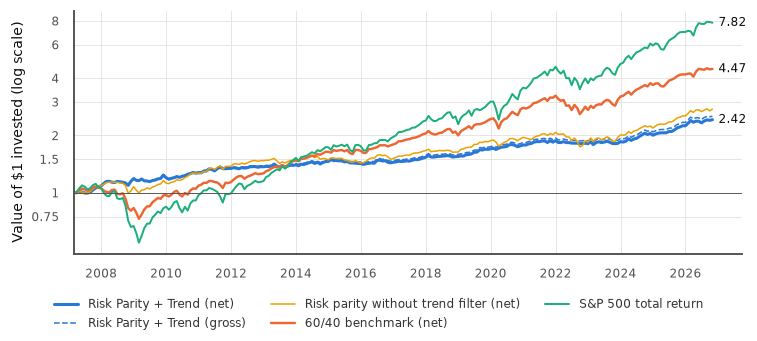

In [23]:
navs = {k: nav_from_returns(v) for k, v in series.items() if k != "1/N (no trend)"}
fig, ax = plt.subplots(figsize=(FIG_W, 3.0), layout="constrained")
style = {"Strategy": dict(color=COLORS["Strategy"], lw=2.0),
         "Strategy (gross)": dict(color=COLORS["Strategy"], lw=1.0, ls="--"),
         "ERC (no trend)": dict(color=COLORS["ERC (no trend)"], lw=1.0),
         "60/40": dict(color=COLORS["60/40"], lw=1.6),
         "S&P 500 TR": dict(color=COLORS["S&P 500 TR"], lw=1.3)}
labels = {"Strategy": "Risk Parity + Trend (net)", "Strategy (gross)": "Risk Parity + Trend (gross)",
          "ERC (no trend)": "Risk parity without trend filter (net)", "60/40": "60/40 benchmark (net)",
          "S&P 500 TR": "S&P 500 total return"}
for k, nav in navs.items():
    ax.plot(nav.index, nav, label=labels[k], **style[k])
for k in ["Strategy", "60/40", "S&P 500 TR"]:
    ax.annotate(f"{navs[k].iloc[-1]:.2f}", xy=(navs[k].index[-1], navs[k].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axhline(1, color=INK_2, lw=0.6)
ax.set_yscale("log")
ax.set_yticks([0.75, 1, 1.5, 2, 3, 4, 6, 8])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("Value of $1 invested (log scale)")
ax.set_xlim(navs["Strategy"].index[0], navs["Strategy"].index[-1] + pd.Timedelta(days=330))
legend_below(fig, ax, ncol=3)
save_figure(fig, "fig_cumulative")
plt.show()
register_item("fig_cumulative", r"Figure~\ref{fig:cumulative}", "Cumulative performance (Figure)", "6.2",
              RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER])

<a id="sec-6-3"></a>
### 6.3 Drawdowns — the risk clients feel

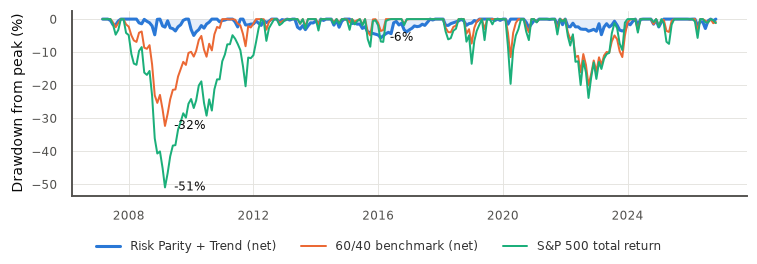

In [24]:
dds = {k: drawdown_series(series[k]) for k in ["Strategy", "60/40", "S&P 500 TR"]}
fig, ax = plt.subplots(figsize=(FIG_W, 2.3), layout="constrained")
for k, dd in dds.items():
    ax.plot(dd.index, 100 * dd, label=labels[k], color=COLORS[k], lw=2.0 if k == "Strategy" else 1.3)
ax.fill_between(dds["Strategy"].index, 100 * dds["Strategy"], 0, color=COLORS["Strategy"], alpha=0.12, lw=0)
for k in ["Strategy", "60/40", "S&P 500 TR"]:
    t_min = dds[k].idxmin()
    ax.annotate(f"{100 * dds[k].min():.0f}%", xy=(t_min, 100 * dds[k].min()), xytext=(6, -2),
                textcoords="offset points", fontsize=8, color=INK)
ax.set_ylabel("Drawdown from peak (%)")
legend_below(fig, ax, ncol=3)
save_figure(fig, "fig_drawdowns")
plt.show()
register_item("fig_drawdowns", r"Figure~\ref{fig:drawdowns}", "Drawdowns (Figure)", "6.3",
              RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER])
for k, key in [("Strategy", "strat"), ("60/40", "b6040"), ("S&P 500 TR", "mkt")]:
    register(f"{key}_maxdd_date", dds[k].idxmin(), "date", f"{k}: month of the maximum drawdown", "6.3",
             RISKY_ASSETS if k == "Strategy" else ["SPY", "AGG", MARKET])

<a id="sec-6-4"></a>
### 6.4 Allocation over time

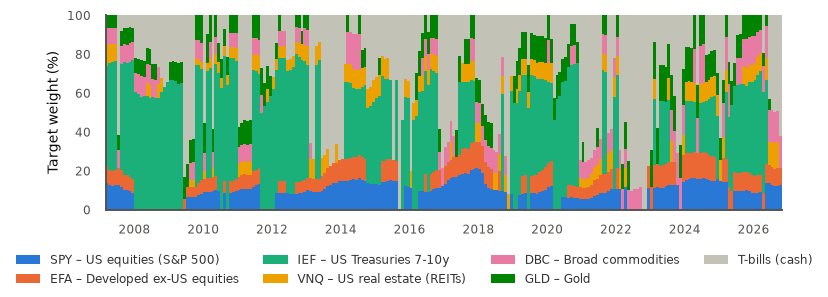

Average target weights:
SPY      9.1
EFA      6.4
IEF     33.1
VNQ      5.6
DBC      6.2
GLD      7.8
CASH    31.7
Share of months with a T-bill position: 81%


'33.1%'

In [25]:
W = base["weights"]
fig, ax = plt.subplots(figsize=(FIG_W, 2.6), layout="constrained")
cols = RISKY_ASSETS + ["CASH"]
bottom = np.zeros(len(W))
for c in cols:   # weights are held for one month -> step plot
    top = bottom + 100 * W[c].to_numpy()
    ax.fill_between(W.index, bottom, top, step="post", color=ASSET_COLORS[c], lw=0,
                    label=f"{c} – {ASSET_NAMES[c]}" if c != "CASH" else "T-bills (cash)")
    bottom = top
ax.set_ylim(0, 100)
ax.set_xlim(W.index[0], W.index[-1])
ax.set_ylabel("Target weight (%)")
ax.grid(False)
legend_below(fig, ax, ncol=4)
save_figure(fig, "fig_weights")
plt.show()
register_item("fig_weights", r"Figure~\ref{fig:weights}", "Target weights over time (Figure)", "6.4", RISKY_ASSETS)

avg_w = W.mean()
share_any_cash = (W["CASH"] > 1e-9).mean()
print("Average target weights:\n" + (100 * avg_w).round(1).to_string())
print(f"Share of months with a T-bill position: {share_any_cash:.0%}")
for c in cols:
    register(f"avg_w_{c.lower()}", avg_w[c], "pct1", f"Average target weight of {c}", "6.4", RISKY_ASSETS)
register("share_cash_months", share_any_cash, "pct1", "Share of months with a T-bill position", "6.4", RISKY_ASSETS)
register("max_cash", W["CASH"].max(), "pct1", "Highest T-bill weight in any month", "6.4", RISKY_ASSETS)
register("max_cash_date", W["CASH"].idxmax(), "date", "Month of the highest T-bill weight", "6.4", RISKY_ASSETS)
register("bond_share_avg", avg_w["IEF"], "pct1", "Average weight of Treasuries (IEF)", "6.4", RISKY_ASSETS)

<a id="sec-6-5"></a>
### 6.5 Calendar-year returns and rolling market exposure

In [26]:
def calendar_returns(r):
    return (1 + r).groupby(r.index.year).prod() - 1

cal = pd.DataFrame({k: calendar_returns(series[k]) for k in ["Strategy", "60/40", "S&P 500 TR"]})
cal.index.name = "year"
# note: 2007 (Mar-Dec) and 2026 (Jan-Oct) are partial years
display_cal = cal.style.format("{:.1%}")
for yr in [2008, 2020, 2022]:
    for k, key in [("Strategy", "strat"), ("60/40", "b6040"), ("S&P 500 TR", "mkt")]:
        register(f"{key}_ret_{yr}", cal.loc[yr, k], "pct1", f"{k}: return in calendar year {yr}", "6.5",
                 RISKY_ASSETS + [RF_TICKER] if k == "Strategy" else ["SPY", "AGG", MARKET])
register("years_beating_6040", int((cal["Strategy"] > cal["60/40"]).sum()), "int",
         "Calendar years in which the strategy beat 60/40", "6.5", RISKY_ASSETS + ["AGG"])
register("n_years_cal", len(cal), "int", "Calendar years (incl. partial 2007 and 2026)", "6.5", RISKY_ASSETS)
display_cal

,Strategy,60/40,S&P 500 TR
year,,,
2007,8.6%,5.4%,6.0%
2008,9.3%,-21.1%,-37.0%
2009,1.1%,16.9%,26.5%
2010,6.0%,12.0%,15.1%
2011,5.5%,4.5%,2.1%
2012,2.0%,11.1%,16.0%
2013,2.4%,17.5%,32.4%
2014,4.2%,10.5%,13.7%
2015,-2.6%,1.1%,1.4%


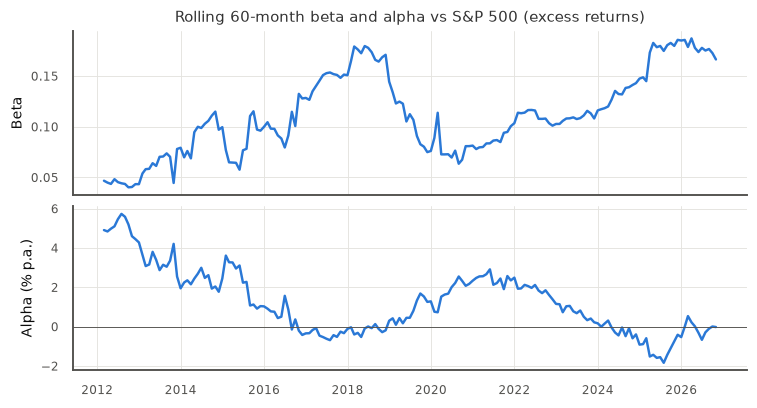

'0.19'

In [27]:
# Rolling 60-month beta and alpha vs the S&P 500 (quantstats, on excess returns as in Lecture 3)
greeks = qs.stats.rolling_greeks(r_strat - rf, benchmark=r_mkt - rf, periods=60, prepare_returns=False)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(FIG_W, 3.6), sharex=True, layout="constrained")
ax1.plot(greeks.index, greeks["beta"], color=COLORS["Strategy"])
ax1.set_ylabel("Beta")
ax1.set_title("Rolling 60-month beta and alpha vs S&P 500 (excess returns)")
ax2.plot(greeks.index, 1200 * greeks["alpha"], color=COLORS["Strategy"])
ax2.axhline(0, color=INK_2, lw=0.6)
ax2.set_ylabel("Alpha (% p.a.)")
plt.show()
register("roll_beta_min", greeks["beta"].min(), "num2", "Lowest rolling 60-month beta", "6.5", RISKY_ASSETS + [MARKET])
register("roll_beta_max", greeks["beta"].max(), "num2", "Highest rolling 60-month beta", "6.5", RISKY_ASSETS + [MARKET])

<a id="sec-6-6"></a>
### 6.6 quantstats report (display only)

The full quantstats metrics report for the strategy against the 60/40 benchmark (net returns, as in
Lecture 3). quantstats uses its own conventions here: risk-free rate 0, calendar-based compounding.
Its Sharpe ratio is therefore **not** the one in our table, which subtracts the T-bill rate.
Section 7 reconciles the two.

In [28]:
qs.reports.metrics(r_strat, benchmark=r_6040, periods_per_year=PERIODS, prepare_returns=False, mode="basic")


Parameter       Value
--------------  ---------
Benchmark       Benchmark
Risk-Free Rate  0.0%
Periods/Year    12
Compounded      Yes
Match Dates     Yes


                     Benchmark    Strategy
-------------------  -----------  ----------
Start Period         2007-03-31   2007-03-31
End Period           2026-10-31   2026-10-31
Risk-Free Rate       0.0%         0.0%
Time in Market       100.0%       100.0%

Cumulative Return    346.74%      141.86%
CAGR﹪               7.91%        4.59%

Sharpe               0.82         0.98
Prob. Sharpe Ratio   99.96%       100.0%
Sortino              1.27         1.75
Sortino/√2           0.9          1.23
Omega                1.84         2.06

Max Drawdown         -32.34%      -5.65%
Max DD Date          2009-02-28   2016-01-31
Max DD Period Start  2007-11-30   2015-02-28
Max DD Period End    2010-11-30   2017-07-31
Longest DD Days      1097         885

Gain/Pain Ratio      0.84         1.06
Gain/Pain (1M)       0.84         1.06

Payoff Rat

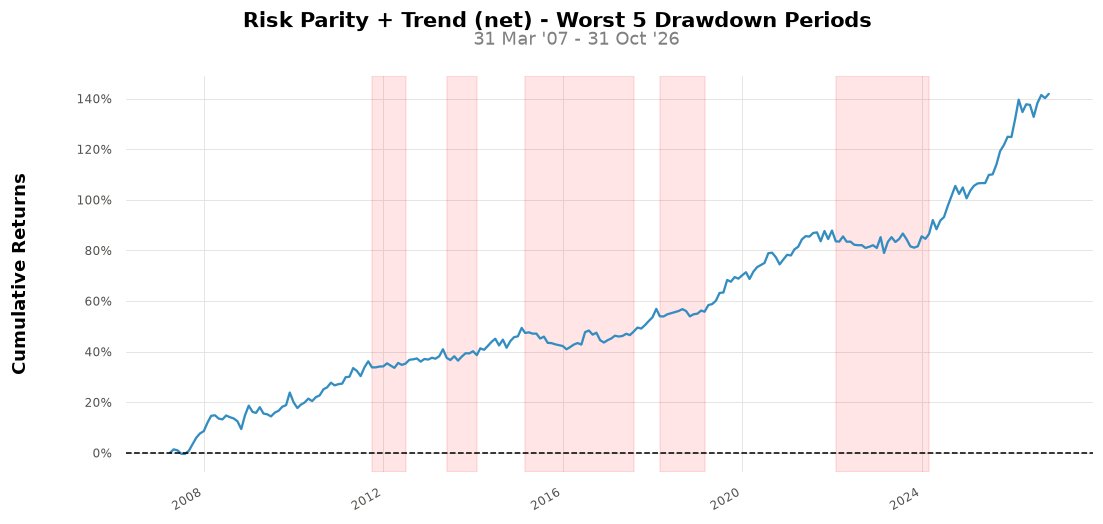

In [29]:
qs.plots.drawdowns_periods(r_strat, fontname="DejaVu Sans", title="Risk Parity + Trend (net)")

<a id="sec-7"></a>
## 7 Verification

A backtest is only as good as its checks (Lecture 4: *specify, generate, verify*). Every assertion
below must pass for the notebook to finish.

In [30]:
checkpoint("7 Verification")
checks = []

def check(name, condition):
    checks.append((name, bool(condition)))
    assert condition, name

# 1. weights are valid portfolios
check("weights sum to 1 every month", np.allclose(W.sum(axis=1), 1.0, atol=1e-12))
check("no short positions", (W >= -1e-12).all().all())
check("fsolve converged in every month (0 fallbacks)", base["fsolve_fallbacks"] == 0)

# 2. equal risk contributions before the trend filter, every month
px_all = data.prices_d[RISKY_ASSETS].dropna()
rd_all = px_all.pct_change(fill_method=None).iloc[1:]
rc_dev = []
for t in DECISION_DATES:
    c = np.cov(rd_all.loc[:t].iloc[-COV_WINDOW:].to_numpy(), rowvar=False)
    w_t, _ = erc_weights(c)
    rc_dev.append(np.max(np.abs(risk_contributions(w_t, c) - 1 / len(RISKY_ASSETS))))
check("risk contributions equal within 1e-8 in every month", max(rc_dev) < 1e-8)
print(f"largest deviation of a risk contribution from 1/N: {max(rc_dev):.1e}")

# 3. no look-ahead: weights up to Dec 2015 are identical when the data end in Dec 2015
data_trunc = build_market_data(prices_raw.loc[:"2015-12-31"], RISKY_ASSETS, OTHER_TICKERS, RF_TICKER)
dates_trunc = DECISION_DATES[DECISION_DATES <= "2015-12-31"]
W_trunc = target_weights(data_trunc, RISKY_ASSETS, dates_trunc, COV_WINDOW, SMA_WINDOW, True, WEIGHTING)
check("truncation test: weights unchanged when future data are removed",
      np.allclose(W_trunc.to_numpy(), W.loc[dates_trunc].to_numpy(), atol=1e-12))

# 4. engine identities
res = base["result"]
check("net = (1 - cost) x (1 + gross) - 1", np.allclose(1 + res["net"], (1 - res["cost"]) * (1 + res["gross"])))
zero = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, True, WEIGHTING, 0.0, T0,
                    benchmark_weights=BENCHMARK_6040)
closed_6040 = 0.6 * data.rets_m["SPY"] + 0.4 * data.rets_m["AGG"]
check("60/40 from the engine (zero cost) = 0.6 R_SPY + 0.4 R_AGG",
      np.allclose(zero["benchmark"], closed_6040.loc[RETURN_MONTHS], atol=1e-14))
check("NAV starts at 1 on the first decision date", navs["Strategy"].iloc[0] == 1.0
      and navs["Strategy"].index[0] == T0)

# 5. OLS beta = moment beta (cov/var) and alpha = E[R-Rf] - beta E[Rm-Rf]  (Lecture 3 formulas)
ex, mex = r_strat - rf, r_mkt - rf
beta_mom = np.cov(ex, mex, ddof=1)[0, 1] / np.var(mex, ddof=1)
alpha_mom = 12 * (ex.mean() - beta_mom * mex.mean())
check("regression beta = cov/var", np.isclose(beta_mom, P["beta_mkt"]))
check("regression alpha = E[R-Rf] - beta E[Rm-Rf]", np.isclose(alpha_mom, P["alpha_mkt"]))

# 6. quantstats cross-checks (feed excess returns; quantstats' IR is monthly -> x sqrt(12))
qs_vol = qs.stats.volatility(r_strat, periods=12, prepare_returns=False)
qs_sr = qs.stats.sharpe(ex, periods=12)
qs_greeks = qs.stats.greeks(ex, mex, periods=12, prepare_returns=False)
qs_ir = qs.stats.information_ratio(r_strat, r_6040, prepare_returns=False) * np.sqrt(12)
qs_cagr = qs.stats.cagr(r_strat, periods=12)
qs_mdd = qs.stats.max_drawdown(r_strat)
check("quantstats volatility", np.isclose(qs_vol, P["ann_vol"]))
check("quantstats Sharpe on excess returns", np.isclose(qs_sr, P["sharpe"]))
check("quantstats beta", np.isclose(qs_greeks["beta"], P["beta_mkt"]))
check("quantstats alpha on excess returns", np.isclose(qs_greeks["alpha"], P["alpha_mkt"]))
check("quantstats information ratio x sqrt(12)", np.isclose(qs_ir, P["info_ratio"]))
print(f"CAGR: ours {P['cagr']:.4%} vs quantstats {qs_cagr:.4%}")
print(f"Max drawdown: ours {P['max_dd']:.4%} vs quantstats {qs_mdd:.4%}")
check("quantstats CAGR (12 periods per year)", np.isclose(qs_cagr, P["cagr"], atol=1e-4))
check("quantstats max drawdown", np.isclose(qs_mdd, P["max_dd"], atol=1e-4))

# 7. data sanity: SPY tracks the S&P 500 total return index
rho = data.rets_m["SPY"].corr(data.rets_m[MARKET])
gap = 12 * (data.rets_m[MARKET] - data.rets_m["SPY"]).loc[RETURN_MONTHS].mean()
check("SPY vs ^SP500TR correlation > 0.999", rho > 0.999)
print(f"SPY vs S&P 500 TR: correlation {rho:.5f}, average return gap {gap:.2%} p.a. (fund costs)")
register("spy_index_gap", gap, "pct2", "Average return gap S&P 500 TR minus SPY p.a.", "7", ["SPY", MARKET])

pd.DataFrame(checks, columns=["check", "passed"])

largest deviation of a risk contribution from 1/N: 4.6e-14


CAGR: ours 4.5931% vs quantstats 4.5931%
Max drawdown: ours -5.6548% vs quantstats -5.6548%
SPY vs S&P 500 TR: correlation 0.99959, average return gap 0.09% p.a. (fund costs)


,check,passed
0,weights sum to 1 every month,True
1,no short positions,True
2,fsolve converged in every month (0 fallbacks),True
3,risk contributions equal within 1e-8 in every ...,True
4,truncation test: weights unchanged when future...,True
5,net = (1 - cost) x (1 + gross) - 1,True
6,60/40 from the engine (zero cost) = 0.6 R_SPY ...,True
7,NAV starts at 1 on the first decision date,True
8,regression beta = cov/var,True
9,regression alpha = E[R-Rf] - beta E[Rm-Rf],True


<a id="sec-8"></a>
## 8 Robustness

<a id="sec-8-1"></a>
### 8.1 Transaction costs and the break-even cost (fsolve)

Costs are charged on turnover. We vary them from 0 to 50 bps per unit traded. The **break-even
cost** is the cost level at which the strategy's Sharpe ratio falls to that of the 60/40
benchmark, with the same cost applied to both. It solves
$SR_{\text{strategy}}(c)-SR_{60/40}(c)=0$ with **`fsolve`**. If the strategy is not ahead even at
zero cost, no break-even exists.

In [31]:
checkpoint("8 Robustness")
W_bench = constant_weights(BENCHMARK_6040, DECISION_DATES)


def sharpe_at(weights, c):
    r = backtest(weights, data, c)["net"]
    return performance_summary(r, data.rf_m)["sharpe"]


cost_grid = [0, 5, 10, 20, 30, 50]
cost_rows = []
for c in cost_grid:
    rs = backtest(W, data, c)["net"]
    rb = backtest(W_bench, data, c)["net"]
    ps, pb = performance_summary(rs, data.rf_m), performance_summary(rb, data.rf_m)
    cost_rows.append({"cost (bps)": c, "strategy CAGR": ps["cagr"], "strategy Sharpe": ps["sharpe"],
                      "60/40 CAGR": pb["cagr"], "60/40 Sharpe": pb["sharpe"]})
cost_df = pd.DataFrame(cost_rows).set_index("cost (bps)")

c_star, has_star = breakeven_cost(lambda c: sharpe_at(W, c) - sharpe_at(W_bench, c), x0=COST_BPS)
print(f"Break-even cost (Sharpe): {c_star:.1f} bps" if has_star else
      "No break-even: the strategy's Sharpe ratio is below the 60/40 Sharpe ratio even at zero cost")
annual_drag = P["turnover"] * COST_BPS / 1e4
print(f"Cost drag at {COST_BPS:.0f} bps: {annual_drag:.2%} p.a. (turnover {P['turnover']:.0%} p.a.)")
register("cost_drag", annual_drag, "pct2", f"Annual cost drag at {COST_BPS:.0f} bps", "8.1", RISKY_ASSETS)
register("cost_bps", COST_BPS, "bps0", "Assumed trading cost per unit of turnover", "0.2", [])
register("breakeven_bps", c_star if has_star else "none", "bps0" if has_star else "text",
         "Break-even cost at which Sharpe equals 60/40", "8.1", RISKY_ASSETS + ["AGG", RF_TICKER])
register("sharpe_cost50", cost_df.loc[50, "strategy Sharpe"], "num2", "Strategy Sharpe ratio at 50 bps", "8.1",
         RISKY_ASSETS + [RF_TICKER])
register("cagr_cost50", cost_df.loc[50, "strategy CAGR"], "pct1", "Strategy CAGR at 50 bps", "8.1", RISKY_ASSETS)
cost_df.style.format({"strategy CAGR": "{:.2%}", "60/40 CAGR": "{:.2%}", "strategy Sharpe": "{:.2f}",
                      "60/40 Sharpe": "{:.2f}"})

Break-even cost (Sharpe): 7.6 bps
Cost drag at 10 bps: 0.22% p.a. (turnover 216% p.a.)


,strategy CAGR,strategy Sharpe,60/40 CAGR,60/40 Sharpe
cost (bps),,,,
0,4.82%,0.71,7.93%,0.67
5,4.71%,0.68,7.92%,0.67
10,4.59%,0.66,7.91%,0.67
20,4.37%,0.61,7.88%,0.67
30,4.14%,0.56,7.86%,0.66
50,3.69%,0.47,7.80%,0.66


<a id="sec-8-2"></a>
### 8.2 Stress periods

In [32]:
PERIODS_STRESS = {
    "Financial crisis": ("2007-11-30", "2009-02-28"),
    "Covid crash": ("2020-02-29", "2020-03-31"),
    "Inflation and rate shock": ("2022-01-31", "2022-10-31"),
    "Recovery": ("2023-01-31", "2026-10-31"),
}
stress_rows = {}
for label, (a, b) in PERIODS_STRESS.items():
    row = {}
    for k in ["Strategy", "60/40", "S&P 500 TR"]:
        r = series[k].loc[a:b]
        row[k] = np.prod(1 + r) - 1
    stress_rows[f"{label} ({pd.Timestamp(a):%b %Y}–{pd.Timestamp(b):%b %Y})"] = row
stress = pd.DataFrame(stress_rows).T
key_map = {"Financial crisis": "gfc", "Covid crash": "covid", "Inflation and rate shock": "infl",
           "Recovery": "recov"}
for (label, _), short in zip(PERIODS_STRESS.items(), key_map.values()):
    full = next(i for i in stress.index if i.startswith(label))
    for k, key in [("Strategy", "strat"), ("60/40", "b6040"), ("S&P 500 TR", "mkt")]:
        register(f"{key}_{short}", stress.loc[full, k], "pct1", f"{k}: return, {full}", "8.2",
                 RISKY_ASSETS + [RF_TICKER] if k == "Strategy" else ["SPY", "AGG", MARKET])
stress.style.format("{:.1%}")

,Strategy,60/40,S&P 500 TR
Financial crisis (Nov 2007–Feb 2009),9.2%,-32.3%,-50.9%
Covid crash (Feb 2020–Mar 2020),0.1%,-11.5%,-19.6%
Inflation and rate shock (Jan 2022–Oct 2022),-3.4%,-16.6%,-17.7%
Recovery (Jan 2023–Oct 2026),33.6%,64.0%,108.0%


<a id="sec-8-3"></a>
### 8.3 Parameter sensitivity

The base case uses a 10-month moving average and a 252-day risk window. Both are fixed in advance
(Faber, 2007; a standard one-year estimate). A robust rule should show a *plateau* of similar
Sharpe ratios around the base case, not a single spike. All runs use the same months.

Parameter grid (21 backtests):   0%|                                                                                                      | 0/21 [00:00<?, ?it/s]

Parameter grid (21 backtests):   5%|████▍                                                                                         | 1/21 [00:00<00:04,  4.49it/s]

Parameter grid (21 backtests):  10%|████████▉                                                                                     | 2/21 [00:00<00:04,  4.56it/s]

Parameter grid (21 backtests):  14%|█████████████▍                                                                                | 3/21 [00:00<00:03,  4.56it/s]

Parameter grid (21 backtests):  19%|█████████████████▉                                                                            | 4/21 [00:00<00:03,  4.53it/s]

Parameter grid (21 backtests):  24%|██████████████████████▍                                                                       | 5/21 [00:01<00:03,  4.47it/s]

... (13 outputs left out)

Parameter grid (21 backtests):  90%|████████████████████████████████████████████████████████████████████████████████████▏        | 19/21 [00:04<00:00,  4.28it/s]

Parameter grid (21 backtests):  95%|████████████████████████████████████████████████████████████████████████████████████████▌    | 20/21 [00:04<00:00,  3.97it/s]

Parameter grid (21 backtests): 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [00:04<00:00,  3.99it/s]

Parameter grid (21 backtests): 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [00:04<00:00,  4.22it/s]

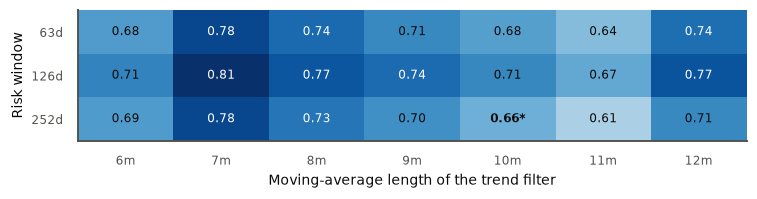

SMA (months),6,7,8,9,10,11,12
risk window (days),,,,,,,
63,0.68,0.78,0.74,0.71,0.68,0.64,0.74
126,0.71,0.81,0.77,0.74,0.71,0.67,0.77
252,0.69,0.78,0.73,0.70,0.66,0.61,0.71


In [33]:
SMA_GRID = [6, 7, 8, 9, 10, 11, 12]
COV_GRID = [63, 126, 252]
heat = pd.DataFrame(index=COV_GRID, columns=SMA_GRID, dtype=float)
for cw, sm_ in tqdm([(c, m) for c in COV_GRID for m in SMA_GRID], desc="Parameter grid (21 backtests)"):
    run = run_strategy(data, RISKY_ASSETS, cw, sm_, True, WEIGHTING, COST_BPS, T0)
    heat.loc[cw, sm_] = performance_summary(run["returns"], data.rf_m)["sharpe"]
heat.index.name, heat.columns.name = "risk window (days)", "SMA (months)"

fig, ax = plt.subplots(figsize=(FIG_W, 1.7), layout="constrained")
im = ax.imshow(heat.to_numpy(), cmap="Blues", aspect="auto", vmin=heat.min().min() - 0.1, vmax=heat.max().max())
ax.set_xticks(range(len(SMA_GRID)), [f"{s}m" for s in SMA_GRID])
ax.set_yticks(range(len(COV_GRID)), [f"{c}d" for c in COV_GRID])
ax.set_xlabel("Moving-average length of the trend filter")
ax.set_ylabel("Risk window")
ax.grid(False)
for i in range(len(COV_GRID)):
    for j in range(len(SMA_GRID)):
        v = heat.iloc[i, j]
        is_base = COV_GRID[i] == COV_WINDOW and SMA_GRID[j] == SMA_WINDOW
        ax.text(j, i, f"{v:.2f}" + ("*" if is_base else ""), ha="center", va="center", fontsize=8,
                color="white" if v > heat.to_numpy().mean() else INK, fontweight="bold" if is_base else "normal")
save_figure(fig, "fig_sensitivity")
plt.show()
register_item("fig_sensitivity", r"Figure~\ref{fig:sensitivity}", "Parameter sensitivity of the Sharpe ratio (Figure)",
              "8.3", RISKY_ASSETS + [RF_TICKER])
register("heat_min", heat.min().min(), "num2", "Lowest Sharpe ratio in the parameter grid", "8.3", RISKY_ASSETS)
register("heat_max", heat.max().max(), "num2", "Highest Sharpe ratio in the parameter grid", "8.3", RISKY_ASSETS)
register("heat_n", heat.size, "int", "Number of parameter combinations tested", "8.3", RISKY_ASSETS)
heat.style.format("{:.2f}")

<a id="sec-8-4"></a>
### 8.4 Leave-one-out: does the result depend on one asset class?

We chose the universe of asset classes before looking at results. Even so, an asset with an
exceptional run (for example gold in 2024–2026) could drive the result. We therefore rerun the
strategy six times, each time without one asset class, over the same months and with the same costs.

In [34]:
loo_rows = {"All six (base case)": performance_summary(r_strat, data.rf_m)}
for a in RISKY_ASSETS:
    keep = [x for x in RISKY_ASSETS if x != a]
    run = run_strategy(data, keep, COV_WINDOW, SMA_WINDOW, True, WEIGHTING, COST_BPS, T0)
    loo_rows[f"without {a}"] = performance_summary(run["returns"], data.rf_m)
loo = pd.DataFrame(loo_rows).T[["cagr", "ann_vol", "sharpe", "max_dd"]]
worst = loo["sharpe"].drop("All six (base case)").idxmin()
register("loo_sharpe_min", loo["sharpe"].drop("All six (base case)").min(), "num2",
         "Lowest Sharpe ratio when one asset class is left out", "8.4", RISKY_ASSETS + [RF_TICKER])
register("loo_sharpe_max", loo["sharpe"].drop("All six (base case)").max(), "num2",
         "Highest Sharpe ratio when one asset class is left out", "8.4", RISKY_ASSETS + [RF_TICKER])
register("loo_worst_asset", worst.replace("without ", ""), "text",
         "Asset class whose removal lowers the Sharpe ratio most", "8.4", RISKY_ASSETS)
register("loo_sharpe_nogold", loo.loc["without GLD", "sharpe"], "num2", "Sharpe ratio without gold", "8.4",
         RISKY_ASSETS + [RF_TICKER])
register("loo_maxdd_worst", loo["max_dd"].drop("All six (base case)").min(), "pct1",
         "Deepest drawdown when one asset class is left out", "8.4", RISKY_ASSETS)

rows_tex = [(tex_escape(i), [tex_num(loo.loc[i, "cagr"], "pct"), tex_num(loo.loc[i, "ann_vol"], "pct"),
                             tex_num(loo.loc[i, "sharpe"], "num"), tex_num(loo.loc[i, "max_dd"], "pct")])
            for i in loo.index]
save_table(fin_table([("", rows_tex)], [r"CAGR (\%)", r"Vol.\ (\%)", "Sharpe", r"Max DD (\%)"],
                     first_col="Universe"), "tab_leave_one_out")
register_item("tab_leave_one_out", r"Table~\ref{tab:loo}", "Leave-one-out robustness (Table)", "8.4",
              RISKY_ASSETS + [RF_TICKER])
loo.style.format({"cagr": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}"})

,cagr,ann_vol,sharpe,max_dd
All six (base case),4.6%,4.7%,0.66,-5.7%
without SPY,4.0%,4.9%,0.53,-6.3%
without EFA,4.6%,4.8%,0.66,-6.1%
without IEF,6.3%,7.8%,0.63,-14.1%
without VNQ,4.9%,4.5%,0.75,-5.2%
without DBC,4.7%,5.2%,0.63,-7.7%
without GLD,4.0%,4.4%,0.56,-5.7%


<a id="sec-9"></a>
## 9 Machine-learning extension: a hidden-Markov regime filter

**Question.** Can a machine-learning model detect stressed markets earlier or more reliably than the
10-month trend filter of the base strategy? Any such filter must be judged by the same yardstick as the
strategy itself: net returns, drawdowns and the same months.

**Model.** A *hidden Markov model* (HMM; Hamilton, 1989; Rabiner, 1989) assumes that the market switches
between unobservable states, here *calm* and *turbulent*. Only the daily observations
$y_t$ = (return, 21-day realised volatility) of the S&P 500 are visible. The model has three parts:
* the transition matrix $A$, with $a_{ij}=P(X_{t+1}=j\mid X_t=i)$, which describes how persistent the regimes are,
* Gaussian emissions $b_j(y)=\mathcal N(y;\mu_j,\Sigma_j)$, which describe what returns and volatility look like in each state,
* the initial distribution $\pi$.

The parameters are estimated with the Baum-Welch (EM) algorithm (`hmmlearn.GaussianHMM`). The investor
needs $P(X_t=\text{turbulent}\mid y_1,\dots,y_t)$, i.e. the probability given **only the past**. This is
the *forward filter*:
$$\alpha_t \propto (\alpha_{t-1}A)\odot b(y_t).$$
Viterbi paths or smoothed probabilities over the whole sample would use future data and are therefore
not used for decisions. Regime models of this kind are well established in asset allocation
(Ang & Bekaert, 2002; Nystrup et al., 2018).

**Iteration compact (fixed before the first run).**

| | |
|---|---|
| Decision | at each month-end: hold the growth assets (SPY, EFA, VNQ, DBC) at full weight, or at 50% with the rest in T-bills |
| Worst mistake | a *missed crash* (signal says calm, market falls). It costs the client capital exactly when it hurts most |
| Acceptable mistake | a *false alarm*. It costs some return and trading costs |
| Baseline without ML | volatility rule: risk-off if today's 21-day volatility is above the 80th percentile of all volatility observed so far |
| Success metric | net Sharpe ratio and maximum drawdown on the same months, with the same 10 bps costs |
| Fallback | if the HMM fails the gates below, it stays a documented variant and the prospectus strategy is unchanged |

**Data contract (no look-ahead).**
* Decision at the close of month-end $t$ with data up to $t$; the new weights earn month $t+1$.
* Features use past prices only (return and the trailing 21-day volatility). Training data start in 1990, so
  the model has seen earlier crises before the backtest starts in 2007.
* *Walk-forward, expanding window:* the HMM (and its scaler) is re-estimated every 31 December on data up
  to that day. In between, the fixed model is applied with the forward filter every month.
* The turbulent state is chosen by a fixed rule (the state with the higher mean volatility), never by
  backtest results. Five EM restarts are run per fit; the best one by **training** log-likelihood is kept.

**Four variants, same months and costs.**

| Variant | Risk-off signal |
|---|---|
| A: Base strategy | 10-month trend filter (Section 4) |
| B: Volatility rule | simple non-ML baseline on risk parity weights |
| C: HMM | HMM instead of the trend filter, on risk parity weights |
| D: Trend + HMM | HMM overlay on top of the base strategy |

**Promotion gates (pre-registered).** C or D only counts as an improvement over A if **all** hold:
(1) net Sharpe ratio $\ge$ A, (2) maximum drawdown not deeper than A, (3) better cumulative return than A in
at least 2 of the 3 stress periods of Section 8.2. The threshold (50%), the cut (50%) and the volatility
quantile (80%) are **not** tuned on these results.


In [35]:
# ---------------------------------------------------------------- machine-learning extension: regime filter
logging.getLogger("hmmlearn").setLevel(logging.ERROR)   # silence "not converging" messages of single EM runs


@dataclass(frozen=True)
class HMMConfig:
    """All assumptions of the regime filter, fixed BEFORE looking at results (no tuning on the backtest)."""
    start: str = "1990-01-01"        # first day of the S&P 500 data used to train the HMM
    n_states: int = 2                # calm vs turbulent
    seeds: tuple = (0, 1, 2, 3, 4)   # EM restarts; the best one by TRAINING log-likelihood is kept
    n_iter: int = 100                # EM iterations per restart
    vol_window: int = 21             # trading days for realised volatility (feature)
    prob_threshold: float = 0.5      # risk-off if P(turbulent) > threshold
    risk_off_scale: float = 0.5      # growth assets are scaled to 50% in risk-off months
    vol_quantile: float = 0.8        # simple (non-ML) baseline: volatility above its 80th percentile so far
    stress_threshold: float = -0.05  # ex-post label: S&P 500 falls by more than 5% in the next month


HMM_CFG = HMMConfig()
GROWTH_ASSETS = ["SPY", "EFA", "VNQ", "DBC"]   # assets cut in risk-off months; IEF, GLD and T-bills are kept


def regime_features(prices, vol_window=21):
    """Daily features of the HMM: simple return and annualised realised volatility (past window only)."""
    r = prices.pct_change(fill_method=None)
    vol = r.rolling(vol_window).std() * np.sqrt(252)
    return pd.DataFrame({"ret": r, "vol": vol}).dropna()


def fit_hmm(X, cfg=HMM_CFG):
    """Gaussian HMM fitted with Baum-Welch (EM). Returns (model, scaler, index of the turbulent state).

    The scaler is fitted on the training data only. Several random starts guard against poor local optima;
    the run with the highest log-likelihood ON THE TRAINING DATA is kept. The turbulent state is defined by a
    fixed rule: the state with the higher mean volatility (no selection based on backtest results).
    """
    scaler = StandardScaler().fit(X)
    Z = scaler.transform(X)
    best = None
    for seed in cfg.seeds:
        model = GaussianHMM(n_components=cfg.n_states, covariance_type="full", n_iter=cfg.n_iter,
                            tol=1e-3, random_state=seed)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model.fit(Z)
            ll = model.score(Z)
        if best is None or ll > best[0] + 1e-9:
            best = (ll, model)
    model = best[1]
    vol_means = scaler.inverse_transform(model.means_)[:, 1]
    return model, scaler, int(np.argmax(vol_means))


def filtered_state_probs(model, scaler, X):
    """Forward algorithm: P(state_t | observations up to t) for every t. Uses no future observations
    (unlike Viterbi or forward-backward smoothing over the whole sample)."""
    Z = scaler.transform(X)
    n = model.n_components
    log_b = np.column_stack([multivariate_normal.logpdf(Z, mean=model.means_[k], cov=model.covars_[k])
                             for k in range(n)])
    A = model.transmat_
    out = np.empty((len(Z), n))
    prev = model.startprob_
    for t in range(len(Z)):
        prior = model.startprob_ if t == 0 else prev @ A
        log_p = np.log(np.maximum(prior, 1e-300)) + log_b[t]
        p = np.exp(log_p - log_p.max())
        prev = out[t] = p / p.sum()
    return out


def map_years(step, features, items, cfg, n_jobs=1):
    """Run step(features, fit_year, dates, cfg) for every (fit_year, dates) item, in order.
    n_jobs != 1 uses joblib worker processes; where processes are not allowed (some sandboxes) it falls back
    to a serial loop. Results are identical either way."""
    if n_jobs != 1:
        try:
            return Parallel(n_jobs=n_jobs, return_as="generator")(
                delayed(step)(features, fy, ds, cfg) for fy, ds in items)
        except OSError:
            pass
    return (step(features, fy, ds, cfg) for fy, ds in items)


def _hmm_fit_filter(features, fit_year, dates, cfg):
    """One walk-forward step: fit on data up to 31 Dec of `fit_year`, filtered P(turbulent) at `dates`."""
    train = features.loc[:f"{fit_year}-12-31"]
    model, scaler, turb = fit_hmm(train.to_numpy(), cfg)
    upto = features.loc[:max(dates)]
    p = pd.Series(filtered_state_probs(model, scaler, upto.to_numpy())[:, turb], index=upto.index)
    return {t: float(p.loc[:t].iloc[-1]) for t in dates}


def hmm_regime_probs(features, decision_dates, cfg=HMM_CFG, progress=True, n_jobs=1):
    """Walk-forward P(turbulent) at each decision date.

    The HMM is re-estimated once a year on all data up to 31 December (expanding window). Every decision
    date t uses the latest model fitted on or before t and the filtered probability from data up to t.
    The yearly fits are independent, so `n_jobs` > 1 (or -1 = all cores) runs them in parallel; every fit
    has fixed seeds, so the result is identical for any n_jobs.
    """
    groups = {}
    for t in pd.DatetimeIndex(decision_dates):
        fit_year = t.year if (t.month == 12 and t.day == 31) else t.year - 1
        groups.setdefault(fit_year, []).append(t)
    items = list(groups.items())
    steps = map_years(_hmm_fit_filter, features, items, cfg, n_jobs)
    if progress:
        steps = tqdm(steps, total=len(items), desc="HMM walk-forward (one fit per year)")
    out = {}
    for step in steps:
        out.update(step)
    probs = pd.Series(out, name="p_turbulent").sort_index()
    probs.index.name = "decision_date"
    return probs


def vol_rule_signal(features, decision_dates, quantile=0.8):
    """Simple non-ML baseline: risk-off if today's realised volatility is above the `quantile` of all
    volatility observed so far (expanding window, past data only)."""
    vol = features["vol"]
    out = {}
    for t in pd.DatetimeIndex(decision_dates):
        hist = vol.loc[:t]
        out[t] = bool(hist.iloc[-1] > hist.quantile(quantile))
    sig = pd.Series(out, name="risk_off").sort_index()
    sig.index.name = "decision_date"
    return sig


def apply_risk_off(weights, risk_off, scale=0.5, growth_assets=None):
    """Scale the growth assets to `scale` of their weight in risk-off months and move the rest to T-bills."""
    growth = [a for a in (GROWTH_ASSETS if growth_assets is None else growth_assets) if a in weights.columns]
    W = weights.copy()
    off = risk_off.reindex(W.index).fillna(False).astype(bool).to_numpy()
    cut = W.loc[off, growth] * (1.0 - scale)
    W.loc[off, growth] = W.loc[off, growth] - cut
    W.loc[off, "CASH"] = W.loc[off, "CASH"] + cut.sum(axis=1)
    W.attrs = dict(weights.attrs)
    return W


In [36]:
checkpoint("9 ML extension")
# Extract (ML): daily S&P 500 total return index since 1990, used only to train and run the HMM
hmm_px = clean_prices(download_prices([MARKET], HMM_CFG.start, END))[MARKET].dropna()
features = regime_features(hmm_px, HMM_CFG.vol_window)
print(f"HMM data: {hmm_px.index[0].date()} to {hmm_px.index[-1].date()} ({len(hmm_px):,} trading days)")
assert hmm_px.index[-1] <= pd.Timestamp("2026-10-31"), "no data after the sample end"
assert not features.isna().any().any()
register("hmm_data_start", hmm_px.index[0], "date", "First month of S&P 500 data used to train the HMM", "9",
         [MARKET])
features.describe().T.round(4)

HMM data: 1990-01-02 to 2026-10-30 (9,276 trading days)


,count,mean,std,min,25%,50%,75%,max
ret,9255.0,0.0005,0.0113,-0.1198,-0.0043,0.0007,0.0058,0.1158
vol,9255.0,0.1537,0.0952,0.0346,0.0968,0.1306,0.1827,0.9686


<a id="sec-9-1"></a>
### 9.1 Walk-forward signals and the four variants

The progress bar shows one HMM fit per year (five EM restarts each) and the estimated remaining time.

In [37]:
p_turb = hmm_regime_probs(features, DECISION_DATES, HMM_CFG, n_jobs=N_JOBS)          # P(turbulent), walk-forward
risk_off_hmm = p_turb > HMM_CFG.prob_threshold
risk_off_vol = vol_rule_signal(features, DECISION_DATES, HMM_CFG.vol_quantile)

W_A, W_erc = base["weights"], erc_nt["weights"]          # base strategy and risk parity without trend filter
VARIANTS = {
    "A: Trend (base)": W_A,
    "B: Volatility rule": apply_risk_off(W_erc, risk_off_vol, HMM_CFG.risk_off_scale),
    "C: HMM": apply_risk_off(W_erc, risk_off_hmm, HMM_CFG.risk_off_scale),
    "D: Trend + HMM": apply_risk_off(W_A, risk_off_hmm, HMM_CFG.risk_off_scale),
}
ml_res = {k: backtest(Wv, data, COST_BPS) for k, Wv in VARIANTS.items()}
ml_ret = {k: r["net"] for k, r in ml_res.items()}
assert all(r.index.equals(RETURN_MONTHS) for r in ml_ret.values()), "all variants on the same months"
assert np.allclose(ml_ret["A: Trend (base)"], r_strat), "variant A reproduces the base strategy"
assert all(np.allclose(Wv.sum(axis=1), 1.0) for Wv in VARIANTS.values())
print(f"Months in risk-off: HMM {risk_off_hmm.mean():.0%}, volatility rule {risk_off_vol.mean():.0%}")
register("ml_riskoff_hmm", risk_off_hmm.reindex(DECISION_DATES[:-1]).mean(), "pct1", "Share of months the HMM signals risk-off", "9.1", [MARKET])
register("ml_riskoff_vol", risk_off_vol.reindex(DECISION_DATES[:-1]).mean(), "pct1", "Share of months the volatility rule signals risk-off",
         "9.1", [MARKET])

HMM walk-forward (one fit per year):   0%|                                                                                                | 0/20 [00:00<?, ?it/s]

HMM walk-forward (one fit per year):   5%|████▍                                                                                   | 1/20 [00:02<00:43,  2.31s/it]

HMM walk-forward (one fit per year):  15%|█████████████▏                                                                          | 3/20 [00:02<00:10,  1.56it/s]

HMM walk-forward (one fit per year):  50%|███████████████████████████████████████████▌                                           | 10/20 [00:02<00:01,  6.48it/s]

HMM walk-forward (one fit per year):  65%|████████████████████████████████████████████████████████▌                              | 13/20 [00:02<00:00,  7.93it/s]

HMM walk-forward (one fit per year):  80%|█████████████████████████████████████████████████████████████████████▌                 | 16/20 [00:02<00:00, 10.12it/s]

HMM walk-forward (one fit per year): 100%|███████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:03<00:00, 13.30it/s]

HMM walk-forward (one fit per year): 100%|███████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:03<00:00,  6.55it/s]

Months in risk-off: HMM 37%, volatility rule 21%


'20.8%'

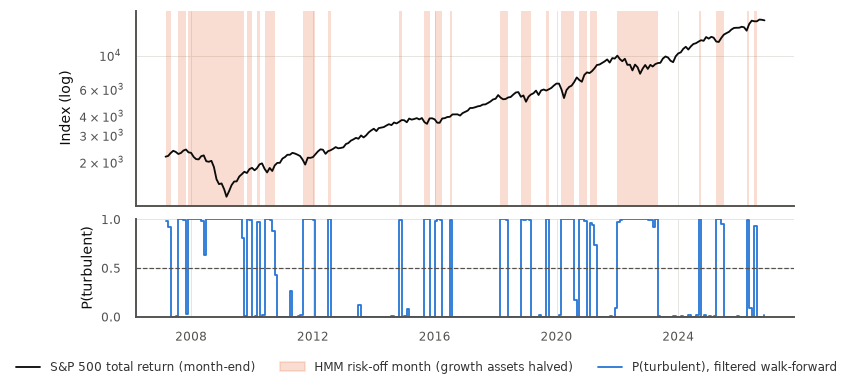

In [38]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(FIG_W, 3.4), sharex=True, height_ratios=[2, 1], layout="constrained")
spx_m = data.prices_m[MARKET].loc[T0:]
ax1.plot(spx_m.index, spx_m, color=INK, lw=1.2, label="S&P 500 total return (month-end)")
off_months = risk_off_hmm[risk_off_hmm].index
for t in off_months:      # a signal at month-end t is acted on in month t+1
    ax1.axvspan(t, t + pd.offsets.MonthEnd(1), color=COLORS["60/40"], alpha=0.22, lw=0)
ax1.fill_between([], [], color=COLORS["60/40"], alpha=0.22, label="HMM risk-off month (growth assets halved)")
ax1.set_yscale("log")
ax1.set_ylabel("Index (log)")
ax2.step(p_turb.index, p_turb, where="post", color=COLORS["Strategy"], lw=1.2,
         label="P(turbulent), filtered walk-forward")
ax2.axhline(HMM_CFG.prob_threshold, color=INK_2, lw=0.8, ls="--")
ax2.set_ylim(0, 1)
ax2.set_ylabel("P(turbulent)")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="outside lower center", ncol=3, frameon=False)
save_figure(fig, "fig_regimes")
plt.show()
register_item("fig_regimes", r"Figure~\ref{fig:regimes}", "HMM regimes, walk-forward (Figure)", "9.1", [MARKET])

<a id="sec-9-2"></a>
### 9.2 Results and promotion gates

In [39]:
ML_KEYS = {"A: Trend (base)": "a", "B: Volatility rule": "b", "C: HMM": "c", "D: Trend + HMM": "d"}
ml_perf = {k: performance_summary(r, rf, benchmark=r_6040, market=r_mkt, turnover=ml_res[k]["turnover"])
           for k, r in ml_ret.items()}
for k, r in ml_res.items():
    ml_perf[k]["avg_cash"] = r["cash_weight"].mean()
STRESS3 = {k: v for k, v in PERIODS_STRESS.items() if k != "Recovery"}
stress_ml = pd.DataFrame({label: {k: np.prod(1 + r.loc[a:b]) - 1 for k, r in ml_ret.items()}
                          for label, (a, b) in STRESS3.items()})

gate_rows = {}
for k in ["B: Volatility rule", "C: HMM", "D: Trend + HMM"]:
    a, v = ml_perf["A: Trend (base)"], ml_perf[k]
    wins = int((stress_ml.loc[k] > stress_ml.loc["A: Trend (base)"]).sum())
    gate_rows[k] = {"Sharpe >= A": v["sharpe"] >= a["sharpe"], "max DD not deeper than A": v["max_dd"] >= a["max_dd"],
                    "stress periods better than A": f"{wins} of {len(STRESS3)}",
                    "PROMOTED": (v["sharpe"] >= a["sharpe"]) and (v["max_dd"] >= a["max_dd"]) and wins >= 2}
gates = pd.DataFrame(gate_rows).T

for k, key in ML_KEYS.items():
    for m, kind in [("sharpe", "num2"), ("max_dd", "pct1"), ("cagr", "pct1"), ("ann_vol", "pct1"),
                    ("turnover", "pct1")]:
        register(f"ml_{key}_{m}", ml_perf[k][m], kind, f"{k}: {m.replace('_', ' ')}", "9.2",
                 RISKY_ASSETS + [MARKET, RF_TICKER])
    if k in gate_rows:
        register(f"ml_{key}_verdict", "passes" if gate_rows[k]["PROMOTED"] else "fails", "text",
                 f"{k}: result of the pre-registered promotion gates", "9.2", RISKY_ASSETS + [MARKET, RF_TICKER])
        register(f"ml_{key}_stresswins", int(gate_rows[k]["stress periods better than A"].split()[0]), "int",
                 f"{k}: stress periods with a better return than A", "9.2", RISKY_ASSETS + [MARKET])

ML_ROWS = [("cagr", r"CAGR (\% p.a.)", "pct"), ("ann_vol", r"Volatility (\% p.a.)", "pct"),
           ("sharpe", "Sharpe ratio", "num"), ("max_dd", r"Maximum drawdown (\%)", "pct"),
           ("beta_mkt", r"Beta vs S\&P 500", "num"), ("turnover", r"Turnover (\% p.a.)", "pct"),
           ("avg_cash", r"Average T-bill weight (\%)", "pct")]
registered = {e["key"] for e in REGISTER} | {"tab_ml"}
rows_ml = []
for m, label, kind in ML_ROWS:
    cells = []
    for k, key in ML_KEYS.items():
        target = f"ml_{key}_{m}" if f"ml_{key}_{m}" in registered else "tab_ml"
        cells.append(rf"\resval{{{target}}}{{tab_ml}}{{{tex_num(ml_perf[k][m], kind)}}}")
    rows_ml.append((label, cells))
rows_ml.append(("Stress periods better than A", ["--"] + [rf"\resval{{ml_{ML_KEYS[k]}_stresswins}}{{tab_ml}}"
                                                          rf"{{{gate_rows[k]['stress periods better than A']}}}"
                                                          for k in gate_rows]))
rows_ml.append(("Promotion gates passed", ["--"] + [rf"\resval{{ml_{ML_KEYS[k]}_verdict}}{{tab_ml}}"
                                                    rf"{{{'yes' if gate_rows[k]['PROMOTED'] else 'no'}}}"
                                                    for k in gate_rows]))
save_table(fin_table([("", rows_ml)], ["A: Trend", "B: Vol.\\ rule", "C: HMM", "D: Trend+HMM"],
                     first_col="Same months, net of costs"), "tab_ml")
register_item("tab_ml", r"Table~\ref{tab:ml}", "Machine-learning variants (Table)", "9.2",
              RISKY_ASSETS + [MARKET, RF_TICKER])

display(pd.DataFrame(ml_perf).loc[[m for m, _, _ in ML_ROWS]].T.style.format(
    {"cagr": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}", "beta_mkt": "{:.2f}",
     "turnover": "{:.0%}", "avg_cash": "{:.1%}"}))
display(stress_ml.style.format("{:.1%}").set_caption("Cumulative return in the stress periods of Section 8.2"))
gates

,cagr,ann_vol,sharpe,max_dd,beta_mkt,turnover,avg_cash
A: Trend (base),4.6%,4.7%,0.66,-5.7%,0.10,216%,31.6%
B: Volatility rule,5.3%,6.4%,0.61,-15.7%,0.22,78%,3.6%
C: HMM,4.9%,6.0%,0.58,-12.2%,0.19,85%,6.6%
D: Trend + HMM,4.2%,4.5%,0.61,-5.3%,0.07,227%,34.5%


,Financial crisis,Covid crash,Inflation and rate shock
A: Trend (base),9.2%,0.1%,-3.4%
B: Volatility rule,1.3%,-4.0%,-15.3%
C: HMM,2.0%,-4.0%,-11.8%
D: Trend + HMM,10.2%,0.1%,-2.2%


,Sharpe >= A,max DD not deeper than A,stress periods better than A,PROMOTED
B: Volatility rule,False,False,0 of 3,False
C: HMM,False,False,0 of 3,False
D: Trend + HMM,False,True,2 of 3,False


<a id="sec-9-3"></a>
### 9.3 Error analysis: missed crashes and false alarms

A month counts as a **stress month** if the S&P 500 falls by more than 5% in the month *after* the
decision. This label is only used to evaluate the signals afterwards, never to train them. For each risk-off
signal the confusion matrix counts:
* hits,
* missed crashes (signal calm, market falls),
* false alarms (signal risk-off, market does not fall).

The trend signal is “SPY below its 10-month average”.

In [40]:
eval_dates = DECISION_DATES[:-1]
mkt_next = data.rets_m[MARKET].shift(-1).reindex(eval_dates)
stress_m = mkt_next < HMM_CFG.stress_threshold
SIGNALS = {
    "Trend (SPY below 10m SMA)": trend_signal(data.prices_m[["SPY"]], SMA_WINDOW)["SPY"].reindex(eval_dates) == 0,
    "Volatility rule": risk_off_vol.reindex(eval_dates),
    "HMM": risk_off_hmm.reindex(eval_dates),
}
conf = {}
for name, sig in SIGNALS.items():
    sig = sig.astype(bool)
    tp, fn = int((sig & stress_m).sum()), int((~sig & stress_m).sum())
    fp, tn = int((sig & ~stress_m).sum()), int((~sig & ~stress_m).sum())
    conf[name] = {"hits": tp, "missed crashes": fn, "false alarms": fp, "correct calm": tn,
                  "recall": tp / (tp + fn) if tp + fn else np.nan,
                  "precision": tp / (tp + fp) if tp + fp else np.nan, "alarm rate": sig.mean()}
conf = pd.DataFrame(conf).T
register("ml_stress_threshold", -HMM_CFG.stress_threshold, "pct0", "Stress month: S&P 500 falls by more than this in the next month",
         "9.3", [MARKET])
register("ml_n_stress", int(stress_m.sum()), "int", "Stress months (S&P 500 falls > 5% next month)", "9.3", [MARKET])
register("ml_base_rate", float(stress_m.mean()), "pct1",
         "Base rate: share of months followed by a stress month", "9.3", [MARKET])
for name, key in [("Trend (SPY below 10m SMA)", "trend"), ("Volatility rule", "vol"), ("HMM", "hmm")]:
    register(f"ml_recall_{key}", conf.loc[name, "recall"], "pct1", f"{name}: share of stress months flagged",
             "9.3", [MARKET, "SPY"])
    register(f"ml_precision_{key}", conf.loc[name, "precision"], "pct1", f"{name}: share of alarms followed by stress",
             "9.3", [MARKET, "SPY"])
    register(f"ml_missed_{key}", int(conf.loc[name, "missed crashes"]), "int", f"{name}: missed stress months",
             "9.3", [MARKET, "SPY"])

errors = pd.DataFrame({"S&P 500 next month": mkt_next[stress_m]}
                      | {name: sig.reindex(stress_m[stress_m].index).map({True: "risk-off", False: "MISSED"})
                         for name, sig in SIGNALS.items()})
errors.index.name = "decision date"
display(conf.style.format({"recall": "{:.0%}", "precision": "{:.0%}", "alarm rate": "{:.0%}"}))
errors.style.format({"S&P 500 next month": "{:.1%}"})

,hits,missed crashes,false alarms,correct calm,recall,precision,alarm rate
Trend (SPY below 10m SMA),11.000000,13.000000,38.000000,174.000000,46%,22%,21%
Volatility rule,11.000000,13.000000,38.000000,174.000000,46%,22%,21%
HMM,16.000000,8.000000,72.000000,140.000000,67%,18%,37%


,S&P 500 next month,Trend (SPY below 10m SMA),Volatility rule,HMM
decision date,,,,
2007-12-31 00:00:00,-6.0%,risk-off,MISSED,risk-off
2008-05-31 00:00:00,-8.4%,risk-off,MISSED,risk-off
2008-08-31 00:00:00,-8.9%,risk-off,risk-off,risk-off
2008-09-30 00:00:00,-16.8%,risk-off,risk-off,risk-off
2008-10-31 00:00:00,-7.2%,risk-off,risk-off,risk-off
2008-12-31 00:00:00,-8.4%,risk-off,risk-off,risk-off
2009-01-31 00:00:00,-10.6%,risk-off,risk-off,risk-off
2010-04-30 00:00:00,-8.0%,MISSED,MISSED,MISSED
2010-05-31 00:00:00,-5.2%,MISSED,risk-off,risk-off


<a id="sec-9-4"></a>
### 9.4 Stability: random starts and number of states

EM can end in different local optima. We rerun variant C with **one** random start at a time and with three
instead of two states (the turbulent state is again the one with the highest volatility). A result that
depends on the seed is not a result.

In [41]:
seed_sharpe = {}
for s in tqdm(HMM_CFG.seeds, desc="Seed stability (one walk-forward run per seed)"):
    p_s = hmm_regime_probs(features, DECISION_DATES, replace(HMM_CFG, seeds=(s,)), progress=False,
                           n_jobs=N_JOBS)
    r_s = backtest(apply_risk_off(W_erc, p_s > HMM_CFG.prob_threshold, HMM_CFG.risk_off_scale), data, COST_BPS)["net"]
    seed_sharpe[f"seed {s}"] = performance_summary(r_s, data.rf_m)["sharpe"]
p3 = hmm_regime_probs(features, DECISION_DATES, replace(HMM_CFG, n_states=3), n_jobs=N_JOBS)
r3 = backtest(apply_risk_off(W_erc, p3 > HMM_CFG.prob_threshold, HMM_CFG.risk_off_scale), data, COST_BPS)["net"]
stability = pd.Series(seed_sharpe | {"3 states (5 starts)": performance_summary(r3, data.rf_m)["sharpe"]},
                      name="Sharpe ratio of variant C")
register("ml_seed_min", min(seed_sharpe.values()), "num2", "Variant C: lowest Sharpe ratio over single seeds", "9.4",
         RISKY_ASSETS + [MARKET, RF_TICKER])
register("ml_seed_max", max(seed_sharpe.values()), "num2", "Variant C: highest Sharpe ratio over single seeds", "9.4",
         RISKY_ASSETS + [MARKET, RF_TICKER])
register("ml_3state_sharpe", stability["3 states (5 starts)"], "num2", "Variant C with three HMM states: Sharpe ratio",
         "9.4", RISKY_ASSETS + [MARKET, RF_TICKER])
stability.to_frame().style.format("{:.2f}")

Seed stability (one walk-forward run per seed):   0%|                                                                                      | 0/5 [00:00<?, ?it/s]

Seed stability (one walk-forward run per seed):  20%|███████████████▌                                                              | 1/5 [00:00<00:01,  2.61it/s]

Seed stability (one walk-forward run per seed):  40%|███████████████████████████████▏                                              | 2/5 [00:00<00:01,  2.52it/s]

Seed stability (one walk-forward run per seed):  60%|██████████████████████████████████████████████▊                               | 3/5 [00:01<00:00,  2.48it/s]

Seed stability (one walk-forward run per seed):  80%|██████████████████████████████████████████████████████████████▍               | 4/5 [00:01<00:00,  2.48it/s]

Seed stability (one walk-forward run per seed): 100%|██████████████████████████████████████████████████████████████████████████████| 5/5 [00:02<00:00,  2.45it/s]

... (5 outputs left out)

HMM walk-forward (one fit per year):  65%|████████████████████████████████████████████████████████▌                              | 13/20 [00:02<00:00,  8.74it/s]

HMM walk-forward (one fit per year):  75%|█████████████████████████████████████████████████████████████████▎                     | 15/20 [00:02<00:00,  5.95it/s]

HMM walk-forward (one fit per year): 100%|███████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:02<00:00,  6.92it/s]

,Sharpe ratio of variant C
seed 0,0.58
seed 1,0.58
seed 2,0.58
seed 3,0.58
seed 4,0.58
3 states (5 starts),0.59


<a id="sec-9-5"></a>
### 9.5 Observation ledger and decision

| | |
|---|---|
| Change | regime filter from a walk-forward HMM (variants C, D) and a simple volatility rule as non-ML baseline (B) |
| Prediction quality | the HMM flags more of the stress months than the trend signal (higher recall, Section 9.3), but it raises many more false alarms (lower precision). Trend and volatility rule happen to have the same totals, but they flag different months |
| Economic value | none of the variants passes the pre-registered gates (Section 9.2). On risk parity weights alone (C), halving the growth assets does not reach the drawdown protection of the trend filter, because the trend filter also leaves Treasuries when they fall (2022). As an overlay on the base strategy (D), the HMM adds turnover and cash drag for a small gain in drawdown |
| Stability | the result does not depend on the random start, and three states give a similar Sharpe ratio (Section 9.4) |
| Decision | the prospectus strategy stays unchanged. The HMM is reported as a tested and rejected alternative |
| Lesson | better *prediction* of stress months is not the same as a better *portfolio*: each false alarm costs return and trading costs, and the gates measure the net effect for the client |
| Next experiment | scale risk with the HMM probability instead of an on/off switch. This would need new pre-registered gates and fresh out-of-sample data |

<a id="sec-9-6"></a>
### 9.6 Extended tests: more machine learning and more robustness checks

Sections 9.6–9.13 test whether further ML models or robustness changes improve the strategy. All of them run on the
same data, months and costs as Sections 4–9. Five model families are covered:

| Section | Model | ML family | Role |
|---|---|---|---|
| 9.7 | Hierarchical Risk Parity (HRP) | unsupervised (clustering) | alternative to the ERC weights |
| 9.9 | 3-state hidden Markov model | unsupervised (latent states) | regime probabilities as features |
| 9.10 | FinBERT on FOMC statements | NLP / deep learning (transformer) | Fed tone as a feature |
| 9.11 | logistic regression, gradient boosting | supervised classification | invest / de-invest per asset |
| 9.7, 9.12 | Ledoit-Wolf shrinkage, block bootstrap | statistical learning / resampling | robustness |

Every assumption is fixed in `TestConfig` **before** the first run. Each new variant is judged with the
pre-registered gates of Section 9.2 (Sharpe ≥ A, max drawdown not deeper than A, better than A in at least 2 of 3
stress periods). All tables are also saved to `groupz_test_results.txt` (downloaded automatically on Colab).


In [42]:
checkpoint("9.6 Extended tests")
# ---------------------------------------------------------------- extended tests: settings (fixed before the first run)
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform


@dataclass(frozen=True)
class TestConfig:
    """All assumptions of the extended tests (Sections 9.6-9.13), fixed BEFORE looking at any result."""
    hrp_method: str = "single"                 # linkage of Lopez de Prado (2016)
    avg_windows: tuple = (6, 7, 8, 9, 10, 11, 12)   # SMA lengths averaged in the robust trend signal
    offsets: tuple = (0, 5, 10, 15)            # rebalance k trading days before month-end
    boot_block: int = 12                       # months per bootstrap block
    boot_draws: int = 5000
    boot_seed: int = 0
    clf_eval_start: str = "2009-12-31"         # first decision date of the classifier (burn-in before)
    clf_threshold: float = 0.5                 # P(asset under-performs T-bills next month) above this -> exit
    clf_hmm_states: int = 3                    # HMM states used as features (sorted by volatility)
    lev_targets: tuple = (0.07, 0.10)          # ex-ante volatility targets for the levered strategy
    lev_cap: float = 4.0                       # maximum leverage
    lev_spread: float = 0.005                  # borrowing cost over T-bills, p.a.
    macro_tickers: tuple = ("^TNX", "^VIX", "LQD")
    split_date: str = "2016-12-31"             # subsample split


TCFG = TestConfig()
RESULTS_TXT = []          # every reported table also goes into the result file


def report(title, obj, floatfmt="{:.2f}"):
    """Print a table and keep it for the result file."""
    if isinstance(obj, pd.DataFrame):
        s = obj.to_string(float_format=lambda v: floatfmt.format(v))
    elif isinstance(obj, pd.Series):
        s = obj.to_string(float_format=lambda v: floatfmt.format(v))
    else:
        s = str(obj)
    block = f"\n=== {title} ===\n{s}\n"
    RESULTS_TXT.append(block)
    print(block)


report("Test configuration", "\n".join(f"{k} = {v}" for k, v in TCFG.__dict__.items()))



=== Test configuration ===
hrp_method = single
avg_windows = (6, 7, 8, 9, 10, 11, 12)
offsets = (0, 5, 10, 15)
boot_block = 12
boot_draws = 5000
boot_seed = 0
clf_eval_start = 2009-12-31
clf_threshold = 0.5
clf_hmm_states = 3
lev_targets = (0.07, 0.1)
lev_cap = 4.0
lev_spread = 0.005
macro_tickers = ('^TNX', '^VIX', 'LQD')
split_date = 2016-12-31



In [43]:
# ---------------------------------------------------------------- extended tests: building blocks
def _cluster_var(cov, idx):
    """Variance of a cluster held with inverse-variance weights."""
    sub = cov[np.ix_(idx, idx)]
    ivp = 1.0 / np.diag(sub)
    ivp /= ivp.sum()
    return float(ivp @ sub @ ivp)


def hrp_weights(cov, method="single"):
    """Hierarchical Risk Parity (Lopez de Prado, 2016): cluster, quasi-diagonalise, recursive bisection."""
    cov = np.asarray(cov, dtype=float)
    sd = np.sqrt(np.diag(cov))
    corr = np.clip(cov / np.outer(sd, sd), -1.0, 1.0)
    dist = np.sqrt(0.5 * (1.0 - corr))
    np.fill_diagonal(dist, 0.0)
    order = leaves_list(linkage(squareform(dist, checks=False), method=method)).tolist()
    w = np.ones(len(cov))
    clusters = [order]
    while clusters:
        clusters = [half for c in clusters if len(c) > 1
                    for half in (c[:len(c) // 2], c[len(c) // 2:])]
        for a, b in zip(clusters[0::2], clusters[1::2]):
            va, vb = _cluster_var(cov, a), _cluster_var(cov, b)
            alpha = 1.0 - va / (va + vb)
            w[a] *= alpha
            w[b] *= 1.0 - alpha
    return w / w.sum()


def trend_signal_avg(prices_m, windows):
    """Share of the SMAs in `windows` that the month-end price is above (NaN until all SMAs exist)."""
    sigs = [trend_signal(prices_m, w) for w in windows]
    stacked = np.stack([s.to_numpy() for s in sigs])
    return pd.DataFrame(stacked.mean(axis=0), index=prices_m.index, columns=prices_m.columns)


def target_weights_x(data, assets, decision_dates, cov_window=252, sma_window=10, use_trend=True,
                     weighting="erc", trend_mode="single", cov_estimator="sample"):
    """Extended copy of target_weights: adds HRP, the averaged trend signal and Ledoit-Wolf covariances.
    Also stores the ex-ante volatility of each month's portfolio (used for the levered variant).
    With the default arguments it reproduces target_weights exactly (checked below)."""
    assets = list(assets)
    px = data.prices_d[assets].dropna()
    rd = px.pct_change(fill_method=None).iloc[1:]
    if trend_mode == "single":
        sig = trend_signal(data.prices_m[assets], sma_window)
    elif trend_mode == "average":
        sig = trend_signal_avg(data.prices_m[assets], TCFG.avg_windows)
    else:
        raise ValueError(trend_mode)
    rows, vols = [], {}
    for t in decision_dates:
        window = rd.loc[:t].iloc[-cov_window:]
        if len(window) < cov_window:
            raise ValueError(f"{t.date()}: only {len(window)} daily returns")
        X = window.to_numpy()
        cov = LedoitWolf().fit(X).covariance_ if cov_estimator == "ledoit_wolf" else np.cov(X, rowvar=False)
        if weighting == "erc":
            w, _ok = erc_weights(cov)
        elif weighting == "hrp":
            w = hrp_weights(cov, TCFG.hrp_method)
        elif weighting == "inverse_vol":
            w = inverse_vol_weights(cov)
        else:
            raise ValueError(weighting)
        w = pd.Series(w, index=assets, dtype=float)
        if use_trend:
            on = sig.loc[t, assets]
            if on.isna().any():
                raise ValueError(f"{t.date()}: trend signal not available")
            w = w * on
        wv = w.to_numpy()
        vols[t] = float(np.sqrt(252.0 * wv @ cov @ wv))
        w["CASH"] = 1.0 - w.sum()
        rows.append(w.rename(t))
    W = pd.DataFrame(rows)
    W.index.name = "decision_date"
    W.attrs["exante_vol"] = pd.Series(vols)
    return W


def stress_return(r, a, b):
    return float(np.prod(1.0 + r.loc[a:b]) - 1.0)


def gate_check(r, r_ref, periods, need, rf=None):
    """Section 9.2 gates of variant r against reference r_ref on the months both have (rf: default data.rf_m)."""
    rf = data.rf_m if rf is None else rf
    idx = r.index.intersection(r_ref.index)
    r, r_ref = r.loc[idx], r_ref.loc[idx]
    ps, pr = performance_summary(r, rf), performance_summary(r_ref, rf)
    wins = sum(stress_return(r, a, b) > stress_return(r_ref, a, b) for a, b in periods.values())
    ok = (ps["sharpe"] >= pr["sharpe"]) and (ps["max_dd"] >= pr["max_dd"]) and wins >= need
    return {"Sharpe": ps["sharpe"], "Sharpe A": pr["sharpe"], "Sharpe >= A": ps["sharpe"] >= pr["sharpe"],
            "MDD %": 100 * ps["max_dd"], "MDD A %": 100 * pr["max_dd"], "MDD not deeper": ps["max_dd"] >= pr["max_dd"],
            "stress wins": f"{wins} of {len(periods)}", "PROMOTED": ok}


def perf_table(rets, turnovers=None, months=None, rf=None):
    rf = data.rf_m if rf is None else rf
    rows = {}
    for k, r in rets.items():
        r = r if months is None else r.loc[r.index.intersection(months)]
        p = performance_summary(r, rf)
        row = {"CAGR %": 100 * p["cagr"], "Vol %": 100 * p["ann_vol"], "Sharpe": p["sharpe"],
               "Max DD %": 100 * p["max_dd"], "Worst 12m %": 100 * p["worst_12m"], "Final $1": p["final_value"]}
        if turnovers is not None and turnovers.get(k) is not None:
            row["Turnover % p.a."] = 100 * 12 * turnovers[k].reindex(r.index).mean()
        rows[k] = row
    return pd.DataFrame(rows).T


W_chk = target_weights_x(data, RISKY_ASSETS, DECISION_DATES, COV_WINDOW, SMA_WINDOW)
assert np.allclose(W_chk.to_numpy(), W_A.to_numpy(), atol=1e-10), "extended engine must reproduce variant A"
print("Check passed: target_weights_x reproduces the base strategy (variant A) exactly.")


Check passed: target_weights_x reproduces the base strategy (variant A) exactly.


<a id="sec-9-7"></a>
### 9.7 Portfolio construction: HRP, averaged trend signal, Ledoit-Wolf covariance

In [44]:
NEW_W = {
    "E: HRP + trend": target_weights_x(data, RISKY_ASSETS, DECISION_DATES, COV_WINDOW, SMA_WINDOW, weighting="hrp"),
    "HRP (no trend)": target_weights_x(data, RISKY_ASSETS, DECISION_DATES, COV_WINDOW, SMA_WINDOW,
                                       use_trend=False, weighting="hrp"),
    "H: ERC + averaged trend": target_weights_x(data, RISKY_ASSETS, DECISION_DATES, COV_WINDOW, SMA_WINDOW,
                                                trend_mode="average"),
    "I: ERC (Ledoit-Wolf) + trend": target_weights_x(data, RISKY_ASSETS, DECISION_DATES, COV_WINDOW, SMA_WINDOW,
                                                     cov_estimator="ledoit_wolf"),
}
NEW_RES = {k: backtest(Wv, data, COST_BPS) for k, Wv in NEW_W.items()}
for k, r in NEW_RES.items():
    assert r.index.equals(RETURN_MONTHS), k
    assert np.allclose(NEW_W[k].sum(axis=1), 1.0)

RETS = {"A: Trend (base)": r_strat, "60/40": r_6040, "ERC (no trend)": erc_nt["returns"]}
RETS |= {k: r["net"] for k, r in NEW_RES.items()}
TURN = {"A: Trend (base)": base["result"]["turnover"], "60/40": base["benchmark_result"]["turnover"],
        "ERC (no trend)": erc_nt["result"]["turnover"]} | {k: r["turnover"] for k, r in NEW_RES.items()}
report(f"9.7 Portfolio-construction variants, {RETURN_MONTHS[0]:%b %Y}-{RETURN_MONTHS[-1]:%b %Y}, net of costs",
       perf_table(RETS, TURN))

GATES = {k: gate_check(RETS[k], r_strat, STRESS3, 2)
         for k in ["E: HRP + trend", "H: ERC + averaged trend", "I: ERC (Ledoit-Wolf) + trend"]}
GATES["HRP (no trend) vs ERC (no trend)"] = gate_check(RETS["HRP (no trend)"], erc_nt["returns"], STRESS3, 2)
report("9.7 Promotion gates (reference: A; last row: reference ERC without trend)", pd.DataFrame(GATES).T)

avg_w = pd.DataFrame({"A: Trend (base)": W_A.mean()} | {k: Wv.mean() for k, Wv in NEW_W.items()}) * 100
report("9.7 Average target weights (%)", avg_w, "{:.1f}")
stress_tab = pd.DataFrame({lbl: {k: 100 * stress_return(r, a, b) for k, r in RETS.items()}
                           for lbl, (a, b) in PERIODS_STRESS.items()})
report("9.7 Cumulative return in the stress periods (%)", stress_tab, "{:.1f}")



=== 9.7 Portfolio-construction variants, Mar 2007-Oct 2026, net of costs ===
                              CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1  Turnover % p.a.
A: Trend (base)                 4.59   4.71    0.66     -5.65        -5.65      2.42           215.68
60/40                           7.91   9.85    0.67    -32.34       -27.67      4.47            24.43
ERC (no trend)                  5.28   7.10    0.55    -16.02       -13.39      2.75            51.11
E: HRP + trend                  3.60   4.72    0.45     -6.21        -6.21      2.00           241.52
HRP (no trend)                  3.86   6.30    0.39    -15.94       -14.92      2.11            78.75
H: ERC + averaged trend         4.77   4.58    0.71     -6.25        -6.25      2.50           224.28
I: ERC (Ledoit-Wolf) + trend    4.81   4.85    0.68     -5.65        -5.65      2.52           214.09


=== 9.7 Promotion gates (reference: A; last row: reference ERC without trend) ===
                      

<a id="sec-9-8"></a>
### 9.8 The strategy levered to a volatility target (comparison with 60/40 at equal risk)

Leverage is set **ex ante** each month: L = target / ex-ante volatility of that month's portfolio (from the same
252-day covariance matrix), capped at `lev_cap`. Only the risky exposure above own capital is borrowed (L × risky share − 1, if positive; cash held by the trend filter offsets the loan first) and costs `lev_spread` over T-bills; changes in leverage pay
the usual 10 bps on the extra turnover.

In [45]:
def levered_returns(W, r_net, target, cap=None, spread=None):
    cap = TCFG.lev_cap if cap is None else cap
    spread = TCFG.lev_spread if spread is None else spread
    vol = W.attrs["exante_vol"].reindex(W.index)
    L = (target / vol.replace(0.0, np.nan)).clip(upper=cap).fillna(cap)
    risky_share = 1.0 - W["CASH"]
    # decision at month-end t applies to the return earned in month t+1
    L_ret = pd.Series(L.to_numpy()[:-1], index=W.index[1:]).reindex(r_net.index)
    share_ret = pd.Series(risky_share.to_numpy()[:-1], index=W.index[1:]).reindex(r_net.index)
    rfm = data.rf_m.reindex(r_net.index)
    dL = L_ret.diff().abs().fillna(abs(L_ret.iloc[0] - 1.0))
    cost = COST_BPS / 1e4 * dL * share_ret
    # Borrowing = risky exposure above own capital. Cash held by the trend filter offsets it first, so a
    # month that is mostly in T-bills needs little or no loan (fixed 23 Nov 2026: before, (L - 1) was charged).
    borrow = (L_ret * share_ret - 1.0).clip(lower=0.0)
    r_L = rfm + L_ret * (r_net - rfm) - borrow * spread / 12 - cost
    return r_L, L_ret


LEV = {}
lev_info = {}
for tgt in TCFG.lev_targets:
    r_L, L_ret = levered_returns(W_chk, r_strat, tgt)
    LEV[f"A levered to {tgt:.0%} vol"] = r_L
    lev_info[f"A levered to {tgt:.0%} vol"] = {"avg leverage": L_ret.mean(), "max leverage": L_ret.max(),
                                            "avg borrowing (% of capital)": 100 * (L_ret * (1.0 - W_chk["CASH"]).shift(1).reindex(L_ret.index) - 1.0).clip(lower=0.0).mean()}
RETS |= LEV
report("9.8 Levered strategy vs 60/40 (net of costs and borrowing)",
       perf_table({"60/40": r_6040, "A: Trend (base)": r_strat} | LEV))
report("9.8 Leverage used", pd.DataFrame(lev_info).T)
report("9.8 Levered strategy in the stress periods (%)",
       pd.DataFrame({lbl: {k: 100 * stress_return(RETS[k], a, b) for k in ["60/40", "A: Trend (base)", *LEV]}
                     for lbl, (a, b) in PERIODS_STRESS.items()}), "{:.1f}")



=== 9.8 Levered strategy vs 60/40 (net of costs and borrowing) ===
                      CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1
60/40                   7.91   9.85    0.67    -32.34       -27.67      4.47
A: Trend (base)         4.59   4.71    0.66     -5.65        -5.65      2.42
A levered to 7% vol     5.79   6.73    0.65    -12.06       -12.06      3.03
A levered to 10% vol    7.39   9.59    0.64    -16.87       -16.87      4.06


=== 9.8 Leverage used ===
                      avg leverage  max leverage  avg borrowing (% of capital)
A levered to 7% vol           1.56          4.00                         17.34
A levered to 10% vol          2.20          4.00                         50.29


=== 9.8 Levered strategy in the stress periods (%) ===
                      Financial crisis  Covid crash  Inflation and rate shock  Recovery
60/40                            -32.3        -11.5                     -16.6      64.0
A: Trend (base)                    9.2          0

<a id="sec-9-9"></a>
### 9.9 Features for the classifier: macro data and 3-state HMM probabilities

Macro series (^TNX, ^VIX, LQD) are downloaded separately from the strategy data, so the data fingerprint and the
sources of Sections 1-8 do not change. The HMM of Section 9 is re-fitted with three states; after every yearly
refit the states are sorted by mean volatility, so their labels cannot swap between years.

In [46]:
# ---------------------------------------------------------------- data for the classifier
macro_raw = clean_prices(download_prices(list(TCFG.macro_tickers), START, END))
macro_m = to_month_end(macro_raw.ffill(limit=5))
assert macro_m.index[-1] <= pd.Timestamp("2026-10-31"), "no data after the sample end"
pm = data.prices_m[RISKY_ASSETS]
irx_m = to_month_end(data.prices_d[RF_TICKER].ffill(limit=5))
macro_feat = pd.DataFrame({
    "slope": macro_m["^TNX"] - irx_m.reindex(macro_m.index),
    "vix": macro_m["^VIX"],
    "credit": macro_m["LQD"].pct_change(3, fill_method=None) - pm["IEF"].reindex(macro_m.index).pct_change(3, fill_method=None),
})


def _hmm_all_step(features, fit_year, dates, cfg):
    train = features.loc[:f"{fit_year}-12-31"]
    model, scaler, _ = fit_hmm(train.to_numpy(), cfg)
    order = np.argsort(scaler.inverse_transform(model.means_)[:, 1])
    upto = features.loc[:max(dates)]
    P = filtered_state_probs(model, scaler, upto.to_numpy())[:, order]
    P = pd.DataFrame(P, index=upto.index, columns=[f"hmm_p{i}" for i in range(cfg.n_states)])
    return {t: P.loc[:t].iloc[-1] for t in dates}


def hmm_all_probs(features, decision_dates, cfg):
    """Walk-forward filtered probabilities of ALL HMM states, sorted by mean volatility after every refit
    (column hmm_p0 = calmest state), so that the labels cannot swap between years. Yearly fits run in parallel."""
    groups = {}
    for t in pd.DatetimeIndex(decision_dates):
        fit_year = t.year if (t.month == 12 and t.day == 31) else t.year - 1
        groups.setdefault(fit_year, []).append(t)
    steps = map_years(_hmm_all_step, features, list(groups.items()), cfg, N_JOBS)
    out = {}
    for step in tqdm(steps, total=len(groups), desc=f"HMM ({cfg.n_states} states) walk-forward"):
        out.update(step)
    return pd.DataFrame(out).T.sort_index()


P_hmm = hmm_all_probs(features, DECISION_DATES, replace(HMM_CFG, n_states=TCFG.clf_hmm_states))
assert np.allclose(P_hmm.sum(axis=1), 1.0)


HMM (3 states) walk-forward:   0%|                                                                                                        | 0/20 [00:00<?, ?it/s]

HMM (3 states) walk-forward:   5%|████▊                                                                                           | 1/20 [00:01<00:22,  1.16s/it]

HMM (3 states) walk-forward:  20%|███████████████████▏                                                                            | 4/20 [00:01<00:06,  2.58it/s]

HMM (3 states) walk-forward:  65%|█████████████████████████████████████████████████████████████▊                                 | 13/20 [00:02<00:01,  6.95it/s]

HMM (3 states) walk-forward:  70%|██████████████████████████████████████████████████████████████████▌                            | 14/20 [00:02<00:00,  6.69it/s]

HMM (3 states) walk-forward:  75%|███████████████████████████████████████████████████████████████████████▎                       | 15/20 [00:03<00:00,  5.49it/s]

HMM (3 states) walk-forward:  85%|████████████████████████████████████████████████████████████████████████████████▊              | 17/20 [00:03<00:00,  6.70it/s]

HMM (3 states) walk-forward: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:03<00:00,  6.33it/s]

<a id="sec-9-10"></a>
### 9.10 FOMC statements scored with FinBERT (NLP)

The policy statements are collected from federalreserve.gov (calendar pages 2006–2026). The **release date is
read from each statement page**, not from the web address, because some old addresses carry a different date
(e.g. the 28 June 2007 statement sits at `.../20070618a.htm`). Statements released after the sample end are dropped, and when several press releases share a date only the
main statement (the longest text) is kept.
Each sentence is classified by FinBERT (`ProsusAI/finbert`, a BERT model fine-tuned on financial text; licence
CC BY-NC-SA 4.0, non-commercial use). Statement tone = share of positive minus share of negative sentences.
Monthly features at month-end t: tone of the latest statement released on or before t, and its change from the
previous statement. The Fed-specific FOMC-RoBERTa model was not used because it requires a Hugging Face login.

In [47]:
# ---------------------------------------------------------------- FOMC statements and FinBERT tone
import hashlib
import re
from concurrent.futures import ThreadPoolExecutor
import requests
from bs4 import BeautifulSoup

FED = "https://www.federalreserve.gov"
HDRS = {"User-Agent": "Mozilla/5.0 (Nova SBE student project; FOMC statements for a course backtest)"}
MONTHS_RE = (r"(January|February|March|April|May|June|July|August|September|October|November|December)"
             r" \d{1,2}, \d{4}")
SAMPLE_END = pd.Timestamp("2026-10-31")
# Local cache of downloaded pages and FinBERT scores: a rerun needs no internet for Section 9.10 and is much
# faster. Set the environment variable GROUPZ_NO_CACHE=1 to download and score everything again.
USE_CACHE = os.environ.get("GROUPZ_NO_CACHE") != "1"
CACHE_DIR = Path("cache")
FED_WORKERS = 4                    # parallel requests to federalreserve.gov (kept small out of politeness)


def _download(url, tries=3):
    for k in range(tries):
        try:
            resp = requests.get(url, headers=HDRS, timeout=30)
            if resp.status_code == 200:
                return resp.text
            if resp.status_code == 404:
                return None
        except requests.RequestException:
            pass
        time.sleep(2.0 * (k + 1))
    return None


def _get(url):
    """Page text from the local cache, otherwise from the web (and then cached)."""
    path = CACHE_DIR / "fed" / (hashlib.sha1(url.encode()).hexdigest() + ".html")
    if USE_CACHE and path.exists():
        with open(path, encoding="utf-8", newline="") as fh:   # keep "\r\n" exactly as downloaded
            return fh.read()
    html = _download(url)
    if html is not None and USE_CACHE:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(html, encoding="utf-8", newline="")
    return html


def _get_many(urls, desc):
    with ThreadPoolExecutor(max_workers=FED_WORKERS) as pool:
        return list(tqdm(pool.map(_get, urls), total=len(urls), desc=desc))


def fomc_statement_links(first_year=2006, last_year=2026):
    pages = [f"{FED}/monetarypolicy/fomchistorical{y}.htm" for y in range(first_year, last_year + 1)]
    pages.append(f"{FED}/monetarypolicy/fomccalendars.htm")       # recent years (no historical page yet)
    links = {}
    for html in _get_many(pages, "FOMC calendar pages"):
        if html is None:
            continue
        for href, ymd in re.findall(r'href="([^"]*(?:pressreleases/monetary|press/monetary/)(\d{8})[a-z]\.htm)"', html):
            links[href if href.startswith("http") else FED + href] = pd.Timestamp(ymd)
    return links


def parse_statement(html, url_date):
    """Release date from the page's date line; statement paragraphs before the voting roster."""
    soup = BeautifulSoup(html, "html.parser")
    text = soup.get_text(" ", strip=True)
    start = text.find("Press Release")
    m = re.search(MONTHS_RE, text[start:] if start >= 0 else text)
    rel = pd.Timestamp(m.group(0)) if m else url_date
    if abs((rel - url_date).days) > 45:          # implausible parse: be conservative (later date)
        rel = max(rel, url_date)
    paras = []
    for p in soup.find_all("p"):
        s = p.get_text(" ", strip=True)
        if s.startswith(("Voting for", "For media inquiries")):
            break
        if len(s) > 80 and not s.startswith(("For release", "For immediate release", "Last Update")):
            paras.append(s)
    return rel, " ".join(paras)


links = fomc_statement_links()
rows = []
items = sorted(links.items(), key=lambda kv: kv[1])
for (url, url_date), html in zip(items, _get_many([u for u, _ in items], "FOMC statements")):
    if html is None:
        continue
    rel, body = parse_statement(html, url_date)
    if "Committee" in body and len(body) > 300:   # policy statements only (drops e.g. discount-rate notes)
        rows.append({"release": rel, "url": url, "text": body})
FOMC = pd.DataFrame(rows).drop_duplicates("text")
# Several press releases can share a release date (implementation notes, the January statement on longer-run goals,
# normalisation principles). Keep one per date: the main policy statement, i.e. the longest text.
FOMC["n_chars"] = FOMC["text"].str.len()
FOMC = (FOMC.sort_values(["release", "n_chars"]).drop_duplicates("release", keep="last")
        .drop(columns="n_chars").reset_index(drop=True))
FOMC = FOMC[(FOMC["release"] >= "2006-01-01") & (FOMC["release"] <= SAMPLE_END)].reset_index(drop=True)
assert FOMC["release"].is_unique and len(FOMC) >= 100, f"only {len(FOMC)} FOMC statements found - check the download"
print(f"{len(FOMC)} FOMC statements, {FOMC['release'].min():%d %b %Y} to {FOMC['release'].max():%d %b %Y}")


FOMC calendar pages:   0%|                                                                                                                | 0/22 [00:00<?, ?it/s]

FOMC calendar pages:  73%|██████████████████████████████████████████████████████████████████████████▉                            | 16/22 [00:00<00:00, 73.96it/s]

FOMC calendar pages: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 22/22 [00:00<00:00, 55.15it/s]

FOMC statements:   0%|                                                                                                                   | 0/194 [00:00<?, ?it/s]

FOMC statements: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 194/194 [00:00<00:00, 5839.72it/s]

178 FOMC statements, 31 Jan 2006 to 28 Oct 2026


In [48]:
# ---------------------------------------------------------------- FinBERT scoring (about 1 minute on CPU; seconds with the cache)
import torch
from transformers import pipeline as hf_pipeline

_finbert = None
if torch.backends.mps.is_available():  # Apple silicon (M1-M4): Metal GPU
    FINBERT_DEVICE = "mps"
elif torch.cuda.is_available():  # NVIDIA GPU (e.g. Colab GPU runtime)
    FINBERT_DEVICE = 0
else:
    FINBERT_DEVICE = -1  # CPU


def finbert(sentences):
    """FinBERT labels for a list of sentences; the model is loaded only when a statement is not cached."""
    global _finbert, FINBERT_REV
    if _finbert is None:
        from huggingface_hub import try_to_load_from_cache
        _finbert = hf_pipeline("text-classification", model="ProsusAI/finbert", truncation=True,
                               device=FINBERT_DEVICE)
        cfg_path = try_to_load_from_cache("ProsusAI/finbert", "config.json")
        FINBERT_REV = Path(cfg_path).parent.name if isinstance(cfg_path, str) else "unknown"
    return [r["label"].lower() for r in _finbert(sentences, batch_size=32)]


FINBERT_REV = "not loaded (all statements taken from the cache)"


def split_sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+", text) if len(s) > 20]


score_file = CACHE_DIR / "finbert_labels.json"
label_cache = json.loads(score_file.read_text()) if (USE_CACHE and score_file.exists()) else {}
tones, shares = [], []
for body in tqdm(FOMC["text"], desc="FinBERT"):
    key = hashlib.sha1(("ProsusAI/finbert|" + body).encode()).hexdigest()
    if key not in label_cache:                     # score only statements not seen before
        label_cache[key] = finbert(split_sentences(body))
    labels = label_cache[key]
    n = max(len(labels), 1)
    pos, neg = labels.count("positive") / n, labels.count("negative") / n
    tones.append(pos - neg)
    shares.append((len(labels), pos, neg))
if USE_CACHE:
    score_file.parent.mkdir(parents=True, exist_ok=True)
    score_file.write_text(json.dumps(label_cache))
report("9.10 FinBERT model revision (Hugging Face commit, for reproducibility)", f"ProsusAI/finbert @ {FINBERT_REV} (device: {FINBERT_DEVICE})")
FOMC["tone"] = tones
FOMC["n_sentences"] = [s[0] for s in shares]
FOMC["tone_chg"] = FOMC["tone"].diff()
FOMC[["release", "url", "n_sentences", "tone", "tone_chg"]].to_csv("fomc_scores.csv", index=False)

# monthly features: latest statement released on or before month-end t
rel_idx = pd.DatetimeIndex(FOMC["release"])
SENT = pd.DataFrame(index=DECISION_DATES, columns=["fomc_tone", "fomc_tone_chg"], dtype=float)
for t in DECISION_DATES:
    pos_ = rel_idx.searchsorted(t, side="right") - 1
    if pos_ >= 0:
        SENT.loc[t] = FOMC.loc[pos_, ["tone", "tone_chg"]].to_numpy(dtype=float)
by_year = FOMC.groupby(FOMC["release"].dt.year)["tone"].agg(["count", "mean", "min", "max"])
report(f"9.10 FinBERT tone of FOMC statements by year ({len(FOMC)} statements; tone = share positive - share negative)",
       by_year, "{:.2f}")


W1123 22:49:51.159000 14321 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


FinBERT:   0%|                                                                                                                           | 0/178 [00:00<?, ?it/s]

FinBERT: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 178/178 [00:00<00:00, 162442.58it/s]


=== 9.10 FinBERT model revision (Hugging Face commit, for reproducibility) ===
ProsusAI/finbert @ not loaded (all statements taken from the cache) (device: mps)


=== 9.10 FinBERT tone of FOMC statements by year (178 statements; tone = share positive - share negative) ===
         count  mean   min  max
release                        
2006         8  0.23  0.00 0.50
2007        10  0.11 -0.17 0.38
2008        11 -0.11 -0.36 0.32
2009         8  0.08 -0.05 0.29
2010         9 -0.11 -0.40 0.33
2011         8 -0.01 -0.17 0.26
2012         8  0.07 -0.26 0.21
2013         8  0.16  0.04 0.28
2014         8  0.17  0.03 0.23
2015         8  0.20  0.12 0.33
2016         8  0.27  0.14 0.38
2017         8  0.14 -0.28 0.36
2018         8  0.18  0.10 0.25
2019         9 -0.09 -0.27 0.12
2020        11  0.07 -0.13 0.24
2021         8  0.35  0.08 0.57
2022         8 -0.15 -0.35 0.05
2023         8  0.06 -0.05 0.19
2024         8  0.11  0.00 0.18
2025         9  0.12  0.00 0.24
2026         7  0.29  

<a id="sec-9-11"></a>
### 9.11 Walk-forward classifier using the HMM and FOMC features

One row per asset and month-end. Target: the asset's next-month return is below the T-bill return. Models are
re-fitted every December on all rows whose label is known (expanding window) and applied in the next 12 months.
Variants on ERC weights: **F** = classifier replaces the trend filter; **G** = trend exit is followed only if the
classifier also predicts a loss (meta-labelling). The ablation *G without HMM* answers whether the regime adds
information. Evaluation starts in Jan 2010 (burn-in), so the stress gate uses Covid and 2022 and needs both.

In [49]:
# ---------------------------------------------------------------- panel of features and labels
dist = pm / pm.rolling(SMA_WINDOW, min_periods=SMA_WINDOW).mean() - 1.0
mom3 = pm.pct_change(3, fill_method=None)
mom12 = pm.pct_change(12, fill_method=None)
vol63 = to_month_end(data.prices_d[RISKY_ASSETS].pct_change(fill_method=None).rolling(63).std() * np.sqrt(252))
R_next = data.rets_m[RISKY_ASSETS].shift(-1)
rf_next = data.rf_m.shift(-1)
Y = R_next.lt(rf_next, axis=0).astype(float).where(R_next.notna())

parts = []
for a in RISKY_ASSETS:
    df = pd.DataFrame({"dist": dist[a], "mom3": mom3[a], "mom12": mom12[a], "vol63": vol63[a].reindex(pm.index)})
    df = (df.reindex(DECISION_DATES).join(macro_feat.reindex(DECISION_DATES)).join(P_hmm.reindex(DECISION_DATES))
          .join(SENT.reindex(DECISION_DATES)))
    df["y"] = Y[a].reindex(DECISION_DATES)
    for b in RISKY_ASSETS:
        df[f"is_{b}"] = float(a == b)
    df["asset"] = a
    df["date"] = DECISION_DATES
    parts.append(df.reset_index(drop=True))
panel = pd.concat(parts, ignore_index=True)

HMM_COLS = list(P_hmm.columns)
BASE_COLS = ["dist", "mom3", "mom12", "vol63", "slope", "vix", "credit"] + [f"is_{b}" for b in RISKY_ASSETS]
SENT_COLS = list(SENT.columns)
FEATS = {"with HMM": BASE_COLS + HMM_COLS, "without HMM": BASE_COLS,
         "with HMM + FOMC": BASE_COLS + HMM_COLS + SENT_COLS}
MODELS = {
    "logit": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)),
    "boost": lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0),
}
CLF_DATES = DECISION_DATES[DECISION_DATES >= pd.Timestamp(TCFG.clf_eval_start)]
test_rows = panel[panel["date"].isin(CLF_DATES)]
assert not test_rows[FEATS["with HMM + FOMC"]].isna().any().any(), "features missing in the evaluation period"
print(f"Panel: {len(panel):,} rows; evaluation decisions {CLF_DATES[0]:%b %Y}-{CLF_DATES[-1]:%b %Y}")


Panel: 1,422 rows; evaluation decisions Dec 2009-Oct 2026


In [50]:
# ---------------------------------------------------------------- walk-forward fits (one per year)
groups = {}
for t in CLF_DATES:
    fit_year = t.year if (t.month == 12 and t.day == 31) else t.year - 1
    groups.setdefault(fit_year, []).append(t)

pred_parts, fitted = [], []
for fit_year, ds in tqdm(list(groups.items()), desc="Classifier walk-forward"):
    cutoff = pd.Timestamp(f"{fit_year}-12-31")
    te = panel[panel["date"].isin(ds)].copy()
    for fname, cols in FEATS.items():
        tr = panel[panel["date"] < cutoff].dropna(subset=cols + ["y"])      # labels known by the cutoff
        for mname, make in MODELS.items():
            m = make().fit(tr[cols].to_numpy(), tr["y"].to_numpy().astype(int))
            te[f"p|{fname}|{mname}"] = m.predict_proba(te[cols].to_numpy())[:, 1]
            if fname != "without HMM":
                fitted.append((fit_year, fname, mname, m, te.index))
    te["p|base rate"] = panel.loc[panel["date"] < cutoff, "y"].mean()
    pred_parts.append(te)
PRED = pd.concat(pred_parts)

# out-of-sample prediction quality
lab = PRED.dropna(subset=["y"])
q = {}
for c in [c for c in PRED.columns if c.startswith("p|")]:
    q[c[2:]] = {"AUC": roc_auc_score(lab["y"], lab[c]) if c != "p|base rate" else 0.5,
                "Brier": brier_score_loss(lab["y"], lab[c]),
                "share flagged": float((lab[c] > TCFG.clf_threshold).mean())}
report(f"9.11 Out-of-sample prediction quality ({len(lab):,} asset-months, base rate {lab['y'].mean():.1%})",
       pd.DataFrame(q).T, "{:.3f}")


Classifier walk-forward:   0%|                                                                                                            | 0/17 [00:00<?, ?it/s]

Classifier walk-forward:   6%|█████▉                                                                                              | 1/17 [00:00<00:02,  7.81it/s]

Classifier walk-forward:  12%|███████████▊                                                                                        | 2/17 [00:00<00:01,  7.88it/s]

Classifier walk-forward:  18%|█████████████████▋                                                                                  | 3/17 [00:00<00:01,  7.67it/s]

Classifier walk-forward:  24%|███████████████████████▌                                                                            | 4/17 [00:00<00:01,  7.47it/s]

Classifier walk-forward:  29%|█████████████████████████████▍                                                                      | 5/17 [00:00<00:01,  7.43it/s]

... (10 outputs left out)

Classifier walk-forward:  94%|█████████████████████████████████████████████████████████████████████████████████████████████▏     | 16/17 [00:02<00:00,  6.86it/s]

Classifier walk-forward: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:02<00:00,  6.75it/s]

Classifier walk-forward: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:02<00:00,  7.03it/s]


=== 9.11 Out-of-sample prediction quality (1,212 asset-months, base rate 43.9%) ===
                        AUC  Brier  share flagged
with HMM|logit        0.517  0.253          0.345
with HMM|boost        0.503  0.281          0.420
without HMM|logit     0.513  0.250          0.243
without HMM|boost     0.501  0.280          0.433
with HMM + FOMC|logit 0.518  0.255          0.362
with HMM + FOMC|boost 0.497  0.283          0.452
base rate             0.500  0.247          0.000



In [51]:
# ---------------------------------------------------------------- feature-group importance (out of sample)
FGROUPS = {"HMM probabilities": HMM_COLS, "distance from trend": ["dist"], "momentum": ["mom3", "mom12"],
           "asset volatility": ["vol63"], "yield-curve slope": ["slope"], "VIX": ["vix"],
           "credit stress": ["credit"], "asset dummies": [f"is_{b}" for b in RISKY_ASSETS]}
rng = np.random.default_rng(0)
imp = {}
for fname, mname in [(f, m) for f in ["with HMM", "with HMM + FOMC"] for m in MODELS]:
    cols_h = FEATS[fname]
    fits = [(m, idx) for fy, fn, mn, m, idx in fitted if mn == mname and fn == fname]
    groups_here = dict(FGROUPS) | ({"FOMC tone (FinBERT)": SENT_COLS} if fname.endswith("FOMC") else {})

    def pooled_auc(perm_cols=None):
        ys, ps = [], []
        for m, idx in fits:
            X = PRED.loc[idx, cols_h].copy()
            if perm_cols:
                X[perm_cols] = X[perm_cols].to_numpy()[rng.permutation(len(X))]
            keep = PRED.loc[idx, "y"].notna().to_numpy()
            ys.append(PRED.loc[idx, "y"].to_numpy()[keep])
            ps.append(m.predict_proba(X.to_numpy())[:, 1][keep])
        return roc_auc_score(np.concatenate(ys), np.concatenate(ps))

    auc0 = pooled_auc()
    imp[f"{mname} | {fname}"] = {g: auc0 - np.mean([pooled_auc(cols) for _ in range(5)])
                                 for g, cols in groups_here.items()}
report("9.11 Drop in out-of-sample AUC when a feature group is shuffled (higher = more important)",
       pd.DataFrame(imp), "{:.4f}")



=== 9.11 Drop in out-of-sample AUC when a feature group is shuffled (higher = more important) ===
                     logit | with HMM  boost | with HMM  logit | with HMM + FOMC  boost | with HMM + FOMC
HMM probabilities              0.0082            0.0227                   0.0029                   0.0031
distance from trend           -0.0023            0.0068                  -0.0033                   0.0042
momentum                      -0.0007            0.0044                  -0.0006                  -0.0103
asset volatility              -0.0119            0.0069                  -0.0136                  -0.0014
yield-curve slope             -0.0004           -0.0010                  -0.0003                  -0.0022
VIX                            0.0211            0.0044                   0.0155                   0.0027
credit stress                 -0.0048            0.0155                  -0.0098                   0.0057
asset dummies                  0.0178            0.00

In [52]:
# ---------------------------------------------------------------- classifier variants and their backtest
def clf_weights(pcol, mode):
    P_loss = PRED.pivot(index="date", columns="asset", values=pcol)[RISKY_ASSETS]
    W = W_A.copy()                                    # before the evaluation period: base strategy
    for t in CLF_DATES:
        w_erc = W_erc.loc[t, RISKY_ASSETS]
        clf_keep = P_loss.loc[t] <= TCFG.clf_threshold
        trend_on = W_A.loc[t, RISKY_ASSETS] > 0
        hold = clf_keep if mode == "F" else (trend_on | clf_keep)
        w = w_erc * hold.astype(float)
        W.loc[t, RISKY_ASSETS] = w
        W.loc[t, "CASH"] = 1.0 - w.sum()
    return W


CLF_W = {}
for mname in MODELS:
    CLF_W[f"F: clf replaces trend ({mname})"] = clf_weights(f"p|with HMM|{mname}", "F")
    CLF_W[f"G: clf filters trend exits ({mname})"] = clf_weights(f"p|with HMM|{mname}", "G")
    CLF_W[f"G without HMM ({mname})"] = clf_weights(f"p|without HMM|{mname}", "G")
    CLF_W[f"G with HMM + FOMC tone ({mname})"] = clf_weights(f"p|with HMM + FOMC|{mname}", "G")
CLF_RES = {k: backtest(Wv, data, COST_BPS) for k, Wv in CLF_W.items()}
EVAL_MONTHS = RETURN_MONTHS[RETURN_MONTHS > pd.Timestamp(TCFG.clf_eval_start)]
CLF_RETS = {"A: Trend (base)": r_strat, "60/40": r_6040} | {k: r["net"] for k, r in CLF_RES.items()}
CLF_TURN = {"A: Trend (base)": base["result"]["turnover"], "60/40": base["benchmark_result"]["turnover"]} | \
           {k: r["turnover"] for k, r in CLF_RES.items()}
RETS |= {k: r["net"] for k, r in CLF_RES.items()}
report(f"9.11 Classifier variants, {EVAL_MONTHS[0]:%b %Y}-{EVAL_MONTHS[-1]:%b %Y} (same months for all), net",
       perf_table(CLF_RETS, CLF_TURN, EVAL_MONTHS))

STRESS_LATE = {k: v for k, v in STRESS3.items() if pd.Timestamp(v[0]) > pd.Timestamp(TCFG.clf_eval_start)}
CLF_GATES = {k: gate_check(r["net"].loc[EVAL_MONTHS], r_strat.loc[EVAL_MONTHS], STRESS_LATE, len(STRESS_LATE))
             for k, r in CLF_RES.items()}
report("9.11 Promotion gates of the classifier variants (reference: A on the same months)", pd.DataFrame(CLF_GATES).T)

overrides = {}
for k, Wv in CLF_W.items():
    if k.startswith("G"):
        exits = (W_A.loc[CLF_DATES, RISKY_ASSETS] == 0)
        kept = exits & (Wv.loc[CLF_DATES, RISKY_ASSETS] > 0)
        overrides[k] = {"trend exits": int(exits.to_numpy().sum()), "exits overridden": int(kept.to_numpy().sum())}
report("9.11 How often variant G kept an asset that the trend filter wanted to sell", pd.DataFrame(overrides).T, "{:.0f}")



=== 9.11 Classifier variants, Jan 2010-Oct 2026 (same months for all), net ===
                                    CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1  Turnover % p.a.
A: Trend (base)                       4.25   4.34    0.65     -5.65        -5.65      2.02           221.83
60/40                                 9.49   9.18    0.88    -20.06       -15.85      4.60            18.30
F: clf replaces trend (logit)         3.83   5.59    0.44    -14.79       -11.36      1.88           344.36
G: clf filters trend exits (logit)    4.83   6.13    0.57    -14.51       -11.82      2.21           202.71
G without HMM (logit)                 5.02   6.19    0.59    -16.02       -13.39      2.28           131.92
G with HMM + FOMC tone (logit)        4.62   6.20    0.53    -15.66       -13.50      2.14           223.91
F: clf replaces trend (boost)         3.56   5.25    0.42    -16.17       -15.08      1.80           485.53
G: clf filters trend exits (boost)    4.61   6.24    0.5

<a id="sec-9-12"></a>
### 9.12 Robustness: rebalance date, block bootstrap, subsamples

In [53]:
# ---------------------------------------------------------------- rebalance-date sensitivity
def market_data_offset(prices_raw, k):
    """MarketData sampled on the k-th last trading day of every month (k = 0: last trading day).
    Rows are labelled with the ACTUAL trading day, so no data after the decision day are used."""
    p = clean_prices(prices_raw)
    tradables = list(RISKY_ASSETS) + list(OTHER_TICKERS)
    prices_d = p[tradables + [RF_TICKER]]
    pf = prices_d.ffill(limit=5)
    days = pd.Series(pf.index, index=pf.index)
    pick = days.groupby(pf.index.to_period("M")).apply(lambda s: s.iloc[-1 - k] if len(s) > k else s.iloc[0])
    pick = pd.DatetimeIndex(pick.to_numpy())
    prices_m = pf.loc[pick, tradables]
    rets_m = prices_m.pct_change(fill_method=None)
    rf_m = (pf.loc[pick, RF_TICKER] / 1200).shift(1).rename("rf")
    rets_d = prices_d[tradables].pct_change(fill_method=None)
    return MarketData(prices_d=prices_d, rets_d=rets_d, prices_m=prices_m, rets_m=rets_m, rf_m=rf_m)


off_rows, OFF_DATA = {}, {}
for k in tqdm(TCFG.offsets, desc="Rebalance offsets"):
    dk = market_data_offset(prices_raw, k)
    OFF_DATA[k] = dk  # reused by the tranche backtest (Section 9.16)
    run = run_strategy(dk, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, True, WEIGHTING, COST_BPS,
                       benchmark_weights=BENCHMARK_6040)
    ps = performance_summary(run["returns"], dk.rf_m)
    pb = performance_summary(run["benchmark"], dk.rf_m)
    off_rows[f"{k} trading days before month-end"] = {
        "months": ps["months"], "Strategy Sharpe": ps["sharpe"], "Strategy MDD %": 100 * ps["max_dd"],
        "Strategy CAGR %": 100 * ps["cagr"], "60/40 Sharpe": pb["sharpe"], "60/40 MDD %": 100 * pb["max_dd"]}
report("9.12 Rebalance-date sensitivity (row 0 should match Table 2 closely)", pd.DataFrame(off_rows).T)


Rebalance offsets:   0%|                                                                                                                   | 0/4 [00:00<?, ?it/s]

Rebalance offsets:  25%|██████████████████████████▊                                                                                | 1/4 [00:00<00:00,  3.04it/s]

Rebalance offsets:  50%|█████████████████████████████████████████████████████▌                                                     | 2/4 [00:00<00:00,  3.06it/s]

Rebalance offsets:  75%|████████████████████████████████████████████████████████████████████████████████▎                          | 3/4 [00:00<00:00,  3.07it/s]

Rebalance offsets: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:01<00:00,  2.75it/s]

Rebalance offsets: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:01<00:00,  2.86it/s]


=== 9.12 Rebalance-date sensitivity (row 0 should match Table 2 closely) ===
                                  months  Strategy Sharpe  Strategy MDD %  Strategy CAGR %  60/40 Sharpe  60/40 MDD %
0 trading days before month-end   236.00             0.66           -5.65             4.59          0.67       -32.34
5 trading days before month-end   236.00             0.62           -8.39             4.46          0.62       -31.92
10 trading days before month-end  236.00             0.55           -8.92             4.21          0.67       -29.74
15 trading days before month-end  235.00             0.60           -6.28             4.22          0.64       -33.30



In [54]:
# ---------------------------------------------------------------- circular block bootstrap
def block_bootstrap_idx(T, block, n_draws, seed):
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(T / block))
    starts = rng.integers(0, T, size=(n_draws, n_blocks))
    return ((starts[:, :, None] + np.arange(block)[None, None, :]).reshape(n_draws, -1)[:, :T]) % T


def sharpe_mdd_draws(r, rfv, idx):
    R, F = r[idx], rfv[idx]
    ex = R - F
    sharpe = np.sqrt(12) * ex.mean(axis=1) / ex.std(axis=1, ddof=1)
    nav = np.cumprod(1.0 + R, axis=1)
    nav = np.concatenate([np.ones((len(R), 1)), nav], axis=1)
    mdd = (nav / np.maximum.accumulate(nav, axis=1) - 1.0).min(axis=1)
    return sharpe, mdd


PAIRS = [("A: Trend (base)", "60/40")] + [(k, "60/40") for k in LEV] + \
        [(k, "A: Trend (base)") for k in ["E: HRP + trend", "H: ERC + averaged trend", "I: ERC (Ledoit-Wolf) + trend"]]
rfv = data.rf_m.reindex(RETURN_MONTHS).to_numpy()
IDX = block_bootstrap_idx(len(RETURN_MONTHS), TCFG.boot_block, TCFG.boot_draws, TCFG.boot_seed)
boot = {}
for x, y in PAIRS:
    sx, mx = sharpe_mdd_draws(RETS[x].reindex(RETURN_MONTHS).to_numpy(), rfv, IDX)
    sy, my = sharpe_mdd_draws(RETS[y].reindex(RETURN_MONTHS).to_numpy(), rfv, IDX)
    d = sx - sy
    boot[f"{x} vs {y}"] = {"Sharpe diff (median)": np.median(d), "5%": np.quantile(d, 0.05),
                           "95%": np.quantile(d, 0.95), "P(Sharpe higher)": (d > 0).mean(),
                           "P(MDD smaller)": (mx > my).mean()}
report(f"9.12 Block bootstrap ({TCFG.boot_draws:,} draws, {TCFG.boot_block}-month blocks)", pd.DataFrame(boot).T, "{:.3f}")



=== 9.12 Block bootstrap (5,000 draws, 12-month blocks) ===
                                                 Sharpe diff (median)     5%    95%  P(Sharpe higher)  P(MDD smaller)
A: Trend (base) vs 60/40                                       -0.032 -0.445  0.392             0.455           0.999
A levered to 7% vol vs 60/40                                   -0.039 -0.463  0.388             0.438           0.961
A levered to 10% vol vs 60/40                                  -0.051 -0.475  0.375             0.417           0.859
E: HRP + trend vs A: Trend (base)                              -0.209 -0.372 -0.047             0.015           0.211
H: ERC + averaged trend vs A: Trend (base)                      0.053 -0.003  0.111             0.940           0.521
I: ERC (Ledoit-Wolf) + trend vs A: Trend (base)                 0.024 -0.016  0.063             0.841           0.203



In [55]:
# ---------------------------------------------------------------- subsamples
split = pd.Timestamp(TCFG.split_date)
halves = {f"{RETURN_MONTHS[0]:%b %Y}-{split:%b %Y}": RETURN_MONTHS[RETURN_MONTHS <= split],
          f"{(split + pd.offsets.MonthEnd(1)):%b %Y}-{RETURN_MONTHS[-1]:%b %Y}": RETURN_MONTHS[RETURN_MONTHS > split]}
SUB_KEYS = ["A: Trend (base)", "60/40", *LEV, "E: HRP + trend", "H: ERC + averaged trend", "I: ERC (Ledoit-Wolf) + trend"]
for label, months in halves.items():
    report(f"9.12 Subsample {label}", perf_table({k: RETS[k] for k in SUB_KEYS}, months=months))



=== 9.12 Subsample Mar 2007-Dec 2016 ===
                              CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1
A: Trend (base)                 3.82   4.98    0.66     -5.65        -5.65      1.45
60/40                           6.13   9.43    0.61    -32.34       -27.67      1.80
A levered to 7% vol             4.98   7.25    0.63    -12.06       -12.06      1.61
A levered to 10% vol            6.61  10.34    0.62    -16.87       -16.87      1.88
E: HRP + trend                  3.41   5.37    0.54     -6.21        -6.21      1.39
H: ERC + averaged trend         3.90   4.85    0.70     -6.25        -6.25      1.46
I: ERC (Ledoit-Wolf) + trend    3.82   5.00    0.66     -5.65        -5.65      1.45


=== 9.12 Subsample Jan 2017-Oct 2026 ===
                              CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1
A: Trend (base)                 5.38   4.45    0.65     -4.72        -3.66      1.67
60/40                           9.71  10.28    0.72    -20.06    

<a id="sec-9-13"></a>
### 9.13 Verdict, number register and result file

In [56]:
verdict = {}
for k, g in GATES.items():
    verdict[k] = {"type": "portfolio construction", "PROMOTED": g["PROMOTED"], "Sharpe": g["Sharpe"],
                  "MDD %": g["MDD %"], "months": "full sample"}
for k, g in CLF_GATES.items():
    verdict[k] = {"type": "classifier", "PROMOTED": g["PROMOTED"], "Sharpe": g["Sharpe"], "MDD %": g["MDD %"],
                  "months": "from 2010"}
pa = performance_summary(r_strat, data.rf_m)
p6 = performance_summary(r_6040, data.rf_m)
for k in LEV:
    p = performance_summary(RETS[k], data.rf_m)
    verdict[k] = {"type": "leverage (vs 60/40)",
                  "PROMOTED": bool(p["sharpe"] >= p6["sharpe"] and p["max_dd"] >= p6["max_dd"]),
                  "Sharpe": p["sharpe"], "MDD %": 100 * p["max_dd"], "months": "full sample"}
report(f"9.13 Summary (A: Sharpe {pa['sharpe']:.2f}, MDD {100 * pa['max_dd']:.1f}%; "
       f"60/40: Sharpe {p6['sharpe']:.2f}, MDD {100 * p6['max_dd']:.1f}%)", pd.DataFrame(verdict).T)

# ---------------------------------------------------------------- number register (for the prospectus)
SRC = RISKY_ASSETS + [RF_TICKER]
SRC_CLF = RISKY_ASSETS + [MARKET, RF_TICKER] + list(TCFG.macro_tickers)
for key, name in [("e", "E: HRP + trend"), ("h", "H: ERC + averaged trend"), ("i", "I: ERC (Ledoit-Wolf) + trend")]:
    p = performance_summary(RETS[name], data.rf_m)
    register(f"ext_{key}_sharpe", p["sharpe"], "num2", f"{name}: Sharpe ratio", "9.7", SRC)
    register(f"ext_{key}_maxdd", p["max_dd"], "pct1", f"{name}: maximum drawdown", "9.7", SRC)
    register(f"ext_{key}_cagr", p["cagr"], "pct1", f"{name}: CAGR", "9.7", SRC)
    register(f"ext_{key}_verdict", "passes" if GATES[name]["PROMOTED"] else "fails", "text",
             f"{name}: result of the pre-registered gates", "9.7", SRC)
for tgt in TCFG.lev_targets:
    name, key = f"A levered to {tgt:.0%} vol", f"lev{round(100 * tgt)}"
    p = performance_summary(RETS[name], data.rf_m)
    for m, kind in [("sharpe", "num2"), ("max_dd", "pct1"), ("cagr", "pct1"), ("ann_vol", "pct1")]:
        register(f"ext_{key}_{m}", p[m], kind, f"{name}: {m.replace('_', ' ')}", "9.8", SRC)
    register(f"ext_{key}_avg_lev", lev_info[name]["avg leverage"], "num2", f"{name}: average leverage", "9.8", SRC)
register("ext_fomc_n", len(FOMC), "int", "Number of FOMC statements scored with FinBERT", "9.10", [])
aucs = [v["AUC"] for k, v in q.items() if k != "base rate"]
register("ext_auc_min", min(aucs), "num2", "Classifiers: lowest out-of-sample AUC", "9.11", SRC_CLF)
register("ext_auc_max", max(aucs), "num2", "Classifiers: highest out-of-sample AUC", "9.11", SRC_CLF)
register("ext_clf_sharpe_max", max(g["Sharpe"] for g in CLF_GATES.values()), "num2",
         "Classifiers: highest Sharpe ratio (from 2010)", "9.11", SRC_CLF)
register("ext_clf_mdd_best", max(g["MDD %"] for g in CLF_GATES.values()) / 100, "pct1",
         "Classifiers: shallowest maximum drawdown (from 2010)", "9.11", SRC_CLF)
register("ext_clf_a_sharpe", performance_summary(r_strat.loc[EVAL_MONTHS], data.rf_m)["sharpe"], "num2",
         "Base strategy: Sharpe ratio from 2010 (classifier comparison)", "9.11", SRC)
register("ext_clf_n_promoted", sum(g["PROMOTED"] for g in CLF_GATES.values()), "int",
         "Classifier variants that pass the gates", "9.11", SRC_CLF)
off = pd.DataFrame(off_rows).T
register("ext_offset_sharpe_min", off["Strategy Sharpe"].min(), "num2", "Rebalance-date test: lowest Sharpe ratio", "9.12", SRC)
register("ext_offset_sharpe_max", off["Strategy Sharpe"].max(), "num2", "Rebalance-date test: highest Sharpe ratio", "9.12", SRC)
register("ext_offset_mdd_worst", off["Strategy MDD %"].min() / 100, "pct1", "Rebalance-date test: deepest drawdown", "9.12", SRC)
bA = boot["A: Trend (base) vs 60/40"]
register("ext_boot_p_mdd", bA["P(MDD smaller)"], "pct1", "Bootstrap: share of draws with a smaller drawdown than 60/40",
         "9.12", SRC + ["SPY", "AGG"])
register("ext_boot_p_sharpe", bA["P(Sharpe higher)"], "pct1", "Bootstrap: share of draws with a higher Sharpe than 60/40",
         "9.12", SRC + ["SPY", "AGG"])
register("ext_boot_h_p_sharpe", boot["H: ERC + averaged trend vs A: Trend (base)"]["P(Sharpe higher)"], "pct1",
         "Bootstrap: share of draws in which variant H has a higher Sharpe than A", "9.12", SRC)
for j, (label, months) in enumerate(halves.items(), start=1):
    register(f"ext_sub{j}_sharpe_a", performance_summary(r_strat.loc[months], data.rf_m)["sharpe"], "num2",
             f"Base strategy: Sharpe ratio {label}", "9.12", SRC)
    register(f"ext_sub{j}_sharpe_6040", performance_summary(r_6040.loc[months], data.rf_m)["sharpe"], "num2",
             f"60/40: Sharpe ratio {label}", "9.12", ["SPY", "AGG", RF_TICKER])
register("ext_n_variants", len(verdict), "int", "Variants tested in Sections 9.7-9.11", "9.13", SRC)
register("ext_n_promoted", int(sum(v["PROMOTED"] for v in verdict.values())), "int",
         "Variants that pass their gates", "9.13", SRC)

header = (f"Group Z extended tests (Sections 9.6-9.13) - results\nData retrieved: {RETRIEVED_TXT}\n"
          f"Sample: {RETURN_MONTHS[0]:%b %Y}-{RETURN_MONTHS[-1]:%b %Y}, costs {COST_BPS:.0f} bps\n")
Path("groupz_test_results.txt").write_text(header + "".join(RESULTS_TXT), encoding="utf-8")
print("Saved groupz_test_results.txt")
if IN_COLAB:
    from google.colab import files
    files.download("groupz_test_results.txt")
    files.download("fomc_scores.csv")



=== 9.13 Summary (A: Sharpe 0.66, MDD -5.7%; 60/40: Sharpe 0.67, MDD -32.3%) ===
                                                      type PROMOTED Sharpe  MDD %       months
E: HRP + trend                      portfolio construction    False   0.45  -6.21  full sample
H: ERC + averaged trend             portfolio construction    False   0.71  -6.25  full sample
I: ERC (Ledoit-Wolf) + trend        portfolio construction    False   0.68  -5.65  full sample
HRP (no trend) vs ERC (no trend)    portfolio construction    False   0.39 -15.94  full sample
F: clf replaces trend (logit)                   classifier    False   0.44 -14.79    from 2010
G: clf filters trend exits (logit)              classifier    False   0.57 -14.51    from 2010
G without HMM (logit)                           classifier    False   0.59 -16.02    from 2010
G with HMM + FOMC tone (logit)                  classifier    False   0.53 -15.66    from 2010
F: clf replaces trend (boost)                   classifier    F

**Observation ledger (Sections 9.6–9.13).** The first full run (23 Nov 2026) gave:

| | |
|---|---|
| Change | HRP weights, an averaged 6–12-month trend signal, Ledoit-Wolf covariances, ex-ante leverage, and walk-forward classifiers (logistic regression, gradient boosting) using 3-state HMM probabilities, macro data and FinBERT tone of FOMC statements |
| Prediction quality | out-of-sample AUC of the classifiers is close to 0.5: they cannot tell which asset will lose next month. The HMM probabilities add a little, the FinBERT tone adds nothing |
| Economic value | no variant passes its gates. HRP over-weights Treasuries and lowers the Sharpe ratio. The classifiers keep many assets the trend filter sells, which removes the crash protection. Leverage to 60/40 volatility keeps about half of the 60/40 drawdown but lowers the Sharpe ratio through borrowing costs |
| Closest candidate | the averaged trend signal (variant H): higher Sharpe ratio in both halves of the sample, but a slightly deeper drawdown and no stress-period wins, so it fails the gates. It is a candidate for a future out-of-sample test, not for the prospectus strategy |
| Robustness of the base strategy | the drawdown advantage over 60/40 holds in almost all bootstrap draws, the Sharpe ratios of strategy and 60/40 are statistically indistinguishable, the result holds in both halves of the sample, and other rebalancing days give a lower but similar result |
| Decision | the prospectus strategy stays unchanged; Sections 9.6–9.13 are reported as tested and rejected alternatives plus robustness evidence |


<a id="sec-9-14"></a>

### 9.14 Improvement tests: can the rule itself be made more robust?

Sections 9.6–9.13 showed that better *forecasts* do not improve the strategy. Sections 9.14–9.21 therefore test
changes to the *rule itself*, aimed at weaknesses measured in the earlier tests (follow-up note of 23 Nov 2026):

| Section | Change | Weakness it targets |
| --- | --- | --- |
| 9.15 | hysteresis band on the trend signal, no-trade band on the weights | turnover 216% p.a., break-even cost only about 8 bps, whipsaws (2020) |
| 9.16 | four rebalancing tranches (0, 5, 10, 15 trading days before month-end) | the result depends on the rebalancing day (Section 9.12) |
| 9.17 | out-of-sample test of the averaged trend signal (variant H) on 1992–2007 proxy data | H looked promising in-sample but failed the gates |
| 9.18 | inflation-linked Treasuries (TIP) as a seventh asset class | interest-rate concentration (2022) |
| 9.19 | leverage with cheaper financing and a lower cap (sensitivity only) | low absolute return |
| 9.20 | the strategy for a EUR investor, with and without currency hedging | implementation for EUR clients |
| 9.21 | verdict, deflated Sharpe ratio, number register | number of variants tested |

**Protocol (unchanged).** Every setting is fixed in `ImproveConfig` below **before** the first run. Each variant is
judged with the gates of Section 9.2 (Sharpe ≥ A, maximum drawdown not deeper than A, better than A in at least 2 of
3 stress periods) plus the approach-specific gate named in its section. All results are reported, including
failures. Team decision of 23 Nov 2026: a variant that passes is **reported as an implementation option**; the
prospectus strategy (variant A), its numbers and the app stay unchanged in this version.

In [57]:
checkpoint("9.14 Improvement tests")


@dataclass(frozen=True)
class ImproveConfig:
    """All assumptions of the improvement tests (Sections 9.14-9.21), fixed BEFORE looking at any result."""

    # 9.15 lower turnover (values from common practice, not tuned on the backtest)
    hysteresis_band: float = 0.02  # sell below SMA x (1 - b), buy back above SMA x (1 + b)
    no_trade_band: float = 0.02  # weight changes below 2 percentage points are not traded
    turnover_cut: float = 0.25  # extra gate: turnover at least 25% lower than A
    band_grid: tuple = (0.01, 0.02, 0.03)  # sensitivity grid (shown, never picked from)
    cost_check_bps: tuple = (20.0, 50.0)  # Sharpe ratio also reported at these costs
    # 9.16 tranche rebalancing
    tranche_offsets: tuple = (0, 5, 10, 15)  # trading days before month-end, one tranche each
    # 9.17 out-of-sample test of variant H on long-history proxies (Yahoo Finance; gold has no free daily
    # series before 2000, so the proxy universe has five of the six asset classes)
    proxy_tickers: tuple = (
        ("SPY", "VFINX"),  # Vanguard 500 Index fund
        ("EFA", "VEURX+VPACX"),  # Vanguard European + Pacific Stock Index funds, 50/50, rebalanced daily
        ("IEF", "VFITX"),  # Vanguard Intermediate-Term Treasury fund
        ("VNQ", "FRESX"),  # Fidelity Real Estate Investment Portfolio
        ("DBC", "^SPGSCI"),  # S&P GSCI index + T-bill return (collateral), approximates a total-return index
        ("AGG", "VBMFX"),  # Vanguard Total Bond Market Index fund (60/40 benchmark only)
    )
    proxy_start: str = "1989-01-01"  # first day of daily proxy data
    proxy_end: str = "2007-03-01"  # exclusive: last return month Feb 2007, before the ETF sample starts
    proxy_last_decision: str = "2007-01-31"
    proxy_stress: tuple = (
        ("1994 bond sell-off", "1994-02-28", "1994-11-30"),
        ("Russia / LTCM", "1998-07-31", "1998-09-30"),
        ("Dot-com bear market", "2000-09-30", "2002-09-30"),
    )
    # 9.18 seventh asset class
    tip_ticker: str = "TIP"  # iShares TIPS Bond ETF (since Dec 2003, so the backtest start is unchanged)
    # 9.19 leverage sensitivity (10% volatility target of Section 9.8)
    lev_target: float = 0.10
    lev_spreads: tuple = (0.0, 0.001, 0.0025, 0.005)  # borrowing cost over T-bills, p.a.
    lev_caps: tuple = (4.0, 2.0)
    # 9.20 EUR investor
    fx_ticker: str = "EURUSD=X"  # USD per EUR (Yahoo Finance, since Dec 2003)
    eur_rate_fred: str = "IR3TIB01EZM156N"  # euro-area 3-month interbank rate, % p.a., monthly (OECD via FRED)
    hedged_sleeves: tuple = ("IEF", "AGG", "CASH")  # prospectus recommendation: hedge bonds and cash


ICFG = ImproveConfig()
report("Improvement-test configuration", "\n".join(f"{k} = {v}" for k, v in ICFG.__dict__.items()))
IMP = {}  # every new variant: returns, turnover and gate results (summarised in Section 9.21)


=== Improvement-test configuration ===
hysteresis_band = 0.02
no_trade_band = 0.02
turnover_cut = 0.25
band_grid = (0.01, 0.02, 0.03)
cost_check_bps = (20.0, 50.0)
tranche_offsets = (0, 5, 10, 15)
proxy_tickers = (('SPY', 'VFINX'), ('EFA', 'VEURX+VPACX'), ('IEF', 'VFITX'), ('VNQ', 'FRESX'), ('DBC', '^SPGSCI'), ('AGG', 'VBMFX'))
proxy_start = 1989-01-01
proxy_end = 2007-03-01
proxy_last_decision = 2007-01-31
proxy_stress = (('1994 bond sell-off', '1994-02-28', '1994-11-30'), ('Russia / LTCM', '1998-07-31', '1998-09-30'), ('Dot-com bear market', '2000-09-30', '2002-09-30'))
tip_ticker = TIP
lev_target = 0.1
lev_spreads = (0.0, 0.001, 0.0025, 0.005)
lev_caps = (4.0, 2.0)
fx_ticker = EURUSD=X
eur_rate_fred = IR3TIB01EZM156N
hedged_sleeves = ('IEF', 'AGG', 'CASH')



In [58]:
# ---------------------------------------------------------------- improvement tests: building blocks (Section 9.14)
def trend_signal_hysteresis(prices_m, window=10, band=0.02):
    """Trend signal with a hysteresis band around the `window`-month SMA.

    A held asset is sold only if its price falls below SMA x (1 - band); an asset in cash is bought back only if
    its price rises above SMA x (1 + band); in between the previous state is kept. In the first month with a
    moving average the plain rule (price > SMA) sets the state. NaN while the moving average is missing. Only
    prices up to each month-end are used. With band = 0 the signal equals trend_signal().
    """
    sma = prices_m.rolling(window, min_periods=window).mean()
    px, ma = prices_m.to_numpy(dtype=float), sma.to_numpy(dtype=float)
    out = np.full(px.shape, np.nan)
    for j in range(px.shape[1]):
        state = np.nan
        for i in range(px.shape[0]):
            p, m = px[i, j], ma[i, j]
            if np.isnan(p) or np.isnan(m):
                continue
            if np.isnan(state):
                state = 1.0 if p > m else 0.0
            elif state == 1.0 and p < m * (1.0 - band):
                state = 0.0
            elif state == 0.0 and p > m * (1.0 + band):
                state = 1.0
            out[i, j] = state
    return pd.DataFrame(out, index=prices_m.index, columns=prices_m.columns)


def apply_trend(W_rp, signal):
    """Risk-parity weights without trend filter (rows = decision dates) times a trend signal in [0, 1].

    The weight of every asset that is switched off goes to CASH. With the plain trend_signal() this reproduces
    target_weights(..., use_trend=True), because the risk-parity weights do not depend on the signal.
    """
    assets = [c for c in W_rp.columns if c != "CASH"]
    on = signal.reindex(index=W_rp.index, columns=assets)
    if on.isna().to_numpy().any():
        raise ValueError("trend signal not available on every decision date")
    W = W_rp[assets] * on
    W["CASH"] = 1.0 - W.sum(axis=1)
    W.index.name = W_rp.index.name
    return W


def backtest_band(weights, data, cost_bps=10.0, band=0.0):
    """backtest() with a no-trade band on the weights.

    At a rebalancing date an asset is traded back to its target weight only if its drifted weight is at least
    `band` away from the target. Otherwise the drifted weight is kept and the difference stays in or comes from
    CASH. Entries and exits (target or drifted weight zero) are always executed, so the trend filter is never
    delayed. If the kept weights would leave less than zero in CASH, the traded assets are scaled down so that
    the weights sum to one without borrowing. band = 0 reproduces backtest() exactly.
    Returns the same table as backtest(); the executed weights are in .attrs["executed"].
    """
    cols = list(weights.columns)
    assets = [c for c in cols if c != "CASH"]
    R = data.rets_m.reindex(columns=assets).copy()
    R["CASH"] = data.rf_m
    R = R[cols]
    months = data.rets_m.index
    drifted = pd.Series(0.0, index=cols)
    drifted["CASH"] = 1.0
    rows, executed = [], []
    for t, target in weights.iterrows():
        pos = months.get_loc(t)
        if pos + 1 >= len(months):
            break
        w = target.copy()
        if band > 0:
            keep = (
                ((target[assets] - drifted[assets]).abs() < band)
                & (target[assets] > 0)
                & (drifted[assets] > 0)
            )
            w[assets] = np.where(keep, drifted[assets], target[assets])
            cash = 1.0 - float(w[assets].sum())
            if cash < 0.0:
                traded = [a for a in assets if not keep[a]]
                room = 1.0 - float(w[assets][keep].sum())
                w[traded] = w[traded] * room / float(w[traded].sum())
                cash = 1.0 - float(w[assets].sum())
            w["CASH"] = cash
        t_next = months[pos + 1]
        r = R.loc[t_next]
        if r[w > 0].isna().any():
            raise ValueError(f"missing return in {t_next.date()} for a held asset")
        r = r.fillna(0.0)
        turnover = float((w[assets] - drifted[assets]).abs().sum()) if assets else 0.0
        cost = cost_bps / 1e4 * turnover
        gross = float((w * r).sum())
        net = (1.0 - cost) * (1.0 + gross) - 1.0
        rows.append(
            {
                "date": t_next,
                "gross": gross,
                "net": net,
                "turnover": turnover,
                "cost": cost,
                "cash_weight": float(w["CASH"]),
                "rf": float(r["CASH"]),
            }
        )
        executed.append(w.rename(t))
        drifted = w * (1.0 + r) / (1.0 + gross)
    res = pd.DataFrame(rows).set_index("date")
    res.attrs["executed"] = pd.DataFrame(executed)
    return res


def backtest_daily(weights, prices_d, rf_period, cost_bps=10.0, start=None, rf_start=0.0):
    """Daily backtest of one rebalancing schedule (used for the tranches of Section 9.16).

    weights   : target weights; rows = decision days (trading days in prices_d), columns = assets + CASH.
    prices_d  : daily prices of the assets (short gaps forward-filled by the caller).
    rf_period : cash return of the holding period that starts on each decision day (e.g. ^IRX / 1200).
    start     : optional earlier day on which the portfolio starts in cash; until the first decision the cash
                earns rf_start per 21 trading days.
    Holdings drift with daily prices; cash compounds each period's rate evenly over the trading days of that
    period (the last period, which has no next decision, uses 21 days). On a decision day the costs
    cost_bps / 1e4 x turnover (|target - drifted|, assets only) are paid, then the targets are bought.
    If the rate of the last decision is missing (no next period yet), its cash earns nothing.
    Returns (nav, turnover): nav = daily portfolio value BEFORE the day's trade, starting at 1, so that
    nav[t+1] / nav[t] between two decision days equals the net return of backtest(); turnover per decision day.
    """
    cols = list(weights.columns)
    assets = [c for c in cols if c != "CASH"]
    a_idx = np.array([cols.index(a) for a in assets], dtype=int)
    c_idx = cols.index("CASH")
    dec = pd.DatetimeIndex(weights.index)
    start = dec[0] if start is None else pd.Timestamp(start)
    px = prices_d[assets]
    days = px.index[px.index >= start]
    pos = pd.Series(np.arange(len(days)), index=days)
    missing = dec.difference(days)
    if len(missing):
        raise ValueError(f"decision days not in the price index: {list(missing[:3])}")
    dec_pos = pos.loc[dec].to_numpy()
    growth = (px / px.shift(1)).loc[days].to_numpy(dtype=float)
    W = weights[cols].to_numpy(dtype=float)
    rfp = pd.Series(rf_period).reindex(dec).to_numpy(dtype=float, copy=True)
    if np.isnan(rfp[:-1]).any():  # the last decision has no next period, so its rate may be missing
        raise ValueError("rf_period missing on a decision day")
    rfp[-1] = 0.0 if np.isnan(rfp[-1]) else rfp[-1]
    hold = np.zeros(len(cols))
    hold[c_idx] = 1.0
    cash_g = (1.0 + rf_start) ** (1.0 / 21.0)
    nav = np.empty(len(days))
    turnover = np.empty(len(dec))
    k = 0
    for i in range(len(days)):
        if i > 0:
            g = growth[i]
            held = hold[a_idx] != 0.0
            if np.isnan(g[held]).any():
                raise ValueError(f"missing price on {days[i].date()} for a held asset")
            hold[a_idx] *= np.where(held, g, 1.0)
            hold[c_idx] *= cash_g
        nav[i] = hold.sum()
        if k < len(dec) and i == dec_pos[k]:
            value = nav[i]
            drift = hold / value
            to = float(np.abs(W[k, a_idx] - drift[a_idx]).sum())
            turnover[k] = to
            hold = W[k] * value * (1.0 - cost_bps / 1e4 * to)
            steps = (dec_pos[k + 1] - i) if k + 1 < len(dec) else 21
            cash_g = (1.0 + rfp[k]) ** (1.0 / steps)
            k += 1
    return pd.Series(nav, index=days, name="nav"), pd.Series(turnover, index=dec, name="turnover")


def deflated_sharpe(r, rf, sr_trials, n_trials):
    """Deflated Sharpe ratio (Bailey and Lopez de Prado, 2014).

    Probability that the true Sharpe ratio of `r` is above zero after correcting for (a) the number of strategy
    variants tried and (b) skewness and fat tails. sr_trials: per-period (monthly, not annualised) Sharpe ratios
    of the variants tried; n_trials (>= 2): how many were tried. Returns (DSR, SR0 annualised, SR annualised),
    where SR0 is the Sharpe ratio the best of n_trials unskilled variants would reach by luck.
    """
    ex = (r - rf.reindex(r.index)).dropna().to_numpy(dtype=float)
    T = len(ex)
    sr = ex.mean() / ex.std(ddof=1)
    z = (ex - ex.mean()) / ex.std(ddof=0)
    skew, kurt = float(np.mean(z**3)), float(np.mean(z**4))
    emc = 0.5772156649015329  # Euler-Mascheroni constant
    sd_trials = float(np.std(np.asarray(sr_trials, dtype=float), ddof=1))
    sr0 = sd_trials * (
        (1.0 - emc) * std_normal.ppf(1.0 - 1.0 / n_trials) + emc * std_normal.ppf(1.0 - 1.0 / (n_trials * np.e))
    )
    stat = (sr - sr0) * np.sqrt(T - 1) / np.sqrt(1.0 - skew * sr + (kurt - 1.0) / 4.0 * sr**2)
    return float(std_normal.cdf(stat)), float(np.sqrt(12) * sr0), float(np.sqrt(12) * sr)

In [59]:
# Checks of the new building blocks against the existing engine (they must reproduce variant A)
pm6 = data.prices_m[RISKY_ASSETS]
W_chk_trend = apply_trend(W_erc, trend_signal(pm6, SMA_WINDOW))
assert np.allclose(W_chk_trend.to_numpy(), W_A.to_numpy(), atol=1e-12), "apply_trend must reproduce A"
assert np.allclose(backtest_band(W_A, data, COST_BPS, 0.0)["net"], r_strat, atol=1e-14), "band 0 must equal A"
print("Checks passed: apply_trend and backtest_band (band = 0) reproduce variant A exactly.")


def gates_plus(r, r_ref=None, extra=None, need=2, periods=None, rf=None):
    """Section 9.2 gates plus an approach-specific gate (extra = (label, bool))."""
    g = gate_check(r, r_strat if r_ref is None else r_ref, STRESS3 if periods is None else periods, need, rf=rf)
    if extra is not None:
        g[extra[0]] = bool(extra[1])
        g["PROMOTED"] = bool(g["PROMOTED"] and extra[1])
    return g

Checks passed: apply_trend and backtest_band (band = 0) reproduce variant A exactly.


<a id="sec-9-15"></a>

### 9.15 Lower turnover: hysteresis on the trend signal and no-trade bands on the weights

* **J – hysteresis (b = 2%).** A held asset is sold only below SMA × 0.98 and bought back only above SMA × 1.02.
  Near the moving average the signal no longer flips back and forth.
* **K – no-trade band (c = 2 pp).** Weight changes smaller than 2 percentage points are not traded. Trend entries
  and exits are always executed; only the small risk-parity adjustments are skipped.
* **L – both.**

Extra gate: **turnover at least 25% lower than A**. We also report the break-even cost against 60/40 (fsolve, as in
Section 8.1), the Sharpe ratio at 20 and 50 bps and the 2020 return (quick rebound after the Covid crash). The grid
of band sizes is shown for information only; the tested values are the pre-registered ones.

In [60]:
pm6 = data.prices_m[RISKY_ASSETS]
sig_hyst = trend_signal_hysteresis(pm6, SMA_WINDOW, ICFG.hysteresis_band)
W_J = apply_trend(W_erc, sig_hyst)
TO_VARIANTS = {  # name -> (weights, no-trade band)
    "J: hysteresis 2%": (W_J, 0.0),
    "K: no-trade band 2 pp": (W_A, ICFG.no_trade_band),
    "L: hysteresis + band": (W_J, ICFG.no_trade_band),
}


def run_to(name, c):
    Wv, band = TO_VARIANTS[name]
    return backtest_band(Wv, data, c, band)


TO_RES = {k: run_to(k, COST_BPS) for k in TO_VARIANTS}
for k, res in TO_RES.items():
    assert res.index.equals(RETURN_MONTHS), k
    ex = res.attrs["executed"]
    assert np.allclose(ex.sum(axis=1), 1.0) and (ex.to_numpy() >= -1e-12).all(), k

switches = lambda Wv: int((Wv[RISKY_ASSETS].gt(0).astype(int).diff().abs().iloc[1:].to_numpy()).sum())
to_A = 12 * base["result"]["turnover"].mean()
to_rows = {}
for k, res in TO_RES.items():
    to_k = 12 * res["turnover"].mean()
    p = performance_summary(res["net"], data.rf_m)
    c_star, has = breakeven_cost(
        lambda c, k=k: performance_summary(run_to(k, c)["net"], data.rf_m)["sharpe"] - sharpe_at(W_bench, c),
        x0=COST_BPS,
    )
    row = {
        "Turnover % p.a.": 100 * to_k,
        "Turnover vs A %": 100 * (to_k / to_A - 1.0),
        "trend switches": switches(TO_VARIANTS[k][0]),
        "break-even bps": c_star if has else np.nan,
    }
    for cb in ICFG.cost_check_bps:
        row[f"Sharpe @{cb:.0f}bps"] = performance_summary(run_to(k, cb)["net"], data.rf_m)["sharpe"]
    row["2020 return %"] = 100 * stress_return(res["net"], "2020-01-31", "2020-12-31")
    to_rows[k] = row
    IMP[k] = {
        "returns": res["net"],
        "turnover": res["turnover"],
        "gates": gates_plus(
            res["net"], extra=("turnover >= 25% lower", to_k <= (1.0 - ICFG.turnover_cut) * to_A)
        ),
        "type": "turnover",
        "be_bps": c_star if has else np.nan,
        "turnover_pa": to_k,
    }
c_A, _ = breakeven_cost(lambda c: sharpe_at(W_A, c) - sharpe_at(W_bench, c), x0=COST_BPS)
to_rows = {
    "A: Trend (base)": {
        "Turnover % p.a.": 100 * to_A,
        "Turnover vs A %": 0.0,
        "trend switches": switches(W_A),
        "break-even bps": c_A,
        **{f"Sharpe @{cb:.0f}bps": sharpe_at(W_A, cb) for cb in ICFG.cost_check_bps},
        "2020 return %": 100 * stress_return(r_strat, "2020-01-31", "2020-12-31"),
    }
} | to_rows
to_rows["60/40"] = {"2020 return %": 100 * stress_return(r_6040, "2020-01-31", "2020-12-31"),
                    **{f"Sharpe @{cb:.0f}bps": sharpe_at(W_bench, cb) for cb in ICFG.cost_check_bps}}
report("9.15 Performance of the turnover variants (net of 10 bps)",
       perf_table({"A: Trend (base)": r_strat} | {k: v["returns"] for k, v in IMP.items()},
                  {"A: Trend (base)": base["result"]["turnover"]} | {k: v["turnover"] for k, v in IMP.items()}))
report("9.15 Turnover, costs and the 2020 rebound", pd.DataFrame(to_rows).T, "{:.2f}")
report("9.15 Promotion gates (reference: A)", pd.DataFrame({k: IMP[k]["gates"] for k in TO_VARIANTS}).T)

# sensitivity grid (information only, no selection): variant L for every combination of b and c
grid = {}
for b in ICFG.band_grid:
    Wb = apply_trend(W_erc, trend_signal_hysteresis(pm6, SMA_WINDOW, b))
    for cband in ICFG.band_grid:
        res = backtest_band(Wb, data, COST_BPS, cband)
        grid[(f"b = {b:.0%}", f"c = {cband:.0%}")] = {
            "Sharpe": performance_summary(res["net"], data.rf_m)["sharpe"],
            "Max DD %": 100 * max_drawdown(res["net"]),
            "Turnover % p.a.": 100 * 12 * res["turnover"].mean(),
        }
report("9.15 Sensitivity of variant L to the band sizes (shown, not used to choose)", pd.DataFrame(grid).T)


=== 9.15 Performance of the turnover variants (net of 10 bps) ===
                       CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1  Turnover % p.a.
A: Trend (base)          4.59   4.71    0.66     -5.65        -5.65      2.42           215.68
J: hysteresis 2%         4.44   4.93    0.60     -5.62        -3.59      2.35           125.88
K: no-trade band 2 pp    4.62   4.74    0.66     -5.82        -5.82      2.43           203.47
L: hysteresis + band     4.45   4.92    0.60     -5.61        -3.71      2.35           113.51


=== 9.15 Turnover, costs and the 2020 rebound ===
                       Turnover % p.a.  Turnover vs A %  trend switches  break-even bps  Sharpe @20bps  Sharpe @50bps  2020 return %
A: Trend (base)                 215.68             0.00          216.00            7.60           0.61           0.47           4.76
J: hysteresis 2%                125.88           -41.63          131.00             NaN           0.57           0.50           4.73
K: no-t


=== 9.15 Sensitivity of variant L to the band sizes (shown, not used to choose) ===
               Sharpe  Max DD %  Turnover % p.a.
b = 1% c = 1%    0.74     -5.22           143.85
       c = 2%    0.73     -5.28           138.05
       c = 3%    0.75     -5.39           136.86
b = 2% c = 1%    0.61     -5.60           118.36
       c = 2%    0.60     -5.61           113.51
       c = 3%    0.62     -5.61           111.26
b = 3% c = 1%    0.70     -5.33            91.87
       c = 2%    0.70     -5.59            87.57
       c = 3%    0.71     -5.48            84.20



<a id="sec-9-16"></a>

### 9.16 Tranche rebalancing: four rebalancing days instead of one

Section 9.12 showed that month-end is the most favourable of four rebalancing days. **Variant M** splits the
portfolio into four equal tranches that follow the unchanged rule on different days: the last trading day of the
month and 5, 10 and 15 trading days before it. Each tranche starts with 25% of the capital on 28 Feb 2007 (tranches
that decide later hold T-bills until their first decision) and is never rebalanced against the others. The
combined value is sampled at month-ends, so all measures stay comparable with Table 2.

This needs a **daily** backtest engine (`backtest_daily`): holdings drift with daily prices, cash earns the T-bill
rate known on the decision day, and costs are charged on turnover as before. Check first: for the month-end tranche
it must reproduce the monthly engine exactly.

Extra gate: **Sharpe ratio and drawdown inside the range of the four single-day runs** of Section 9.12. The aim is
not a higher Sharpe ratio but a result that no longer depends on one rebalancing day.

Tranches (daily backtest):   0%|                                                                                                           | 0/4 [00:00<?, ?it/s]

Tranches (daily backtest):  25%|████████████████████████▊                                                                          | 1/4 [00:00<00:00,  7.18it/s]

Tranches (daily backtest):  50%|█████████████████████████████████████████████████▌                                                 | 2/4 [00:00<00:00,  7.29it/s]

Tranches (daily backtest):  75%|██████████████████████████████████████████████████████████████████████████▎                        | 3/4 [00:00<00:00,  7.37it/s]

Tranches (daily backtest): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00,  7.40it/s]

Tranches (daily backtest): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00,  7.36it/s]

Checks passed: daily engine = monthly engine (max diff 2.4e-15); month-end tranche vs variant A: max monthly difference 2.4e-15

=== 9.16 Single tranches and the combined portfolio (daily engine, month-end values, net of 10 bps) ===
                                  CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1
A: Trend (base)                     4.59   4.71    0.66     -5.65        -5.65      2.42
tranche 0 days before month-end     4.59   4.71    0.66     -5.65        -5.65      2.42
tranche 5 days before month-end     4.48   4.90    0.61     -6.83        -6.75      2.37
tranche 10 days before month-end    4.25   4.85    0.57     -7.47        -6.22      2.27
tranche 15 days before month-end    4.21   4.80    0.57     -7.10        -5.36      2.25
M: 4 tranches                       4.39   4.67    0.62     -6.01        -6.01      2.33


=== 9.16 Range of the single-day runs of Section 9.12 and turnover of the tranche portfolio ===
                          Sharpe  Max DD %  Tu

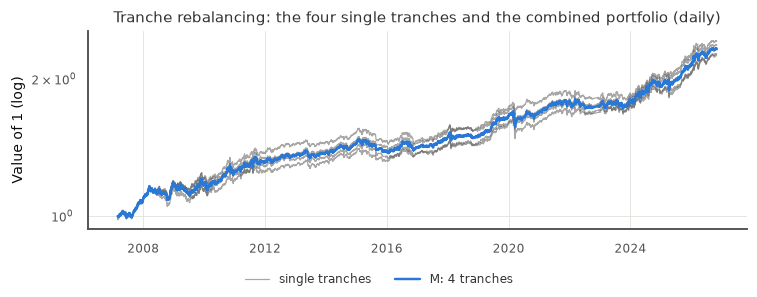

In [61]:
px_daily = clean_prices(prices_raw)[RISKY_ASSETS + [RF_TICKER]].ffill(limit=5)
RF_T0 = float(OFF_DATA[0].rf_m.shift(-1).loc[T0])  # T-bill rate on 28 Feb 2007: cash of tranches not yet invested
NAV_T, TO_T, W_T = {}, {}, {}
for k in tqdm(ICFG.tranche_offsets, desc="Tranches (daily backtest)"):
    dk = OFF_DATA[k]
    dates_k = dk.prices_m.index[dk.prices_m.index >= T0]
    W_T[k] = target_weights(dk, RISKY_ASSETS, dates_k, COV_WINDOW, SMA_WINDOW, True, WEIGHTING)
    rf_start_of_period = dk.rf_m.shift(-1)  # ^IRX on the decision day / 1200: earned until the next decision
    NAV_T[k], TO_T[k] = backtest_daily(W_T[k], px_daily[RISKY_ASSETS], rf_start_of_period, COST_BPS,
                                       start=T0, rf_start=RF_T0)

# Check 1: the daily engine reproduces the monthly engine for the month-end tranche (same data, same weights)
mon0 = backtest(W_T[0], OFF_DATA[0], COST_BPS)["net"]
nav0 = NAV_T[0].loc[W_T[0].index]
daily0 = (nav0 / nav0.shift(1) - 1.0).iloc[1:]
assert np.allclose(daily0.to_numpy(), mon0.to_numpy(), atol=1e-10), "daily engine must reproduce backtest()"
# Check 2: the month-end tranche is (almost) variant A; the only difference is how month-end prices are sampled
lab = lambda s: s.set_axis(s.index + pd.offsets.MonthEnd(0))
diff_A = (lab(daily0) - r_strat).abs().max()
print(f"Checks passed: daily engine = monthly engine (max diff {np.abs(daily0.to_numpy() - mon0.to_numpy()).max():.1e}); "
      f"month-end tranche vs variant A: max monthly difference {diff_A:.1e}")

month_ends = W_T[0].index  # last trading day of each month, from T0
combo = sum(0.25 * NAV_T[k] for k in ICFG.tranche_offsets)
combo_m = combo.loc[month_ends]
r_M = lab((combo_m / combo_m.shift(1) - 1.0).iloc[1:]).rename("M: 4 tranches")
assert r_M.index.equals(RETURN_MONTHS), "the tranche portfolio must cover the same months as A"
# turnover of the combined portfolio: value traded by each tranche as a share of the combined value
traded = sum(float((0.25 * NAV_T[k].loc[TO_T[k].index] * TO_T[k] / combo.loc[TO_T[k].index]).sum())
             for k in ICFG.tranche_offsets)
to_M = traded / (N_MONTHS / 12)

off = pd.DataFrame(off_rows).T
pM = performance_summary(r_M, data.rf_m)
in_range = (off["Strategy Sharpe"].min() <= pM["sharpe"] <= off["Strategy Sharpe"].max()) and (
    off["Strategy MDD %"].min() <= 100 * pM["max_dd"] <= off["Strategy MDD %"].max()
)
IMP["M: 4 tranches"] = {
    "returns": r_M,
    "turnover": None,
    "gates": gates_plus(r_M, extra=("inside single-day range", in_range)),
    "type": "rebalancing",
    "turnover_pa": to_M,
}
single = {}
for k in ICFG.tranche_offsets:
    nk = NAV_T[k].loc[month_ends]
    single[f"tranche {k} days before month-end"] = lab((nk / nk.shift(1) - 1.0).iloc[1:])
report("9.16 Single tranches and the combined portfolio (daily engine, month-end values, net of 10 bps)",
       perf_table({"A: Trend (base)": r_strat} | single | {"M: 4 tranches": r_M}))
report("9.16 Range of the single-day runs of Section 9.12 and turnover of the tranche portfolio",
       pd.DataFrame({"Sharpe": [off["Strategy Sharpe"].min(), off["Strategy Sharpe"].mean(), off["Strategy Sharpe"].max(), pM["sharpe"]],
                     "Max DD %": [off["Strategy MDD %"].min(), off["Strategy MDD %"].mean(), off["Strategy MDD %"].max(), 100 * pM["max_dd"]]},
                    index=["single-day runs: lowest", "single-day runs: mean", "single-day runs: highest", "M: 4 tranches"])
       .assign(**{"Turnover % p.a.": [np.nan, np.nan, np.nan, 100 * to_M]}))
report("9.16 Promotion gates (reference: A)", pd.DataFrame({"M: 4 tranches": IMP["M: 4 tranches"]["gates"]}).T)

fig, ax = plt.subplots(figsize=(FIG_W, 2.6), layout="constrained")
for k in ICFG.tranche_offsets:
    ax.plot(NAV_T[k].index, NAV_T[k], lw=0.8, color=INK_2, alpha=0.5, label="single tranches" if k == 0 else None)
ax.plot(combo.index, combo, lw=1.6, color=COLORS["Strategy"], label="M: 4 tranches")
ax.set_yscale("log")
ax.set_ylabel("Value of 1 (log)")
ax.set_title("Tranche rebalancing: the four single tranches and the combined portfolio (daily)")
legend_below(fig, ax, ncol=2)
plt.show()

<a id="sec-9-17"></a>

### 9.17 Out-of-sample test of the averaged trend signal (variant H) on 1992–2007 proxy data

Variant H (averaged 6–12-month trend signal) had a higher Sharpe ratio than A in-sample but failed the gates.
The clean way to decide is a **true out-of-sample test** on data this project has never used: the years before the
ETFs existed. Faber (2007) tests the same type of rule from 1973.

**Proxy data** (Yahoo Finance, daily, total return): Vanguard 500 Index (US equities), Vanguard European and Pacific
Stock Index 50/50 (developed ex-US equities), Vanguard Intermediate-Term Treasury (Treasuries), Fidelity Real Estate
(REITs), S&P GSCI plus the T-bill return (commodities, approximately a total-return index), and Vanguard Total Bond
Market (bond leg of 60/40). **Gold is left out**: there is no free daily gold price before 2000 on Yahoo Finance, and
the LBMA series were removed from FRED. The test therefore uses five of the six asset classes for both A and H.

**Design.** Only A and H, same engine, costs and gates; three stress periods fixed in advance (1994 bond sell-off,
Russia/LTCM 1998, dot-com bear market 2000–2002). One run. Pre-registered decision rule: if H passes, it is reported
as the preferred implementation; if not, A stays and H is reported as rejected.

In [62]:
tick_map = dict(ICFG.proxy_tickers)
proxy_list = ["VFINX", "VEURX", "VPACX", "VFITX", "FRESX", "^SPGSCI", "VBMFX", RF_TICKER]
proxy_raw = clean_prices(download_prices(proxy_list, ICFG.proxy_start, ICFG.proxy_end))
pr_d = proxy_raw.pct_change(fill_method=None)


def index_from_returns(r):
    """Price index (start 100) from daily returns; NaN before the first return."""
    first = r.first_valid_index()
    out = 100.0 * (1.0 + r.loc[first:].fillna(0.0)).cumprod()
    return out.reindex(r.index)


irx_daily = proxy_raw[RF_TICKER].ffill(limit=5).shift(1) / 100.0 / 252.0  # T-bill return per trading day
proxy_px = pd.DataFrame({
    "SPY": proxy_raw["VFINX"],
    "EFA": index_from_returns(0.5 * pr_d["VEURX"] + 0.5 * pr_d["VPACX"]),
    "IEF": proxy_raw["VFITX"],
    "VNQ": proxy_raw["FRESX"],
    "DBC": index_from_returns(pr_d["^SPGSCI"] + irx_daily),
    "AGG": proxy_raw["VBMFX"],
    RF_TICKER: proxy_raw[RF_TICKER],
})
P5 = ["SPY", "EFA", "IEF", "VNQ", "DBC"]
dp = build_market_data(proxy_px, P5, ["AGG"], RF_TICKER)
t0_p = first_decision_date(dp, P5, COV_WINDOW, max(TCFG.avg_windows))  # both signals need 12 months of SMA
dates_p = dp.prices_m.index[(dp.prices_m.index >= t0_p) & (dp.prices_m.index <= pd.Timestamp(ICFG.proxy_last_decision))]
assert dp.prices_m.index[-1] < T0 + pd.offsets.MonthEnd(1), "proxy data must end before the ETF sample"

WA_p = target_weights_x(dp, P5, dates_p, COV_WINDOW, SMA_WINDOW)
WH_p = target_weights_x(dp, P5, dates_p, COV_WINDOW, SMA_WINDOW, trend_mode="average")
rA_p = backtest(WA_p, dp, COST_BPS)["net"].rename("A: Trend (proxies)")
rH_p = backtest(WH_p, dp, COST_BPS)["net"].rename("H: averaged trend (proxies)")
r6040_p = backtest(constant_weights(BENCHMARK_6040, dates_p), dp, COST_BPS)["net"].rename("60/40 (proxies)")
PROXY_STRESS = {lbl: (a, b) for lbl, a, b in ICFG.proxy_stress}
assert all(pd.Timestamp(a) > rA_p.index[0] and pd.Timestamp(b) <= rA_p.index[-1] for a, b in PROXY_STRESS.values())

OOS = {"A: Trend (proxies)": rA_p, "H: averaged trend (proxies)": rH_p, "60/40 (proxies)": r6040_p}
oos_tab = {}
for k, r in OOS.items():
    p = performance_summary(r, dp.rf_m)
    oos_tab[k] = {"CAGR %": 100 * p["cagr"], "Vol %": 100 * p["ann_vol"], "Sharpe": p["sharpe"],
                  "Max DD %": 100 * p["max_dd"], "Worst 12m %": 100 * p["worst_12m"],
                  **{lbl: 100 * stress_return(r, a, b) for lbl, (a, b) in PROXY_STRESS.items()}}
report(f"9.17 Out-of-sample test on proxies, {rA_p.index[0]:%b %Y}-{rA_p.index[-1]:%b %Y} "
       f"({len(rA_p)} months, five asset classes, net of 10 bps; stress columns in %)", pd.DataFrame(oos_tab).T)
G_H_OOS = gate_check(rH_p, rA_p, PROXY_STRESS, 2, rf=dp.rf_m)
report("9.17 Promotion gates of variant H out of sample (reference: A on the same proxy data)",
       pd.DataFrame({"H out of sample": G_H_OOS}).T)
IMP["H out of sample (proxies)"] = {"returns": None, "turnover": None, "gates": G_H_OOS, "type": "out-of-sample"}


=== 9.17 Out-of-sample test on proxies, Nov 1992-Feb 2007 (172 months, five asset classes, net of 10 bps; stress columns in %) ===
                             CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  1994 bond sell-off  Russia / LTCM  Dot-com bear market
A: Trend (proxies)             9.76   4.72    1.21     -4.29         0.13                0.86           1.71                17.32
H: averaged trend (proxies)    9.24   4.60    1.13     -4.29        -1.62               -0.89           1.87                17.58
60/40 (proxies)                9.23   8.42    0.65    -23.50       -12.70               -3.96          -4.18               -23.50


=== 9.17 Promotion gates of variant H out of sample (reference: A on the same proxy data) ===
                Sharpe Sharpe A Sharpe >= A MDD % MDD A % MDD not deeper stress wins PROMOTED
H out of sample   1.13     1.21       False -4.29   -4.29           True      2 of 3    False



<a id="sec-9-18"></a>

### 9.18 Inflation-linked Treasuries (TIP) as a seventh asset class

TIPS are linked to US consumer prices, so they suffer less than nominal Treasuries when inflation surprises,
which caused the joint fall of bonds and equities in 2022. **Variant N** adds TIP to the six asset classes; everything
else is unchanged and the backtest still starts in February 2007. *Caveat stated in advance:* the asset class is
added after seeing 2022, which is a form of hindsight; the economic argument has to carry the case.

In [63]:
tip_raw = clean_prices(download_prices([ICFG.tip_ticker], START, END))
data7 = build_market_data(pd.concat([clean_prices(prices_raw), tip_raw], axis=1),
                          RISKY_ASSETS + [ICFG.tip_ticker], OTHER_TICKERS, RF_TICKER)
A7 = RISKY_ASSETS + [ICFG.tip_ticker]
assert first_decision_date(data7, A7, COV_WINDOW, SMA_WINDOW) <= T0, "TIP must not move the backtest start"
run7 = run_strategy(data7, A7, COV_WINDOW, SMA_WINDOW, True, WEIGHTING, COST_BPS, start_decision=T0)
r_N = run7["returns"].rename("N: + TIP")
assert r_N.index.equals(RETURN_MONTHS)
IMP["N: + TIP (7 assets)"] = {"returns": r_N, "turnover": run7["result"]["turnover"],
                               "gates": gates_plus(r_N), "type": "universe"}
report("9.18 Seven asset classes incl. TIP (net of 10 bps)",
       perf_table({"A: Trend (base)": r_strat, "N: + TIP (7 assets)": r_N},
                  {"A: Trend (base)": base["result"]["turnover"], "N: + TIP (7 assets)": run7["result"]["turnover"]}))
w7 = pd.DataFrame({"A: Trend (base)": W_A.mean(), "N: + TIP (7 assets)": run7["weights"].mean()}).fillna(0.0) * 100
report("9.18 Average target weights (%)", w7, "{:.1f}")
report("9.18 Cumulative return in the stress periods (%)",
       pd.DataFrame({lbl: {k: 100 * stress_return(r, a, b) for k, r in {"A: Trend (base)": r_strat, "N: + TIP (7 assets)": r_N}.items()}
                     for lbl, (a, b) in PERIODS_STRESS.items()}), "{:.1f}")
report("9.18 Promotion gates (reference: A)", pd.DataFrame({"N: + TIP (7 assets)": IMP["N: + TIP (7 assets)"]["gates"]}).T)


=== 9.18 Seven asset classes incl. TIP (net of 10 bps) ===
                     CAGR %  Vol %  Sharpe  Max DD %  Worst 12m %  Final $1  Turnover % p.a.
A: Trend (base)        4.59   4.71    0.66     -5.65        -5.65      2.42           215.68
N: + TIP (7 assets)    4.29   4.20    0.66     -5.34        -4.98      2.29           211.56


=== 9.18 Average target weights (%) ===
      A: Trend (base)  N: + TIP (7 assets)
CASH             31.7                 30.2
DBC               6.2                  5.0
EFA               6.4                  5.3
GLD               7.8                  6.2
IEF              33.1                 22.1
SPY               9.1                  7.6
TIP               0.0                 18.9
VNQ               5.6                  4.6


=== 9.18 Cumulative return in the stress periods (%) ===
                     Financial crisis  Covid crash  Inflation and rate shock  Recovery
A: Trend (base)                   9.2          0.1                      -3.4      33.6

<a id="sec-9-19"></a>

### 9.19 Leverage with cheaper financing and a lower cap (sensitivity, not a new strategy)

Section 9.8 borrowed at T-bills + 0.5%. With Treasury futures the implicit financing cost is closer to T-bills +
0.1–0.2%; for private clients a cap of 2× is more realistic than 4×. The table reruns the 10%-volatility variant for
every combination. It is meant for the client discussion of Section 6, not as a strategy.

In [64]:
lev_grid = {}
for cap in ICFG.lev_caps:
    for spread in ICFG.lev_spreads:
        r_L, L_ret = levered_returns(W_chk, r_strat, ICFG.lev_target, cap=cap, spread=spread)
        p = performance_summary(r_L, data.rf_m)
        lev_grid[(f"cap {cap:.0f}x", f"T-bills + {100 * spread:.2f}%")] = {
            "CAGR %": 100 * p["cagr"], "Vol %": 100 * p["ann_vol"], "Sharpe": p["sharpe"],
            "Max DD %": 100 * p["max_dd"], "avg leverage": L_ret.mean()}
LEV_GRID = pd.DataFrame(lev_grid).T
p6 = performance_summary(r_6040, data.rf_m)
report(f"9.19 Strategy levered to {ICFG.lev_target:.0%} volatility: financing cost and leverage cap "
       f"(60/40: CAGR {100 * p6['cagr']:.1f}%, Sharpe {p6['sharpe']:.2f}, Max DD {100 * p6['max_dd']:.1f}%)", LEV_GRID)


=== 9.19 Strategy levered to 10% volatility: financing cost and leverage cap (60/40: CAGR 7.9%, Sharpe 0.67, Max DD -32.3%) ===
                        CAGR %  Vol %  Sharpe  Max DD %  avg leverage
cap 4x T-bills + 0.00%    7.66   9.60    0.66    -16.57          2.20
       T-bills + 0.10%    7.61   9.60    0.66    -16.63          2.20
       T-bills + 0.25%    7.53   9.59    0.65    -16.72          2.20
       T-bills + 0.50%    7.39   9.59    0.64    -16.87          2.20
cap 2x T-bills + 0.00%    6.94   8.02    0.69    -11.10          1.79
       T-bills + 0.10%    6.90   8.02    0.69    -11.13          1.79
       T-bills + 0.25%    6.85   8.02    0.68    -11.17          1.79
       T-bills + 0.50%    6.76   8.02    0.67    -11.23          1.79



<a id="sec-9-20"></a>

### 9.20 The strategy for a EUR investor: unhedged, bonds and cash hedged, fully hedged

The prospectus recommends EUR-hedged bond and cash sleeves for euro clients. Here the strategy (variant A, same
weights and costs) and 60/40 are measured in euros:

* **unhedged:** every USD return is converted at the EUR/USD rate, $(1+R)\,S_{t-1}/S_t - 1$ ($S$ = USD per EUR);
* **hedged sleeve:** a one-month currency forward earns the interest-rate difference (covered interest parity),
  $R + r_{EUR} - r_{USD}$, with both rates known at the start of the month;
* **bonds and cash hedged** (IEF, AGG and T-bills), the rest unhedged; and **fully hedged**.

Sharpe ratios use the euro-area 3-month interbank rate (OECD, via FRED) as the risk-free rate. The OECD publishes it
with a lag of several months, so this comparison ends with the last month that has a rate (the period is printed in
the table title). If FRED cannot be reached and no cached copy exists, only the unhedged returns are shown.

In [65]:
fx_raw = clean_prices(download_prices([ICFG.fx_ticker], START, END))
fx_m = to_month_end(fx_raw[ICFG.fx_ticker].ffill(limit=5))
fx_factor = (fx_m.shift(1) / fx_m).reindex(RETURN_MONTHS)  # USD -> EUR conversion of month t
assert fx_factor.notna().all(), "EUR/USD rate missing"


def fred_series(series_id):
    """Monthly FRED series (cached in notebook/cache/). Returns None if it cannot be downloaded."""
    path = CACHE_DIR / f"fred_{series_id}.csv"
    if not (USE_CACHE and path.exists()):
        try:
            resp = requests.get(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}",
                                headers=HDRS, timeout=30)
            resp.raise_for_status()
        except requests.RequestException as exc:
            print(f"FRED download of {series_id} failed: {exc}")
            return None
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(resp.text, encoding="utf-8")
    df = pd.read_csv(path)
    s = pd.to_numeric(df.iloc[:, 1], errors="coerce")
    s.index = pd.to_datetime(df.iloc[:, 0]) + pd.offsets.MonthEnd(0)
    return s.dropna().rename(series_id)


def eur_returns(W, res, hedged, fx_factor, rf_eur):
    """Monthly net returns in EUR of a backtest result `res` with target weights W (decided at t, earned in t+1).
    Columns in `hedged` earn R + r_EUR - r_USD, the others are converted at the EUR/USD rate."""
    months = res.index
    assets = [c for c in W.columns if c != "CASH"]
    R = data.rets_m.reindex(index=months, columns=assets).fillna(0.0)
    R["CASH"] = data.rf_m.reindex(months)
    w = pd.DataFrame(W.iloc[: len(months)].to_numpy(), index=months, columns=W.columns)[R.columns]
    R_eur = (1.0 + R).mul(fx_factor.reindex(months), axis=0) - 1.0
    if hedged:
        carry = (rf_eur.reindex(months) - data.rf_m.reindex(months))
        for c in [c for c in hedged if c in R.columns]:
            R_eur[c] = R[c] + carry
    gross = (w * R_eur).sum(axis=1)
    return (1.0 - res["cost"]) * (1.0 + gross) - 1.0


# check: without currency effects the EUR engine reproduces the USD returns
one = pd.Series(1.0, index=RETURN_MONTHS)
assert np.allclose(eur_returns(W_A, base["result"], (), one, None), r_strat, atol=1e-12)

eur_rate = fred_series(ICFG.eur_rate_fred)
rf_eur = None if eur_rate is None else (eur_rate / 1200).shift(1).reindex(RETURN_MONTHS)
# The OECD series is published with a lag of several months: the EUR comparison uses the months with a rate
EUR_MONTHS = RETURN_MONTHS if rf_eur is None else RETURN_MONTHS[rf_eur.notna().to_numpy()]
EUR_AVAILABLE = (rf_eur is not None and len(EUR_MONTHS) >= 0.9 * len(RETURN_MONTHS)
                 and EUR_MONTHS.equals(RETURN_MONTHS[: len(EUR_MONTHS)]))  # no gaps, only a missing end
W_6040 = constant_weights(BENCHMARK_6040, DECISION_DATES)
EUR_RETS = {"Strategy, unhedged": eur_returns(W_A, base["result"], (), fx_factor, rf_eur),
            "60/40, unhedged": eur_returns(W_6040, base["benchmark_result"], (), fx_factor, rf_eur)}
if EUR_AVAILABLE:
    EUR_RETS |= {
        "Strategy, bonds + cash hedged": eur_returns(W_A, base["result"], ICFG.hedged_sleeves, fx_factor, rf_eur),
        "Strategy, fully hedged": eur_returns(W_A, base["result"], tuple(W_A.columns), fx_factor, rf_eur),
        "60/40, bonds hedged": eur_returns(W_6040, base["benchmark_result"], ICFG.hedged_sleeves, fx_factor, rf_eur),
        "60/40, fully hedged": eur_returns(W_6040, base["benchmark_result"], tuple(W_6040.columns), fx_factor, rf_eur),
    }
    eur_tab = {}
    for k, r in EUR_RETS.items():
        p = performance_summary(r.loc[EUR_MONTHS], rf_eur)
        eur_tab[k] = {"CAGR %": 100 * p["cagr"], "Vol %": 100 * p["ann_vol"], "Sharpe (EUR rf)": p["sharpe"],
                      "Max DD %": 100 * p["max_dd"], "Worst 12m %": 100 * p["worst_12m"]}
    report(f"9.20 Strategy and 60/40 for a EUR investor, {EUR_MONTHS[0]:%b %Y}-{EUR_MONTHS[-1]:%b %Y} "
           f"({len(EUR_MONTHS)} months with a EUR rate; net, EUR risk-free rate {12 * rf_eur.loc[EUR_MONTHS].mean():.1%} p.a. on average)",
           pd.DataFrame(eur_tab).T)
else:
    eur_tab = {k: {"CAGR %": 100 * performance_summary(r, data.rf_m)["cagr"],
                   "Vol %": 100 * performance_summary(r, data.rf_m)["ann_vol"],
                   "Max DD %": 100 * max_drawdown(r)} for k, r in EUR_RETS.items()}
    report("9.20 Strategy and 60/40 for a EUR investor, unhedged only (EUR interest rate not available)",
           pd.DataFrame(eur_tab).T)


=== 9.20 Strategy and 60/40 for a EUR investor, Mar 2007-Jan 2026 (227 months with a EUR rate; net, EUR risk-free rate 1.1% p.a. on average) ===
                               CAGR %  Vol %  Sharpe (EUR rf)  Max DD %  Worst 12m %
Strategy, unhedged               5.11   8.42             0.51    -11.66        -9.76
60/40, unhedged                  8.49  10.15             0.74    -26.36       -18.64
Strategy, bonds + cash hedged    4.82   4.33             0.87     -5.31        -4.92
Strategy, fully hedged           4.17   4.68             0.68     -6.61        -5.71
60/40, bonds hedged              8.10   8.96             0.79    -26.89       -18.30
60/40, fully hedged              7.53   9.83             0.68    -29.55       -25.12



<a id="sec-9-21"></a>

### 9.21 Verdict, deflated Sharpe ratio and number register

Every additional variant raises the chance that one of them wins by luck. The **deflated Sharpe ratio** (Bailey and
López de Prado, 2014) corrects the base strategy's Sharpe ratio for the number of variants tried in this notebook
(Sections 9, 9.6–9.13 and 9.14–9.20) and for skewness and fat tails of its returns. It is the probability that the
strategy's true Sharpe ratio is above zero after this correction.

In [66]:
imp_verdict = {}
for k, v in IMP.items():
    g = v["gates"]
    imp_verdict[k] = {"type": v["type"], "PROMOTED": g["PROMOTED"], "Sharpe": g["Sharpe"], "Sharpe A": g["Sharpe A"],
                      "MDD %": g["MDD %"], "MDD A %": g["MDD A %"], "stress wins": g["stress wins"]}
report("9.21 Summary of the improvement tests (each against A on the same data)", pd.DataFrame(imp_verdict).T)

# deflated Sharpe ratio of the base strategy: all variants tried so far
full_sample = {k: r for k, r in (ml_ret | RETS | {k: v["returns"] for k, v in IMP.items() if v["returns"] is not None}).items()
               if k not in ("60/40", "ERC (no trend)", "HRP (no trend)") and r.index.equals(RETURN_MONTHS)}
sr_trials = [float(((r - data.rf_m.reindex(r.index)).mean()) / (r - data.rf_m.reindex(r.index)).std(ddof=1))
             for r in full_sample.values()]
N_TRIALS = len(ML_KEYS) + int(len(verdict)) + len(IMP)  # Section 9 (A-D) + Sections 9.6-9.13 + Sections 9.14-9.20
DSR_A, SR0_A, SR_A = deflated_sharpe(r_strat, data.rf_m, sr_trials, N_TRIALS)
report("9.21 Deflated Sharpe ratio of the base strategy",
       pd.Series({"variants tried": N_TRIALS, "variants with full-sample returns (for the spread)": len(sr_trials),
                  "Sharpe ratio of A (annualised)": SR_A,
                  "expected best Sharpe ratio of unskilled variants (annualised)": SR0_A,
                  "deflated Sharpe ratio = P(true Sharpe > 0)": DSR_A}), "{:.3f}")

# ---------------------------------------------------------------- number register (Sections 9.14-9.21)
SRC = RISKY_ASSETS + [RF_TICKER]
register("imp_turnover_a", to_A, "pct0", "Base strategy: turnover p.a.", "9.15", SRC)
register("imp_breakeven_a", c_A if np.isfinite(c_A) else "none", "bps0" if np.isfinite(c_A) else "text", "Base strategy: break-even cost against 60/40", "9.15", SRC + ["SPY", "AGG"])
for key, name in [("j", "J: hysteresis 2%"), ("k", "K: no-trade band 2 pp"), ("l", "L: hysteresis + band")]:
    v, p = IMP[name], performance_summary(IMP[name]["returns"], data.rf_m)
    register(f"imp_{key}_sharpe", p["sharpe"], "num2", f"{name}: Sharpe ratio", "9.15", SRC)
    register(f"imp_{key}_maxdd", p["max_dd"], "pct1", f"{name}: maximum drawdown", "9.15", SRC)
    register(f"imp_{key}_turnover", v["turnover_pa"], "pct0", f"{name}: turnover p.a.", "9.15", SRC)
    register(f"imp_{key}_breakeven", v["be_bps"] if np.isfinite(v["be_bps"]) else "none",
             "bps0" if np.isfinite(v["be_bps"]) else "text", f"{name}: break-even cost against 60/40", "9.15", SRC + ["SPY", "AGG"])
    register(f"imp_{key}_verdict", "passes" if v["gates"]["PROMOTED"] else "fails", "text",
             f"{name}: result of the pre-registered gates", "9.15", SRC)
register("imp_m_sharpe", pM["sharpe"], "num2", "M (4 tranches): Sharpe ratio", "9.16", SRC)
register("imp_m_maxdd", pM["max_dd"], "pct1", "M (4 tranches): maximum drawdown", "9.16", SRC)
register("imp_m_turnover", to_M, "pct0", "M (4 tranches): turnover p.a.", "9.16", SRC)
register("imp_m_verdict", "passes" if IMP["M: 4 tranches"]["gates"]["PROMOTED"] else "fails", "text",
         "M (4 tranches): result of the pre-registered gates", "9.16", SRC)
SRC_P = ["VFINX", "VEURX", "VPACX", "VFITX", "FRESX", "^SPGSCI", RF_TICKER]
register("imp_oos_start", rA_p.index[0], "date", "Out-of-sample test: first month", "9.17", SRC_P)
register("imp_oos_end", rA_p.index[-1], "date", "Out-of-sample test: last month", "9.17", SRC_P)
for key, name in [("a", "A: Trend (proxies)"), ("h", "H: averaged trend (proxies)"), ("6040", "60/40 (proxies)")]:
    p = performance_summary(OOS[name], dp.rf_m)
    register(f"imp_oos_{key}_sharpe", p["sharpe"], "num2", f"Out-of-sample {name}: Sharpe ratio", "9.17", SRC_P)
    register(f"imp_oos_{key}_maxdd", p["max_dd"], "pct1", f"Out-of-sample {name}: maximum drawdown", "9.17", SRC_P)
register("imp_oos_h_verdict", "passes" if G_H_OOS["PROMOTED"] else "fails", "text",
         "Out-of-sample: variant H, result of the pre-registered gates", "9.17", SRC_P)
pN = performance_summary(r_N, data.rf_m)
register("imp_tip_sharpe", pN["sharpe"], "num2", "N (+ TIP): Sharpe ratio", "9.18", SRC + [ICFG.tip_ticker])
register("imp_tip_maxdd", pN["max_dd"], "pct1", "N (+ TIP): maximum drawdown", "9.18", SRC + [ICFG.tip_ticker])
register("imp_tip_2022", stress_return(r_N, *PERIODS_STRESS["Inflation and rate shock"]), "pct1",
         "N (+ TIP): return in the 2022 inflation and rate shock", "9.18", SRC + [ICFG.tip_ticker])
register("imp_tip_weight", run7["weights"][ICFG.tip_ticker].mean(), "pct0", "N (+ TIP): average TIP weight",
         "9.18", SRC + [ICFG.tip_ticker])
register("imp_tip_verdict", "passes" if IMP["N: + TIP (7 assets)"]["gates"]["PROMOTED"] else "fails", "text",
         "N (+ TIP): result of the pre-registered gates", "9.18", SRC + [ICFG.tip_ticker])
for cap in ICFG.lev_caps:
    for spread in (ICFG.lev_spreads[0], ICFG.lev_spreads[1]):
        row = LEV_GRID.loc[(f"cap {cap:.0f}x", f"T-bills + {100 * spread:.2f}%")]
        key = f"imp_lev_cap{cap:.0f}_s{round(1e4 * spread)}"
        register(f"{key}_cagr", row["CAGR %"] / 100, "pct1", f"Levered to 10% vol, cap {cap:.0f}x, spread {1e4 * spread:.0f} bps: CAGR", "9.19", SRC)
        register(f"{key}_sharpe", row["Sharpe"], "num2", f"Levered to 10% vol, cap {cap:.0f}x, spread {1e4 * spread:.0f} bps: Sharpe ratio", "9.19", SRC)
        register(f"{key}_maxdd", row["Max DD %"] / 100, "pct1", f"Levered to 10% vol, cap {cap:.0f}x, spread {1e4 * spread:.0f} bps: max drawdown", "9.19", SRC)
SRC_EUR = SRC + ["SPY", "AGG", ICFG.fx_ticker]
for key, name in [("unh", "Strategy, unhedged"), ("hed", "Strategy, bonds + cash hedged"), ("full", "Strategy, fully hedged"),
                  ("6040_unh", "60/40, unhedged"), ("6040_hed", "60/40, bonds hedged")]:
    if name in eur_tab:
        register(f"imp_eur_{key}_maxdd", eur_tab[name]["Max DD %"] / 100, "pct1", f"EUR investor, {name}: max drawdown", "9.20", SRC_EUR)
        register(f"imp_eur_{key}_cagr", eur_tab[name]["CAGR %"] / 100, "pct1", f"EUR investor, {name}: CAGR", "9.20", SRC_EUR)
        if "Sharpe (EUR rf)" in eur_tab[name]:
            register(f"imp_eur_{key}_sharpe", eur_tab[name]["Sharpe (EUR rf)"], "num2", f"EUR investor, {name}: Sharpe ratio", "9.20", SRC_EUR)
if EUR_AVAILABLE:
    register("imp_eur_start", EUR_MONTHS[0], "date", "EUR investor: first month", "9.20", SRC_EUR)
    register("imp_eur_end", EUR_MONTHS[-1], "date", "EUR investor: last month with a EUR interest rate", "9.20", SRC_EUR)
register("imp_n_variants", len(IMP), "int", "Variants tested in Sections 9.15-9.18", "9.21", SRC)
register("imp_n_promoted", int(sum(v["gates"]["PROMOTED"] for v in IMP.values())), "int",
         "Improvement variants that pass their gates", "9.21", SRC)
register("imp_n_trials", N_TRIALS, "int", "Variants tried in the whole notebook (deflated Sharpe ratio)", "9.21", SRC)
register("imp_dsr_a", DSR_A, "pct1", "Deflated Sharpe ratio of the base strategy", "9.21", SRC)

header = (f"Group Z extended tests (Sections 9.6-9.21) - results\nData retrieved: {RETRIEVED_TXT}\n"
          f"Sample: {RETURN_MONTHS[0]:%b %Y}-{RETURN_MONTHS[-1]:%b %Y}, costs {COST_BPS:.0f} bps\n")
Path("groupz_test_results.txt").write_text(header + "".join(RESULTS_TXT), encoding="utf-8")
print("Saved groupz_test_results.txt (now including Sections 9.14-9.21)")
if IN_COLAB:
    from google.colab import files

    files.download("groupz_test_results.txt")


=== 9.21 Summary of the improvement tests (each against A on the same data) ===
                                    type PROMOTED Sharpe Sharpe A MDD % MDD A % stress wins
J: hysteresis 2%                turnover    False   0.60     0.66 -5.62   -5.65      2 of 3
K: no-trade band 2 pp           turnover    False   0.66     0.66 -5.82   -5.65      3 of 3
L: hysteresis + band            turnover    False   0.60     0.66 -5.61   -5.65      2 of 3
M: 4 tranches                rebalancing    False   0.62     0.66 -6.01   -5.65      1 of 3
H out of sample (proxies)  out-of-sample    False   1.13     1.21 -4.29   -4.29      2 of 3
N: + TIP (7 assets)             universe    False   0.66     0.66 -5.34   -5.65      1 of 3


=== 9.21 Deflated Sharpe ratio of the base strategy ===
variants tried                                                  24.000
variants with full-sample returns (for the spread)              22.000
Sharpe ratio of A (annualised)                                   0.658
expe

**Observation ledger (Sections 9.14–9.21).** The first full run (23 Nov 2026) gave:

| | |
| --- | --- |
| Change | hysteresis and no-trade bands (J, K, L), four rebalancing tranches (M), an out-of-sample test of the averaged trend signal on 1992–2007 proxy data, TIP as a seventh asset class (N), a leverage-financing sensitivity and a EUR-investor view |
| Turnover | the hysteresis band cuts turnover by about 40% and passes the turnover gate, but it sells and buys back later and lowers the Sharpe ratio, so J and L fail the Sharpe gate. The no-trade band hardly lowers turnover, because most of the turnover comes from trend switches, which are always executed |
| Rebalancing day | the tranche portfolio lies inside the range of the single-day runs, close to their average, as intended. It is below the month-end strategy, which confirms that the month-end result is at the favourable end of the range; a client who rebalances on another day should expect a Sharpe ratio closer to the average |
| Out of sample | on 1992–2007 proxy data variant H does not beat A (lower Sharpe ratio, same drawdown), so H is rejected. Both rules again have a far smaller drawdown than 60/40, which supports the prospectus claim on data the project had not used |
| TIP | same Sharpe ratio and a slightly smaller drawdown, but almost no effect in 2022 and only one of three stress periods better, so N fails the gates |
| Leverage and EUR | cheaper financing changes little; a 2× cap keeps much less drawdown than 60/40 at a lower volatility. The EUR table shows how much of the risk of a euro client comes from the dollar, and what hedging bonds and cash changes |
| Number of trials | the deflated Sharpe ratio of the base strategy stays close to one after counting every variant tried in this notebook |
| Decision | no improvement variant passes its gates; the prospectus strategy stays unchanged (team decision: passing variants would only be reported as implementation options) |

<a id="sec-10"></a>
## 10 Number register and export

The register lists every number, table and figure used in the prospectus with its description, the
notebook section that computes it, the data source and the retrieval time. A local run writes:
* `prospectus/results_macros.tex` – one `\defres{...}` line per entry (read by `resultref.sty`),
* `prospectus/figures/*.pdf`, `prospectus/tables/*.tex` – figures and tables of the prospectus,
* `results/results.json` – the headline numbers, used by the app's consistency test.

In [67]:
checkpoint("10 Export")
def source_text(tickers):
    tickers = list(dict.fromkeys(tickers))
    if not tickers:
        return "Model assumption"
    if set(tickers) >= set(ALL_TICKERS):
        return "YF: all 9 series"
    if set(RISKY_ASSETS) <= set(tickers):     # abbreviate the six strategy ETFs
        tickers = ["6 ETFs"] + [t for t in tickers if t not in RISKY_ASSETS]
    return "YF: " + ", ".join(tickers)


reg_df = pd.DataFrame([{"key": e["key"], "value": e["value"], "description": e["description"],
                        "notebook section": "§" + e["section"], "source": source_text(e["sources"]),
                        "retrieved": RETRIEVED_TXT if e["sources"] else "–"} for e in REGISTER])
print(f"{len(reg_df)} registered results")
reg_df

280 registered results


,key,value,description,notebook section,source,retrieved
0,data_retrieved,2026-11-23 22:49 UTC,Time stamp of the Yahoo Finance download,§1,YF: all 9 series,2026-11-23 22:49 UTC
1,data_start,01 Jan 2006,First day of daily data requested,§0.2,YF: all 9 series,2026-11-23 22:49 UTC
2,data_end,30 Oct 2026,Last trading day in the sample,§2,YF: all 9 series,2026-11-23 22:49 UTC
3,first_decision,28 Feb 2007,First rebalancing date (decision at the close),§3,YF: 6 ETFs,2026-11-23 22:49 UTC
4,sample_start,Mar 2007,First month with a strategy return,§3,YF: 6 ETFs,2026-11-23 22:49 UTC
...,...,...,...,...,...,...
275,imp_eur_end,Jan 2026,EUR investor: last month with a EUR interest rate,§9.20,"YF: 6 ETFs, ^IRX, AGG, EURUSD=X",2026-11-23 22:49 UTC
276,imp_n_variants,6,Variants tested in Sections 9.15-9.18,§9.21,"YF: 6 ETFs, ^IRX",2026-11-23 22:49 UTC
277,imp_n_promoted,0,Improvement variants that pass their gates,§9.21,"YF: 6 ETFs, ^IRX",2026-11-23 22:49 UTC
278,imp_n_trials,24,Variants tried in the whole notebook (deflated...,§9.21,"YF: 6 ETFs, ^IRX",2026-11-23 22:49 UTC


In [68]:
if EXPORT:
    lines = ["% AUTO-GENERATED by notebook/GroupZ_RiskParity_Trend.ipynb (Section 9). Do not edit.",
             f"% Data retrieved from Yahoo Finance via yfinance: {RETRIEVED_TXT}",
             r"% \defres{key}{value}{description}{notebook section}{link}{source}{retrieved}"]
    for e in REGISTER:
        anchor = "sec-" + e["section"].replace(".", "-")
        link = NOTEBOOK_VIEW_URL + r"\#" + anchor
        retrieved = DATA_RETRIEVED_UTC.strftime("%Y-%m-%d") if e["sources"] else "--"
        lines.append(rf"\defres{{{e['key']}}}{{{e['tex']}}}{{{tex_escape(e['description'])}}}"
                     rf"{{\S{e['section']}}}{{{link}}}{{{tex_escape(source_text(e['sources']))}}}{{{retrieved}}}")
    (REPO_ROOT / "prospectus" / "results_macros.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

    results = {"retrieved_utc": RETRIEVED_TXT, "start": START, "end": END, "first_decision": str(T0.date()),
               "params": {"cov_window": COV_WINDOW, "sma_window": SMA_WINDOW, "cost_bps": COST_BPS,
                          "weighting": WEIGHTING},
               "strategy": {k: float(v) for k, v in P.items()},
               "benchmark_6040": {k: float(v) for k, v in B.items()}}
    (REPO_ROOT / "results").mkdir(exist_ok=True)
    (REPO_ROOT / "results" / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    print("exported:", sorted(p.name for p in FIG_DIR.iterdir()), sorted(p.name for p in TAB_DIR.iterdir()))
else:
    print("Not exporting (Colab or outside the repository) - all results are shown above.")

exported: ['fig_cumulative.pdf', 'fig_drawdowns.pdf', 'fig_regimes.pdf', 'fig_sensitivity.pdf', 'fig_weights.pdf'] ['tab_leave_one_out.tex', 'tab_ml.tex', 'tab_performance.tex']


<a id="sec-11"></a>
## 11 Runtime

How long each section took in this run (machine-learning fits dominate). The PDF copy of the executed
notebook (`notebook/GroupZ_RiskParity_Trend.pdf`) shows these results without re-running anything.

In [69]:
checkpoint("end")
runtime = pd.DataFrame([(label, t1 - t0) for (label, t0), (_, t1) in zip(CHECKPOINTS[:-1], CHECKPOINTS[1:])],
                       columns=["section", "seconds"]).groupby("section", sort=False, as_index=False).sum()
runtime["share"] = runtime["seconds"] / runtime["seconds"].sum()
total = CHECKPOINTS[-1][1] - RUN_START
print(f"Total runtime: {total / 60:.1f} minutes ({total:.0f} s)")
runtime.style.format({"seconds": "{:.1f}", "share": "{:.0%}"}).hide(axis="index")

Total runtime: 1.0 minutes (58 s)


section,seconds,share
0 Setup,0.0,0%
1 Extract,1.0,2%
2 Transform,0.3,1%
3-4 Load and strategy engine,0.1,0%
5 Benchmarks,0.7,1%
6 Results,0.8,1%
7 Verification,0.5,1%
8 Robustness,9.6,17%
9 ML extension,9.6,17%
9.6 Extended tests,20.0,35%
